# Лекція 4. Розвідувальний аналіз даних: візуальна грамотність та часові ряди

### Розширений зошит для самостійного опрацювання

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**

---

Уся лекція побудована як розв'язання **однієї задачі**. Спершу її умова, потім розв'язання.

## Як користуватися цим зошитом

Це **розширений зошит для самостійного вивчення**. Він містить той самий код і ті самі обчислення,
що й демонстрація на лекції, але з повним теоретичним викладом: означеннями, формулами
та поясненнями, звідки береться кожне твердження.

**Порядок роботи, який я раджу:**

1. Виконайте весь зошит одразу (*Kernel → Restart & Run All*). Це займає близько двадцяти секунд.
2. Читайте послідовно. Зошит побудовано як розслідування: **умова задачі, потім п'ять кроків розв'язання**,
   де кожен крок спростовує проміжну відповідь попереднього,
   тому пропуск розділу зробить наступний незрозумілим.
3. Коли натрапите на блок **❓ Питання** — **зупиніться й спробуйте відповісти самостійно**,
   перш ніж розгортати відповідь. Відповідь схована навмисно: цінність цих питань саме
   в кількох хвилинах власного роздуму.
4. Наприкінці є **глосарій**, **вісімнадцять питань для самоперевірки**
   та перелік літератури з позначенням, який розділ відповідає якому кроку.
5. Змінюйте код. Найкорисніше, що можна зробити із цим зошитом, — підставити інший товар,
   іншу область, інший період і подивитися, чи збережеться висновок.

**Що треба знати заздалегідь:** основи `pandas` (`DataFrame`, `Series`, індексація, `groupby`),
основи `matplotlib`, типи шкал вимірювання з лекції 3 та поняття кореляції.
Усе інше пояснюється тут.

**Позначення у формулах:** $y_t$ — значення ряду в момент $t$; $\hat y_t$ — прогноз цього значення;
$n$ — кількість спостережень; $m$ — довжина сезонного періоду (тут 12 місяців);
$h$ — горизонт прогнозу, тобто на скільки кроків уперед ми прогнозуємо.

---
# ЗАДАЧА

> # Чи подорожчала їжа в Україні у 2014–2017 роках?

---

## Дано

| Файл | Що це | Обсяг |
|---|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця | 29 091 рядок, 03.2014 – 12.2017 |
| `курс_євро_1990_2021.csv` | Офіційний місячний курс гривні до євро | 383 місяці, 01.1990 – 11.2021 |

Джерело цін — **World Food Programme, Global Food Prices Database** (ліцензія CC BY-IGO).
Джерело курсів — **fxtop.com** на основі даних центральних банків.
Це справжні дані з усіма їхніми справжніми вадами: жодне значення не вигадане й не підправлене,
жоден пропуск не заповнено заздалегідь.

## Потрібно

1. **Дати обґрунтовану відповідь** на поставлене питання.
2. **Показати, на чому вона ґрунтується:** які саме обчислення й графіки до неї ведуть.
3. **Оцінити, наскільки їй можна вірити:** назвати припущення, за яких вона правильна,
   і межі, за якими вона перестає бути правильною.

## Вимоги до розв'язання

* кожне твердження підкріплене обчисленням, яке можна відтворити;
* для кожного графіка пояснено, **чому обрано саме таку форму**, а не іншу;
* перед будь-яким прогнозом наведено результат найпростішого можливого методу;
* висновок супроводжується переліком обмежень.

## Чому задача складніша, ніж здається

Питання виглядає дитячим: візьми ціну на початку, візьми ціну в кінці, поділи.
Ми зробимо саме так — і отримаємо відповідь за одну хвилину.

А потім витратимо решту лекції на те, щоб з'ясувати, чому ця відповідь неправильна.
Усього ми відповімо на питання **чотири рази**, і **правильною буде лише остання відповідь**.
Жодна з попередніх не міститиме неправдивих чисел або помилок в обчисленнях.

## Що вважатиметься розв'язанням

Не число. **Розв'язанням буде відповідь разом із переліком умов, за яких вона чинна** —
бо, як ми побачимо, для цієї задачі саме умови, а не число, є змістовною частиною відповіді.

---
## Крок 0. Підготовка середовища та даних

Перш ніж братися до розв'язання, завантажимо бібліотеки й дані.

In [2]:
# ── Налаштування середовища ─────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Кирилиця у matplotlib: DejaVu Sans входить у постачання matplotlib
mpl.rcParams['font.family']      = 'DejaVu Sans'
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.dpi']       = 110
mpl.rcParams['figure.figsize']   = (11, 4.2)
mpl.rcParams['axes.grid']        = True
mpl.rcParams['grid.alpha']       = .25
mpl.rcParams['axes.spines.top']  = False
mpl.rcParams['axes.spines.right']= False
mpl.rcParams['font.size']        = 10

print('pandas', pd.__version__, '| matplotlib', mpl.__version__, '| seaborn', sns.__version__)

pandas 3.0.5 | matplotlib 3.11.1 | seaborn 0.13.2


In [3]:
# ── Завантаження ────────────────────────────────────────────────
prices = pd.read_csv('ціни_україна_2014_2017.csv')
rates = pd.read_csv('курс_євро_1990_2021.csv')

# Збираємо з року й місяця повноцінну дату — перше число місяця
prices['дата'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))
rates['дата'] = pd.to_datetime(dict(year=rates['рік'], month=rates['місяць'], day=1))

print('ціни:', prices.shape)
prices.head()

ціни: (29091, 8)


,ринок,товар,одиниця,валюта,рік,місяць,ціна,дата
0,Cherkasy,Beetroots - Retail,KG,UAH,2014,3,3.6233,2014-03-01
1,Cherkasy,Beetroots - Retail,KG,UAH,2014,4,3.8600,2014-04-01
2,Cherkasy,Beetroots - Retail,KG,UAH,2014,5,4.2033,2014-05-01
3,Cherkasy,Beetroots - Retail,KG,UAH,2014,6,4.5833,2014-06-01
4,Cherkasy,Beetroots - Retail,KG,UAH,2014,7,3.0233,2014-07-01


In [4]:
# Курс гривні до євро як окремий ряд з місячною частотою
uah = (rates.set_index('дата')['грн_за_євро']
            .dropna()
            .asfreq('MS'))
print('курс UAH/EUR:', len(uah), 'місяців,', uah.index.min().date(), '→', uah.index.max().date())
uah.tail(3)

курс UAH/EUR: 347 місяців, 1993-01-01 → 2021-11-01


дата
2021-09-01    26.716772
2021-10-01    26.360790
2021-11-01    26.492061
Freq: MS, Name: грн_за_євро, dtype: float64

---
# РОЗВ'ЯЗАННЯ

Розв'язання складається з п'яти кроків. Кожен крок дає **проміжну відповідь** на задачу,
і кожен наступний крок цю відповідь спростовує — доки на п'ятому кроці ми не отримаємо ту,
яка витримує перевірку.

| Крок | Підзадача кроку | Проміжна відповідь, яку він дає |
|---|---|---|
| **1** | Отримати відповідь найкоротшим шляхом і розібрати, з чого складається графік, на якому вона стоїть | «Подорожчала у 2,4 раза» |
| **2** | Перевірити, чи можна довіряти цьому графіку | «Залежно від того, у чому міряти» |
| **3** | З'ясувати, що змінює в аналізі впорядкованість даних у часі | «Ми досі не знаємо, з чим працюємо» |
| **4** | Перевірити, чи можемо ми прогнозувати ціни й чесно виміряти якість прогнозу | «Прогноз можливий, але оцінювати його треба інакше» |
| **5** | Перенести аналіз на довгий ряд і дати остаточну відповідь | остаточна |

---
# Крок 1. Найкоротший шлях до відповіді

> **Підзадача кроку.** Отримати відповідь найпростішим способом, який спадає на думку, —
> і одразу розібрати, **з чого складається графік**, на якому ця відповідь стоїть:
> як тип даних визначає тип графіка і з яких складових графік узагалі будується.

Найкоротший шлях від питання до відповіді: узяти один товар, узяти середнє по країні, намалювати лінію.

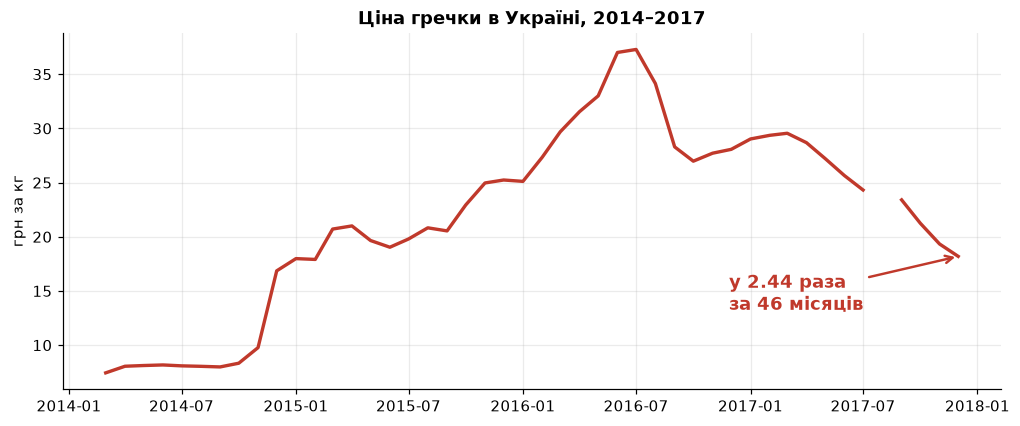

Березень 2014: 7.44 грн   →   Грудень 2017: 18.19 грн


In [5]:
# Національне середнє по країні вже пораховане в даних — ринок 'National Average'
avg = (prices[prices['ринок'] == 'National Average']
         .pivot_table(index='дата', columns='товар', values='ціна'))
# Виставляємо повну місячну сітку: якщо місяця немає в даних, у таблиці з'явиться NaN
avg = avg.reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS'))

buckwheat = avg['Buckwheat grits - Retail']

fig, ax = plt.subplots()
ax.plot(buckwheat.index, buckwheat.values, lw=2.2, color='#C0392B')
ax.set_title('Ціна гречки в Україні, 2014–2017', fontweight='bold')
ax.set_ylabel('грн за кг')
ratio = buckwheat.iloc[-1] / buckwheat.iloc[0]
ax.annotate(f'у {ratio:.2f} раза\nза 46 місяців',
            xy=(buckwheat.index[-1], buckwheat.iloc[-1]), xytext=(-150, -35),
            textcoords='offset points', fontsize=12, fontweight='bold', color='#C0392B',
            arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.6))
plt.show()

print(f'Березень 2014: {buckwheat.iloc[0]:.2f} грн   →   Грудень 2017: {buckwheat.iloc[-1]:.2f} грн')

**Відповідь готова:** гречка подорожчала у 2,4 раза. Питання закрите, можна йти додому.

Ця відповідь **неправильна**. Не тому, що графік намальовано з помилкою — він намальований бездоганно,
і кожне число на ньому справжнє. Він неправильний тому, що відповідає не на те питання, яке ми поставили.

Перш ніж зрозуміти чому, розберімося, **з чого взагалі зроблено графік**.

## 1.1. Загальні етапи аналізу даних

| Етап | Питання етапу | Де ми |
|---|---|---|
| Постановка задачі | На що саме ми відповідаємо? | ← сьогодні почнемо звідси і повернемося наприкінці |
| Збирання даних | Звідки вони й хто їх міряв? | лекція 3 |
| Оцінювання якості | Чи можна їм вірити? | лекція 3 |
| **Розвідувальний аналіз (EDA)** | **Яка в даних структура, залежності, аномалії?** | **сьогодні** |
| Побудова моделі | Що ми можемо передбачити? | лекції 6–9 |
| Перевірка й інтерпретація | Чи працює це поза навчальною вибіркою? | **сьогодні теж** |

**Розвідувальний аналіз** — це етап, на якому ми ще не будуємо модель, а лише дивимось.
Його мета — не підтвердити те, у що ми віримо, а **знайти те, чого не очікували**:
структуру, залежності, аномалії та пропуски.

Головна небезпека EDA: він дуже легко перетворюється на пошук підтверджень.
Перший графік у цьому ноутбуку — саме такий випадок.

### Розвідувальний аналіз: звідки взявся й чим відрізняється від підтверджувального

Поняття **розвідувального аналізу даних** (*exploratory data analysis*, EDA) увів
американський статистик **Джон Тьюкі** в книзі «Exploratory Data Analysis» (1977).
До того статистика розумілася майже виключно як **підтверджувальний аналіз**
(*confirmatory data analysis*, CDA): дослідник формулює гіпотезу, збирає дані, рахує p-значення
і приймає або відхиляє гіпотезу.

Тьюкі звернув увагу на очевидну, але незручну річ: **гіпотезу треба звідкись узяти**.
Якщо її придумано до того, як хто-небудь подивився на дані, вона з великою ймовірністю
не має стосунку до того, що в даних насправді є.

| | Розвідувальний аналіз (EDA) | Підтверджувальний аналіз (CDA) |
|---|---|---|
| Мета | породити гіпотези | перевірити гіпотезу |
| Ставлення до даних | що тут узагалі є? | чи узгоджується це з $H_0$? |
| Основний інструмент | графіки й описові статистики | статистичні критерії, p-значення |
| Результат | список припущень, вартих перевірки | рішення прийняти або відхилити |
| Головна небезпека | побачити те, чого немає | перевірити не те, що варто |

**Чому їх не можна змішувати.** Якщо ви знайшли закономірність під час розвідки, а потім
на **тих самих даних** перевірили її критерієм і отримали $p < 0{,}05$ — це число нічого не варте.
Ви вже підбирали гіпотезу під ці дані, тож фактично провели багато неявних перевірок і взяли
найкращу. Явище відоме як **проблема множинних порівнянь**, а в найгіршому вияві —
як *p-hacking*. Правильний порядок: розвідка на одній частині даних, перевірка на іншій,
яку до того ніхто не бачив.

Саме тому фраза «розвідувальний аналіз» не означає «подивитися на дані перед серйозною роботою».
Це окремий етап зі своєю метою та своїми правилами, і сьогоднішня лекція — про нього.

In [6]:
# ── Що це взагалі за набір ───────────────────────────────────────
print('рядків:', len(prices))
print('товарів:', prices['товар'].nunique())
print('ринків:', prices['ринок'].nunique())
print('місяців із вимірами:', prices['дата'].nunique(), '(у місячній сітці їх 46 — серпня 2017 немає ніде)')
print('одиниці:', list(prices['одиниця'].unique()), '| валюта:', list(prices['валюта'].unique()))
print()
print('25 товарів × 28 ринків × 45 місяців =', 25*28*45, '— якби дані були повні')
print('фактично                             ', len(prices))
print('заповнено                             %.1f%%' % (100*len(prices)/(25*28*45)))
print()
print('Скільки товарів у кожній одиниці вимірювання:')
print(prices.groupby('одиниця')['товар'].nunique().to_string())

рядків: 29091
товарів: 25
ринків: 28
місяців із вимірами: 45 (у місячній сітці їх 46 — серпня 2017 немає ніде)
одиниці: ['KG', 'Loaf', '10 pcs', 'L'] | валюта: ['UAH']

25 товарів × 28 ринків × 45 місяців = 31500 — якби дані були повні
фактично                              29091
заповнено                             92.4%

Скільки товарів у кожній одиниці вимірювання:
одиниця
10 pcs     1
KG        17
L          5
Loaf       2


Дві знахідки з цих п'яти рядків.

**Перша: одиниці вимірювання різні.** Сімнадцять товарів міряють у кілограмах, п'ять — у літрах,
хліб — у буханцях, яйця — десятками. Це означає, що **ціни різних товарів безпосередньо незіставні**:
речення «молоко дорожче за яйця» не має сенсу, поки ми не домовимось, скільки яєць беремо.
Порівнювати можна лише **відносні зміни** — і саме тому далі скрізь, де ми порівнюємо товари між собою,
ми ділимо ряд на його власне перше значення.

**Друга: заповнено 92,4%.** Бракує близько двох з половиною тисяч вимірів, і ми поки не знаємо,
яких саме. Повернемося до цього на кроці 2 — там з'ясується, що розташовані вони геть не випадково.

## 1.2. Тип шкали диктує тип графіка

З третьої лекції ми пам'ятаємо, що кожен стовпець належить до певної шкали вимірювання,
і ця шкала визначає, які дії з ним дозволені. Виявляється, вона так само визначає, **яким графіком його можна малювати**.

### Шкали вимірювання: коротке повторення

Класифікацію запропонував психолог **Стенлі Стівенс** (1946). Ідея: тип шкали визначається тим,
**які перетворення значень зберігають зміст вимірювання**. Наслідок — для кожної шкали дозволений
свій набір операцій, і все, що за його межами, є безглуздим, навіть якщо формально обчислюється.

| Шкала | Що осмислено | Допустимі перетворення | Приклад |
|---|---|---|---|
| Номінальна | лише рівність $=$, $\neq$ | будь-яка взаємно однозначна заміна назв | область, товар |
| Порядкова | ще й порядок $<$, $>$ | будь-яка зростаюча функція | оцінка «добре/задовільно» |
| Інтервальна | ще й різниця $y_2-y_1$ | $y \mapsto ay + b$, $a>0$ | температура в °C, календарна дата |
| Відношень | ще й відношення $y_2/y_1$ | $y \mapsto ay$, $a>0$ | ціна, маса, довжина |
| Абсолютна | саме значення | жодних | кількість, частка |

**Практичний наслідок для сьогоднішньої лекції.** Ціна належить до шкали відношень — у неї є
справжній нуль («нічого не коштує»), тому твердження «подорожчало у 2,4 раза» має сенс.
Якби ми міряли температуру, таке твердження було б безглуздим: «сьогодні удвічі тепліше, ніж учора»
змінює істинність при переході з Цельсія на Фаренгейт, а отже, нічого не описує.

**Циклічна шкала** у класифікацію Стівенса не входить, але на практиці трапляється постійно:
місяць року, день тижня, година доби, напрямок вітру. Її особливість у тому, що найбільше
й найменше значення є **сусідами**. Звичайна вісь X це руйнує, і ми побачимо наслідки на кроці 3.

In [7]:
scales = pd.DataFrame([
 ['ринок',   'номінальна',  'немає порядку, лише назви',            'колір, фасети, стовпчики'],
 ['товар',   'номінальна',  'немає порядку, лише назви',            'фасети, стовпчики, ранговий графік'],
 ['одиниця', 'номінальна',  '4 рівні: кг, л, буханець, десяток',    'групування; ціни між групами незіставні'],
 ['рік',     'інтервальна', 'різниця має сенс, відношення — ні',    'вісь X'],
 ['місяць',  'циклічна',    'після 12 знову настає 1',              'вісь X, полярні координати, теплова карта'],
 ['дата',    'інтервальна', 'впорядкована, з рівним кроком',        'вісь X лінійного графіка'],
 ['ціна',    'відношень',   'є справжній нуль, відношення мають сенс', 'вісь Y, гістограма, boxplot'],
], columns=['стовпець', 'шкала', 'що це означає', 'придатні засоби візуалізації'])
scales

,стовпець,шкала,що це означає,придатні засоби візуалізації
0,ринок,номінальна,"немає порядку, лише назви","колір, фасети, стовпчики"
1,товар,номінальна,"немає порядку, лише назви","фасети, стовпчики, ранговий графік"
2,одиниця,номінальна,"4 рівні: кг, л, буханець, десяток",групування; ціни між групами незіставні
3,рік,інтервальна,"різниця має сенс, відношення — ні",вісь X
4,місяць,циклічна,після 12 знову настає 1,"вісь X, полярні координати, теплова карта"
5,дата,інтервальна,"впорядкована, з рівним кроком",вісь X лінійного графіка
6,ціна,відношень,"є справжній нуль, відношення мають сенс","вісь Y, гістограма, boxplot"


Зверніть увагу на **`місяць`**. Це не просто ціле число від 1 до 12: після грудня знову настає січень,
тобто грудень і січень — сусіди, хоч за числами вони на максимальній відстані.
Це **циклічна шкала**, і звичайна вісь X її спотворює. Ми побачимо це на теплових картах на кроці 3.

І зверніть увагу на **`ціна`**: єдина зі шкали відношень, тобто єдина, для якої твердження
«подорожчало у 2,4 раза» взагалі має сенс. Для інтервальної шкали таке твердження було б беззмістовним.

### Теорія: чому одні графіки читаються краще за інші

Питання «який графік кращий» не є справою смаку. На нього є експериментальна відповідь.

У 1984 році **Вільям Клівленд і Роберт Мак-Ґілл** опублікували роботу, у якій вимірювали,
наскільки точно люди зчитують кількісну інформацію, закодовану різними **візуальними каналами**.
Учасникам показували графіки й просили оцінити відношення величин; дослідники міряли помилку.
Результат — впорядкування каналів за точністю:

| Місце | Канал кодування | Точність |
|---|---|---|
| 1 | положення на спільній шкалі | найвища |
| 2 | положення на різних шкалах із однаковим кроком | |
| 3 | довжина | |
| 4 | кут, нахил | |
| 5 | площа | |
| 6 | об'єм, кривина | |
| 7 | насиченість кольору, відтінок | найнижча |

Звідси випливають майже всі практичні правила візуалізації:

* **Лінійний і точковий графіки** кодують величину **положенням** — каналом першого рангу.
  Тому вони й виявляються найточнішими.
* **Кругова діаграма** кодує **кутом і площею** — канали четвертого й п'ятого рангів.
  Саме тому люди погано порівнюють сектори, і саме тому будь-яку кругову діаграму
  можна замінити стовпчиковою з виграшем у точності.
* **Колір** — найгірший канал для кількості, зате прийнятний для категорій, де точність
  не потрібна взагалі, потрібна лише розрізнюваність.

**Друге правило — відповідність геометрії природі величини.** Кожна геометрія неявно
щось стверджує про дані, і якщо твердження хибне, графік уводить в оману незалежно
від точності каналу. Перевірте себе на наступному графіку, перш ніж читати відповідь.

## ❓ Питання 1

Нижче той самий ряд — ціна гречки — намальований **шістьма різними способами**.
Дані ідентичні. Відрізняється лише геометрія.

**Який із шести графіків правильний, а які — ні? І чому?**

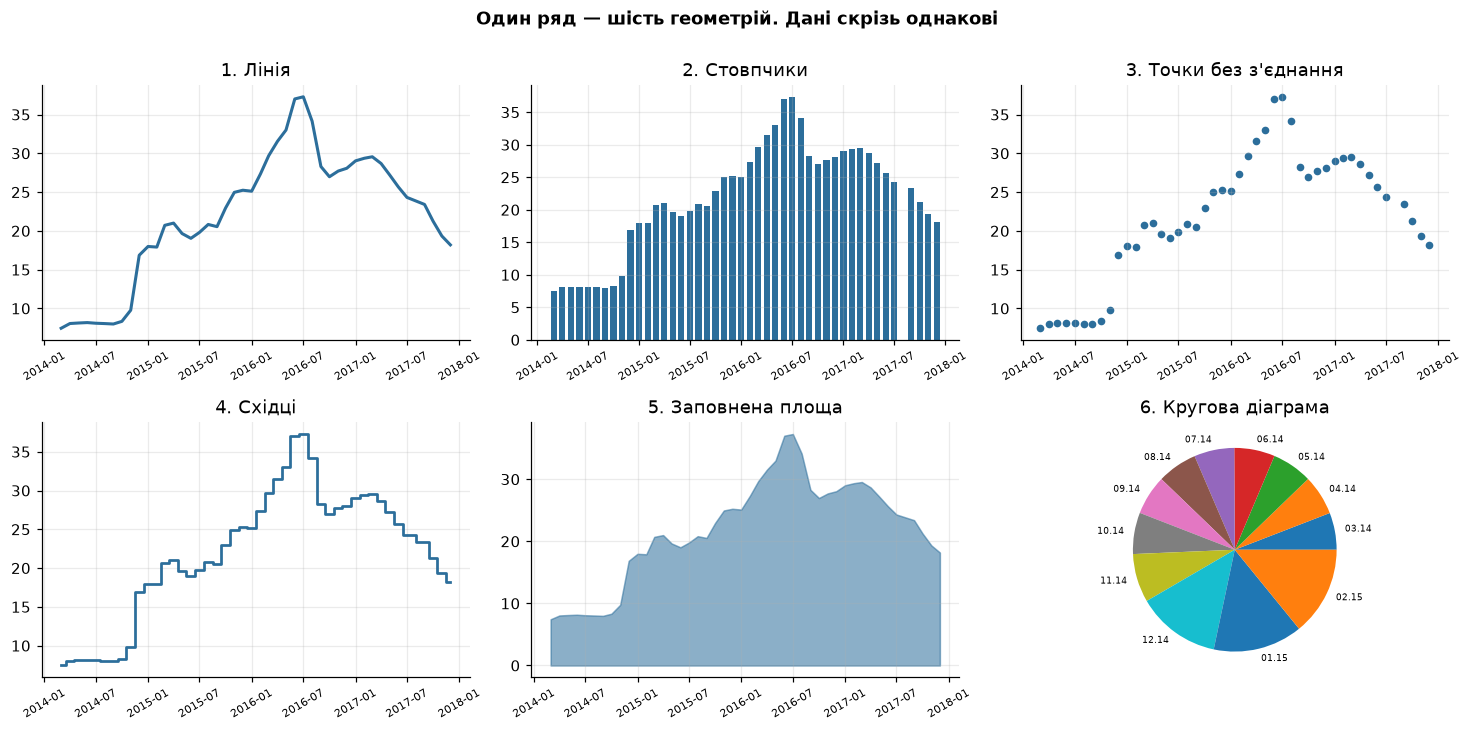

In [8]:
x = buckwheat.dropna()
fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.6))
fig.suptitle('Один ряд — шість геометрій. Дані скрізь однакові', fontweight='bold', y=1.0)

axes[0,0].plot(x.index, x.values, lw=2, color='#2C6E9B')
axes[0,0].set_title('1. Лінія')

axes[0,1].bar(x.index, x.values, width=22, color='#2C6E9B')
axes[0,1].set_title('2. Стовпчики')

axes[0,2].scatter(x.index, x.values, s=16, color='#2C6E9B')
axes[0,2].set_title('3. Точки без з\'єднання')

axes[1,0].step(x.index, x.values, where='mid', lw=1.8, color='#2C6E9B')
axes[1,0].set_title('4. Східці')

axes[1,1].fill_between(x.index, 0, x.values, alpha=.55, color='#2C6E9B')
axes[1,1].set_title('5. Заповнена площа')

# Кругова діаграма: частки перших 12 місяців
first12 = x.iloc[:12]
axes[1,2].pie(first12.values, labels=[d.strftime('%m.%y') for d in first12.index],
              textprops=dict(fontsize=6))
axes[1,2].set_title('6. Кругова діаграма')
axes[1,2].grid(False)

for ax in axes.flat[:5]:
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout()
plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

**Правильні: 1 (лінія) і 4 (східці).** Обидві геометрії роблять видимою головну властивість даних —
**впорядкованість у часі**. Лінія доречна, коли ми вважаємо, що між вимірами величина змінювалась плавно;
східці — коли значення тримається сталим до наступного виміру. Для місячної ціни підходять обидві,
східці навіть чесніші: ми ж не міряли ціну 14 числа.

**3 (точки)** — не помилка, але втрата. Око саме добудовує послідовність, проте слабше, ніж підказала б лінія.
Точки доречні, коли спостереження **не пов'язані** між собою, а тут вони пов'язані.

**2 (стовпчики)** — типова помилка. Стовпчик тягне око до нуля й натякає, що ми порівнюємо **обсяги**,
а не стежимо за **рівнем**. Ціна не накопичується: 26 гривень у березні плюс 26 у квітні не дорівнює 52.
Стовпчики доречні для лічильних величин (скільки продано, скільки пацієнтів), а не для рівнів.

**5 (площа)** — ще гірше. Заповнена площа означає «це кількість, і вона накопичується».
До того ж площа приковує погляд до відстані від нуля й приховує зміни нагорі, де все найцікавіше.

**6 (кругова)** — безглуздя. Кругова діаграма показує **частки цілого**, а сума цін за 12 місяців нічого не означає:
це не ціле, яке можна ділити. Плюс до того людське око погано порівнює кути, а тут ще й **втрачено порядок часу**.

> **Правило:** геометрія — це твердження про дані. Обираючи стовпчики, ви стверджуєте «це кількість від нуля».
> Обираючи круг — «це частки цілого». Якщо твердження неправдиве, графік бреше ще до того, як ви подивились на числа.

</details>

### Теорія: звідки взялася граматика графіки

Ідею запропонував **Ліланд Вілкінсон** у книзі «The Grammar of Graphics» (1999).
До того візуалізацію викладали як **каталог типів**: ось стовпчикова діаграма, ось кругова,
ось гістограма — вивчіть, коли яку брати. Вілкінсон показав, що каталог зайвий:
усі ці типи є комбінаціями кількох незалежних складових, як речення є комбінацією
слів за правилами граматики.

Практичним утіленням стала бібліотека **ggplot2** для R (Гедлі Вікгем, 2005), а згодом
`plotnine` для Python і граматика Vega-Lite. Але цінність ідеї не в бібліотеці:
вона дає **спосіб думати** про графік, який працює в будь-якому інструменті, зокрема й у matplotlib.

**Практичний наслідок.** Замість питання «який тип графіка тут узяти?» ставлять п'ять окремих питань:

1. **Дані** — яку саме таблицю я малюю? Чи це вихідні значення, чи агрегат, чи перетворення?
2. **Геометрія** — якою фігурою? (що я цим стверджую про природу величини?)
3. **Естетика** — яка змінна яким каналом кодується? (положення, колір, розмір, форма, прозорість)
4. **Шкали** — як число перетворюється на піксель? (лінійна чи логарифмічна вісь, яка палітра, які межі)
5. **Фасети** — чи розбивати на кілька полів і за якою змінною?

Кожне питання має відповідь незалежно від інших, і саме тому з невеликого набору складових
виходить необмежене розмаїття графіків.

## 1.3. Граматика графіки: п'ять шарів

Будь-який статистичний графік розкладається на п'ять незалежних шарів. Змінюючи їх по одному,
ми отримуємо все розмаїття візуалізації з дуже небагатьох понять.

| Шар | Що задає | Приклад |
|---|---|---|
| **Дані** | що саме малюємо | таблиця «дата × товар → ціна» |
| **Геометрія** | якою фігурою | лінія, точка, стовпчик, прямокутник |
| **Естетика** | яка змінна чим кодується | X = дата, Y = ціна, колір = товар, товщина = обсяг |
| **Шкали** | як число перетворюється на píксель | лінійна чи логарифмічна вісь, палітра кольорів |
| **Фасети** | на скільки окремих полів розбито | 27 полів — по одному на область |

Далі — той самий набір, до якого шари додаються по одному.

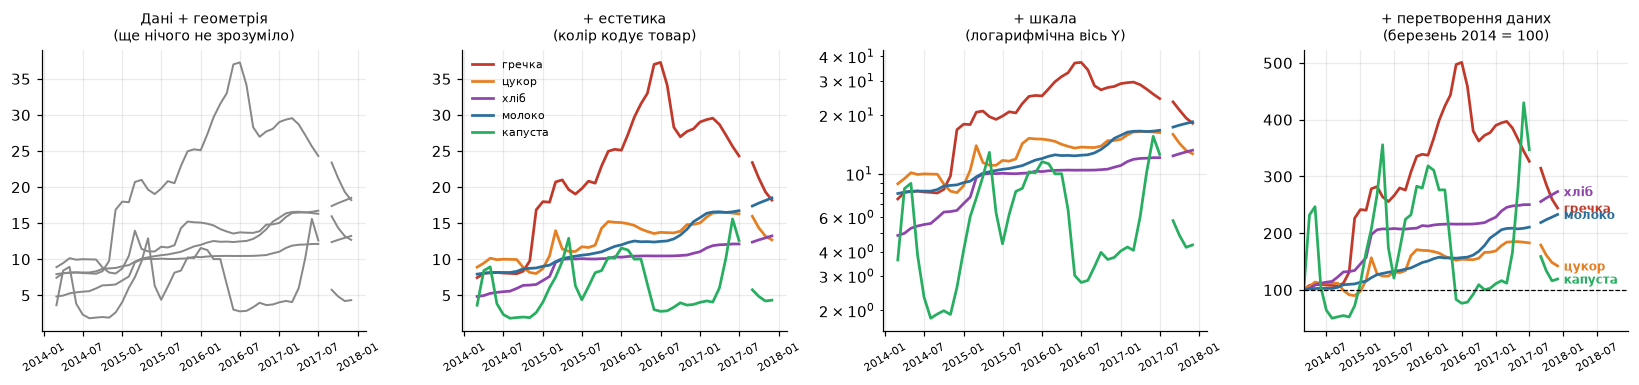

In [9]:
goods5 = ['Buckwheat grits - Retail', 'Sugar - Retail', 'Bread (wheat) - Retail',
           'Milk - Retail', 'Cabbage - Retail']
UA = {'Buckwheat grits - Retail':'гречка', 'Sugar - Retail':'цукор',
       'Bread (wheat) - Retail':'хліб', 'Milk - Retail':'молоко', 'Cabbage - Retail':'капуста',
       'Butter - Retail':'масло', 'Eggs - Retail':'яйця', 'Carrots - Retail':'морква',
       'Potatoes - Retail':'картопля', 'Meat (beef) - Retail':'яловичина',
       'Meat (pork) - Retail':'свинина', 'Fuel (petrol-gasoline) - Retail':'бензин',
       'Rice - Retail':'рис', 'Onions - Retail':'цибуля', 'Beetroots - Retail':'буряк',
       'Sour cream - Retail':'сметана', 'Curd - Retail':'сир кисломолочний',
       'Oil (sunflower) - Retail':'олія', 'Fat (salo) - Retail':'сало',
       'Bread (rye) - Retail':'хліб житній', 'Pasta - Retail':'макарони',
       'Meat (chicken, whole) - Retail':'курятина', 'Meat (mixed, sausage) - Retail':'ковбаса',
       'Wheat flour (first grade) - Retail':'борошно', 'Fuel (diesel) - Retail':'дизель'}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))

# Шар 1+2: дані + геометрія. Все однаковим кольором — жодної естетики
for g in goods5:
    axes[0].plot(avg.index, avg[g], color='#888', lw=1.3)
axes[0].set_title('Дані + геометрія\n(ще нічого не зрозуміло)', fontsize=9)

# Шар 3: естетика — колір кодує товар
color_of = dict(zip(goods5, ['#C0392B', '#E67E22', '#8E44AD', '#2C6E9B', '#27AE60']))
for g in goods5:
    axes[1].plot(avg.index, avg[g], color=color_of[g], lw=1.8, label=UA[g])
axes[1].legend(fontsize=7, frameon=False)
axes[1].set_title('+ естетика\n(колір кодує товар)', fontsize=9)

# Шар 4: шкала — логарифмічна вісь Y вирівнює товари різної вартості
for g in goods5:
    axes[2].plot(avg.index, avg[g], color=color_of[g], lw=1.8)
axes[2].set_yscale('log')
axes[2].set_title('+ шкала\n(логарифмічна вісь Y)', fontsize=9)

# Шар 5: нормування до березня 2014 — тепер порівнюємо темп, а не рівень
for g in goods5:
    s = avg[g] / avg[g].iloc[0] * 100

    axes[3].plot(s.index, s.values, color=color_of[g], lw=1.8)
    axes[3].annotate(UA[g], xy=(s.index[-1], s.iloc[-1]), xytext=(4, -3),
                     textcoords='offset points', fontsize=8, color=color_of[g], fontweight='bold')
axes[3].axhline(100, color='k', lw=.8, ls='--')
axes[3].set_xlim(avg.index[0], avg.index[-1] + pd.Timedelta(days=380))
axes[3].set_title('+ перетворення даних\n(березень 2014 = 100)', fontsize=9)

for ax in axes:
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

Зверніть увагу на четверте поле. Ми не змінили ані геометрії, ані кольорів — лише **перетворили дані**,
поділивши кожен ряд на його власне перше значення. І графік почав відповідати на зовсім інше питання:
не «скільки коштує», а «наскільки подорожчало». Та сама п'ятірка товарів, той самий тип графіка, інше питання.

Зверніть увагу й на дрібницю в останньому полі: **підписи стоять просто біля ліній**, а легенди немає.
Коли рядів більше чотирьох, легенда змушує око бігати туди-сюди й запам'ятовувати колір.
Підпис на місці вбиває цю роботу повністю.

## 1.4. Фасети: 27 маленьких графіків замість одного великого

Фасетування (англ. *small multiples*) — п'ятий шар граматики. Замість того щоб втиснути 27 областей
в одне поле, де вони перетворяться на кольорову локшину, ми малюємо 27 однакових маленьких полів
**зі спільними шкалами**. Око порівнює форму, а не колір.

### Теорія: чому фасети працюють

Прийом називають **small multiples** — термін увів **Едвард Тафті** («The Visual Display of
Quantitative Information», 1983). Суть у тому, що кілька невеликих графіків **з однаковою
структурою та спільними шкалами** читаються швидше й точніше, ніж один складний графік
із багатьма накладеними рядами.

Причина — у тому самому впорядкуванні каналів Клівленда й Мак-Ґілла. Коли 27 областей
намальовано в одному полі різними кольорами, читач змушений кодувати належність **кольором**
(канал сьомого рангу) і щоразу звірятися з легендою. Коли ті самі 27 областей розкладено
на 27 полів, належність кодується **положенням поля** — і не коштує читачеві нічого.

**Три умови, за яких фасети працюють:**

1. **Спільні шкали.** Якщо в кожного поля свої межі осей, форми стають незіставними,
   і весь сенс прийому зникає. У `matplotlib` за це відповідають `sharex=True, sharey=True`.
2. **Однакова структура.** Усі поля мають бути побудовані однаково, щоб око вчилося читати
   їх один раз.
3. **Спільне тло.** Дуже дешевий і дуже ефективний прийом: повторити на кожному полі
   ту саму опорну криву (тут — національне середнє) світлим кольором. Тоді відхилення
   видно без жодних обчислень у голові.

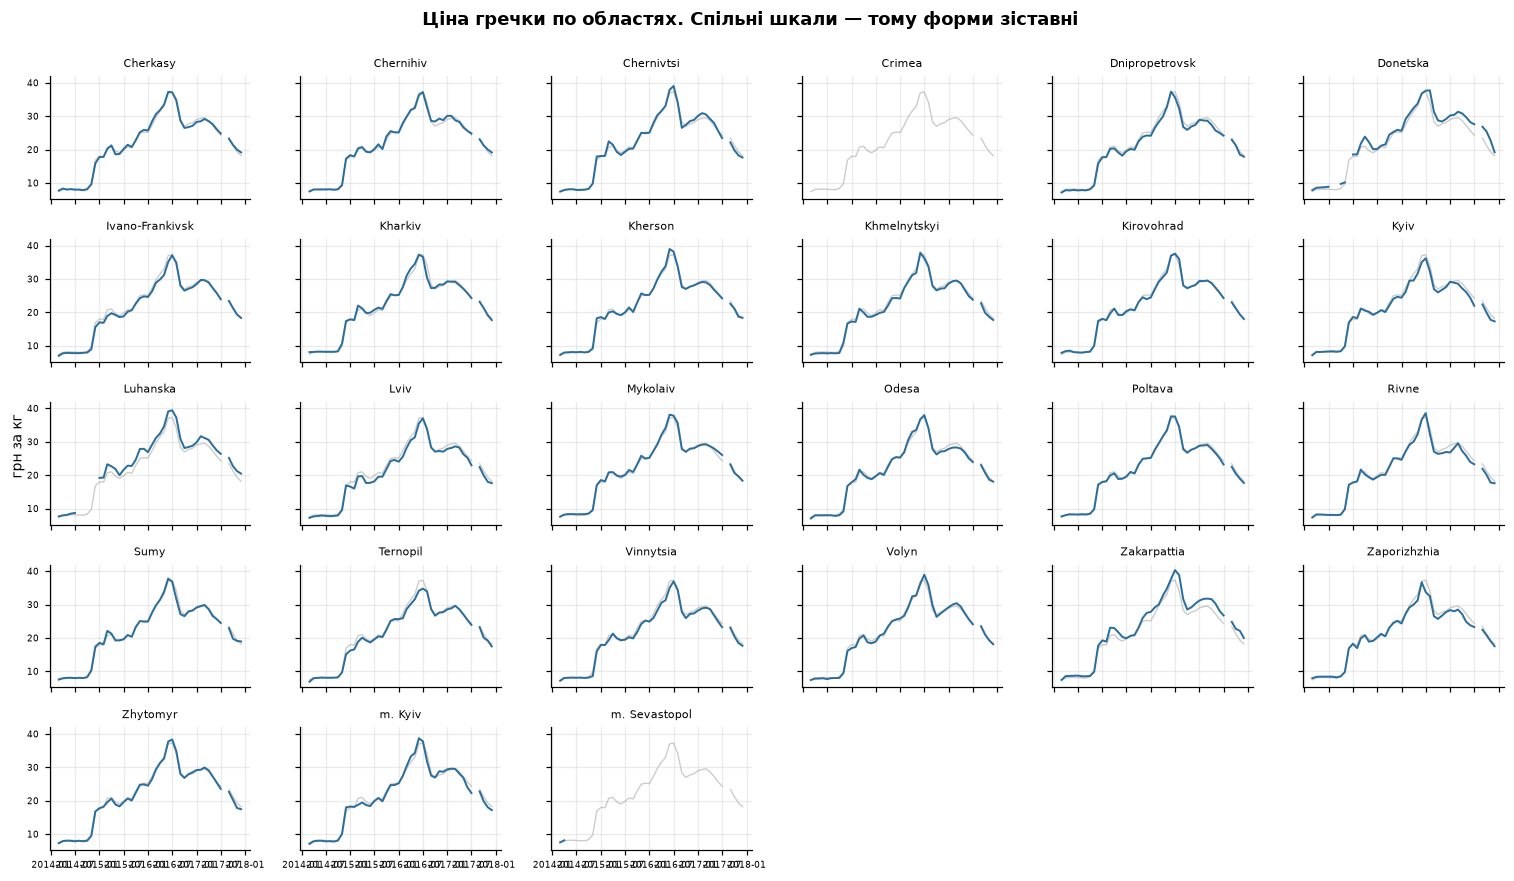

In [10]:
by_region = (prices[(prices['товар'] == 'Buckwheat grits - Retail') & (prices['ринок'] != 'National Average')]
          .pivot_table(index='дата', columns='ринок', values='ціна')
          .reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS')))

regions = by_region.columns.tolist()
fig, axes = plt.subplots(5, 6, figsize=(14, 8), sharex=True, sharey=True)
fig.suptitle('Ціна гречки по областях. Спільні шкали — тому форми зіставні',
             fontweight='bold', y=.995)
for ax, o in zip(axes.flat, regions):
    ax.plot(by_region.index, by_region[o], lw=1.3, color='#2C6E9B')
    ax.plot(avg.index, avg['Buckwheat grits - Retail'], lw=.9, color='#ccc', zorder=0)
    ax.set_title(o, fontsize=7.5)
    ax.tick_params(labelsize=6)
for ax in axes.flat[len(regions):]:
    ax.axis('off')
fig.supylabel('грн за кг', fontsize=9)
plt.tight_layout(); plt.show()

Сіра лінія на кожному полі — те саме національне середнє, повторене 27 разів як опорна величина.
Це дешевий і дуже ефективний прийом: око бачить відхилення від спільного тла, не рахуючи нічого в голові.

А тепер подивіться на поля **Crimea** і **m. Sevastopol**. Ми повернемося до них на кроці 3.

---
### Проміжна відповідь 1

**«Їжа подорожчала у 2,4 раза».** Обчислення правильне, дані справжні, графік побудовано без помилок.

Ми також з'ясували, що графік — не ілюстрація, а конструкція з п'яти незалежних шарів,
і що кожен із них можна обрати по-різному. Саме цим ми й скористаємося на наступному кроці,
щоб перевірити цю відповідь на міцність.

---
# Крок 2. Перевірка відповіді на міцність

> **Підзадача кроку.** Взяти ті самі дані й побудувати з них **сім різних графіків**,
> кожен із яких правдивий і кожен із яких веде до іншого висновку.
> Мета — з'ясувати, чи витримує перевірку відповідь, отримана на кроці 1.

Тепер найважливіша частина лекції. Усі графіки нижче побудовано **з одних і тих самих правдивих даних**.
Жодної підробки, жодного вигаданого числа. І попри це кожен наступний пункт — спосіб
сказати неправду, не збрехавши.

Це не теоретична небезпека. Саме так виглядає більшість графіків у новинах, презентаціях і звітах.

### Теорія: коефіцієнт брехні та принцип пропорційного чорнила

**Едвард Тафті** запропонував кількісну міру спотворення — **коефіцієнт брехні** (*lie factor*):

$$\text{Lie Factor} = \frac{\text{розмір ефекту на графіку}}{\text{розмір ефекту в даних}}$$

Для чесного графіка коефіцієнт дорівнює одиниці. Тафті вважав прийнятним діапазон
приблизно від 0,95 до 1,05. Зрізана вісь легко дає значення в десятки: зростання ціни
на 5 відсотків займає всю висоту поля, тобто виглядає як зростання на 100 відсотків,
і коефіцієнт брехні дорівнює 20.

Сучасніше формулювання того самого принципу належить **Бернісу Роугду** — **принцип
пропорційного чорнила** (*principle of proportional ink*):

> Площа заповненої області на графіку має бути пропорційна величині, яку вона зображує.

Саме з цього принципу випливає правило про нуль, і саме він пояснює, **чому для стовпчиків
зріз заборонений, а для ліній — ні**:

* Стовпчик — це **заповнена площа**, що починається від осі. Його площа кодує величину.
  Зрізавши вісь, ви розриваєте пропорційність, і принцип порушено.
* Лінія **нічого не заповнює**. Величина кодується положенням точки, а не площею під нею.
  Пропорційність не порушується, тому зріз допустимий.

**Наслідок, який часто пропускають:** графік із заповненою областю (`fill_between`,
area chart) підпорядковується правилу стовпчиків, а не ліній. Якщо ви заштрихували
простір під лінією, вісь зобов'язана починатися з нуля.

**Коли зріз не лише дозволений, а обов'язковий.** Якщо величина має великий сталий
зсув і малі змістовні коливання — температура тіла, курс валюти, атмосферний тиск,
IQ, — малювання від нуля знищує всю інформацію. Ніхто не малює температуру повітря
від абсолютного нуля. Правило тут одне: **зріз має бути очевидним для читача** —
явні підписи осі, а за потреби — символ розриву осі.

## 2.1. Зрізана вісь

## ❓ Питання 2

Обидва поля показують ціну на хліб за один і той самий період. **Чим вони відрізняються і яке з них чесне?**

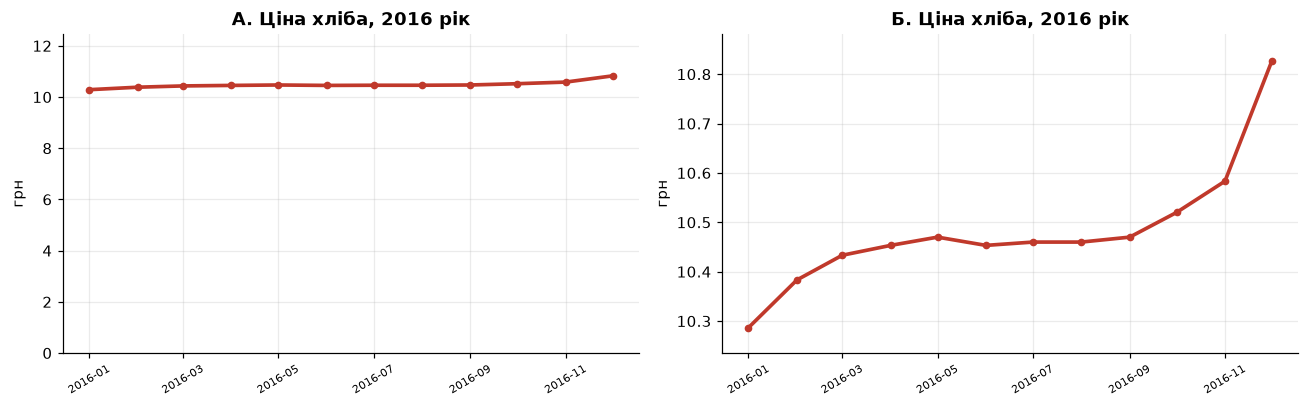

Насправді за 2016 рік: 10.29 → 10.83 грн, тобто +5.2%
Розмах коливань за рік: 0.54 грн


In [11]:
bread = avg['Bread (wheat) - Retail']
window = bread['2016-01':'2016-12']

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (from_zero, title) in zip(axes, [(True, 'A'), (False, 'Б')]):
    ax.plot(window.index, window.values, lw=2.4, marker='o', ms=4, color='#C0392B')
    if from_zero:
        ax.set_ylim(0, window.max()*1.15)
    else:
        ax.set_ylim(window.min()*0.995, window.max()*1.005)
    ax.set_title(f'{title}. Ціна хліба, 2016 рік', fontweight='bold')
    ax.set_ylabel('грн')
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print(f'Насправді за 2016 рік: {window.iloc[0]:.2f} → {window.iloc[-1]:.2f} грн, '
      f'тобто {100*(window.iloc[-1]/window.iloc[0]-1):+.1f}%')
print(f'Розмах коливань за рік: {window.max()-window.min():.2f} грн')

<details>
<summary><b>💡 Відповідь</b></summary>

Поле **Б** має **зрізану вісь Y**: вона починається не з нуля, а трохи нижче за мінімум ряду.
Через це коливання в кілька копійок займає всю висоту поля й виглядає як драматичне зростання.

Що важливо зрозуміти: **зрізана вісь не завжди обман**. Вона обов'язкова, коли значення великі,
а зміни малі — наприклад, температура тіла чи курс валюти. Малювати температуру від 0 °C безглуздо.

Правило таке: **вісь має починатися з нуля тоді, коли геометрія посилається на нуль**.
Стовпчик кодує величину своєю довжиною — отже, стовпчики **завжди** від нуля, інакше довжина бреше.
Лінія кодує рівень своїм положенням, а не довжиною, — отже, лінії зріз дозволений,
**якщо зріз явно позначений і читач це бачить**.

Обман у полі Б не в тому, що вісь зрізана, а в тому, що **зріз не оголошений**: підписи на осі
дрібні, нуля немає, а заголовок обіцяє «ціну», не попереджаючи про масштаб.

</details>

### А ось той самий прийом на стовпчиках — де він уже не має виправдань

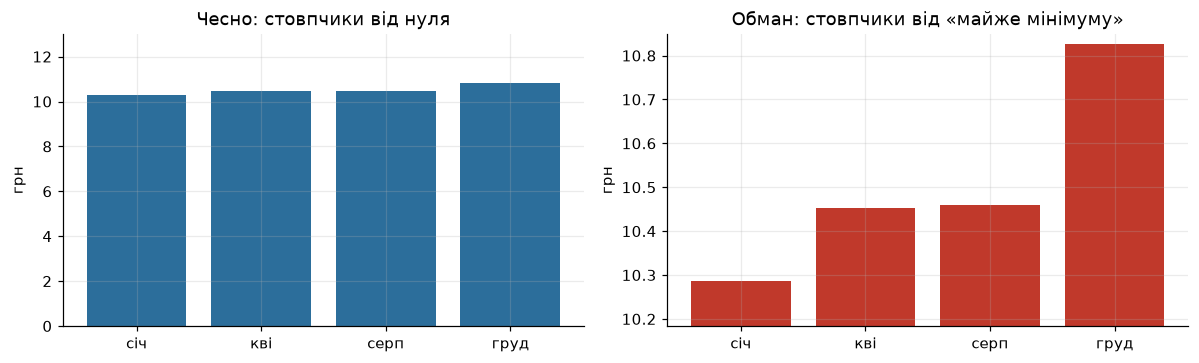

Різниця між першим і останнім стовпчиком: 0.54 грн (5.2%)
На правому полі візуально вона виглядає як різниця в кілька разів.


In [12]:
months = ['січ', 'кві', 'серп', 'груд']
bar_vals = bread[[pd.Timestamp(d) for d in ['2016-01-01', '2016-04-01', '2016-08-01', '2016-12-01']]]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(months, bar_vals.values, color='#2C6E9B'); axes[0].set_ylim(0, bar_vals.max()*1.2)
axes[0].set_title('Чесно: стовпчики від нуля')
axes[1].bar(months, bar_vals.values, color='#C0392B'); axes[1].set_ylim(bar_vals.min()*0.99, bar_vals.max()*1.002)
axes[1].set_title('Обман: стовпчики від «майже мінімуму»')
for ax in axes: ax.set_ylabel('грн')
plt.tight_layout(); plt.show()

print('Різниця між першим і останнім стовпчиком: %.2f грн (%.1f%%)'
      % (bar_vals.iloc[-1]-bar_vals.iloc[0], 100*(bar_vals.iloc[-1]/bar_vals.iloc[0]-1)))
print('На правому полі візуально вона виглядає як різниця в кілька разів.')

### Теорія: підбір проміжку й базового рівня

Прийом має англійську назву **cherry-picking** і є окремим випадком ширшої проблеми —
**вибору бази порівняння**. Будь-яке твердження про зміну має вигляд «від $A$ до $B$»,
і той, хто обирає $A$, керує висновком.

**Три різновиди, які варто вміти впізнавати:**

1. **Підбір кінців проміжку.** Початок ставлять у локальний мінімум, кінець — у локальний
   максимум (або навпаки). Формально нічого не збрехано.
2. **Підбір довжини проміжку.** Для величини з періодом $m$ будь-яке вікно завдовжки
   приблизно $m/2$ гарантовано потрапляє або на висхідну, або на низхідну частину циклу.
3. **Підбір моменту зрізу.** «За останні три місяці» — коли за рік картина протилежна.

**Захист від першого й другого — порівняння рік до року.** Замість $y_t / y_{t-1}$
беруть $y_t / y_{t-m}$, тобто порівнюють з тим самим місяцем попереднього року.
Сезонна складова при цьому скорочується, бо в обох точках вона однакова.
Саме так публікують інфляцію: «у відсотках до відповідного місяця попереднього року».

$$\text{зміна рік до року} = \frac{y_t - y_{t-12}}{y_{t-12}} \cdot 100\%$$

**Захист від третього — показувати весь ряд.** Якщо автор графіка обрізав ряд і не
пояснив чому, це саме по собі є інформацією про автора.

**Контрольне питання, яке варто ставити завжди:** чи мають початок і кінець проміжку
**змістовне обґрунтування** — початок спостережень, зміна закону, початок кризи?
Якщо єдине обґрунтування — «так вийшло гарніше», відсоток нічого не вартий.

## 2.2. Підбір вікна

## ❓ Питання 3

Три поля — той самий ряд цін на капусту. Змінюється лише **проміжок часу**, який ми показали.
**Скільки різних заголовків можна поставити над цими полями, не збрехавши жодним числом?**

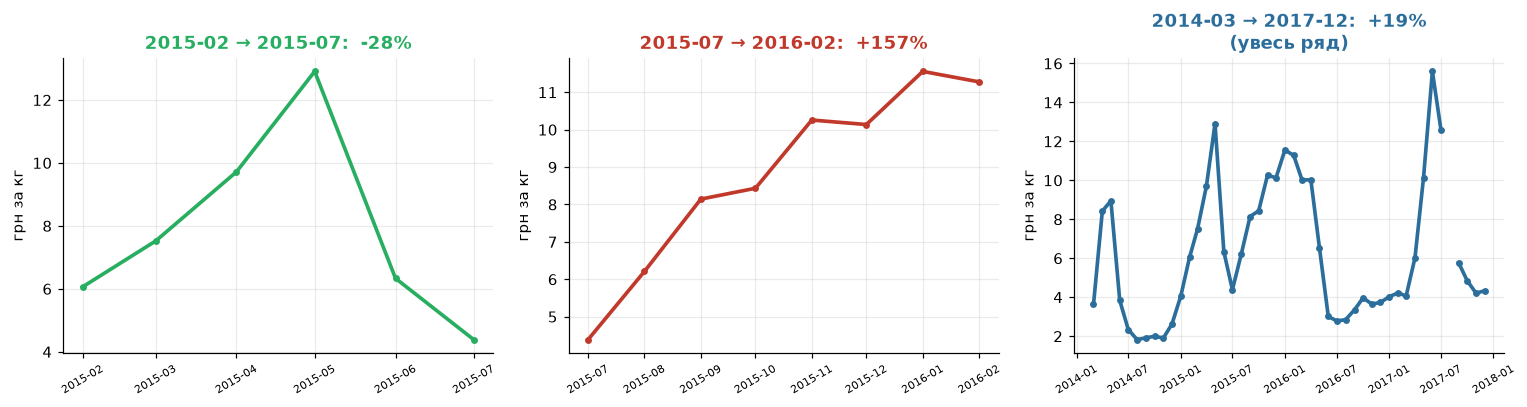

In [13]:
cabbage = avg['Cabbage - Retail']
windows = [('2015-02', '2015-07', '#27AE60'),
         ('2015-07', '2016-02', '#C0392B'),
         ('2014-03', '2017-12', '#2C6E9B')]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (a, b, c) in zip(axes, windows):
    w = cabbage[a:b]
    ax.plot(w.index, w.values, lw=2.4, color=c, marker='o', ms=3.5)
    change = 100*(w.iloc[-1]/w.iloc[0] - 1)
    ax.set_title(f'{a} → {b}:  {change:+.0f}%', fontweight='bold', color=c)
    ax.set_ylabel('грн за кг')
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)
axes[2].set_title(axes[2].get_title() + '\n(увесь ряд)', fontweight='bold', color=windows[2][2])
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

Щонайменше три, і всі формально правдиві:

* «Капуста подешевшала на чверть» — лютий→липень 2015;
* «Капуста подорожчала у два з половиною рази» — липень 2015→лютий 2016;
* «Капуста подорожчала лише на 19 відсотків» — увесь ряд.

Жодного неправдивого числа. Усі три речення описують ті самі дані.

Причина в тому, що ціна капусти має **річну регулярність**: вона падає до осені, коли збирають урожай,
і зростає до весни, поки склад порожніє. Будь-яке вікно завдовжки пів року неминуче потрапляє
або на спуск, або на підйом — і показує рух усередині року, видаючи його за тенденцію.

(На кроці 3 ми побачимо цікавий поворот: розмах цих коливань у капусти сталий, а от **момент
їх настання плаває на пів року** — саме тому формальна міра сезонності для неї виявиться низькою.)

> **Правило:** перш ніж повірити у відсоток зміни, спитайте, **чому обрано саме цей проміжок**.
> Якщо початок і кінець вікна не мають змістовного обґрунтування (початок спостережень, зміна закону,
> початок кризи), — відсоток нічого не вартий. Для сезонних величин порівнюють **рік до року**,
> а не місяць до місяця.

</details>

### Теорія: чому подвійна вісь не може довести зв'язок

Формально проблема виглядає так. Малюючи два ряди $x_t$ і $y_t$ на спільному полі
з різними осями, ми фактично зображуємо перетворені ряди

$$\tilde x_t = a_1 x_t + b_1, \qquad \tilde y_t = a_2 y_t + b_2,$$

де $a_1, b_1, a_2, b_2$ обирає автор графіка, задаючи межі осей.
Це **чотири вільні параметри**, і їх достатньо, щоб сумістити будь-які два монотонні ряди
або, навпаки, розвести їх якнайдалі. Візуальна близькість кривих не несе інформації про дані —
вона несе інформацію про вибір автора.

**Що з цим робити.**

*Спосіб перший — спільна база.* Нормуємо обидва ряди на їхнє перше значення:

$$x^{(100)}_t = 100 \cdot \frac{x_t}{x_{t_0}}, \qquad y^{(100)}_t = 100 \cdot \frac{y_t}{y_{t_0}}$$

Тепер обидва ряди безрозмірні, малюються на одній осі, і вертикальна відстань між ними
означає різницю в **темпах зміни**. Вибір бази $t_0$ лишається за автором, але він
принаймні видимий і його можна оскаржити.

*Спосіб другий — діаграма розсіювання та коефіцієнт кореляції Пірсона:*

$$r = \frac{\sum_{t}(x_t - \bar x)(y_t - \bar y)}{\sqrt{\sum_t (x_t - \bar x)^2}\sqrt{\sum_t (y_t - \bar y)^2}}$$

Головна властивість: $r$ **не змінюється** при будь-якому лінійному перетворенні
$x \mapsto a x + b$. Саме тому його не можна підігнати вибором меж осей.

### Але й кореляція не доводить зв'язку

Важлива пересторога, до якої ми повернемось на кроці 5. Для **нестаціонарних** рядів
(а два зростаючі ряди майже напевно нестаціонарні) коефіцієнт кореляції систематично
показує високі значення навіть тоді, коли ряди породжені **незалежними** процесами.
Явище відоме як **удавана регресія** (*spurious regression*); його описали
Грейнджер і Ньюболд у 1974 році.

Причина проста: якщо обидва ряди зростають, вони зростають «разом» за побудовою.
Кореляція виміряла наявність тренду в обох, а не зв'язок між ними.

**Правильний спосіб** — рахувати кореляцію не рівнів, а **приростів**:
$\Delta x_t = x_t - x_{t-1}$ і $\Delta y_t = y_t - y_{t-1}$. Якщо зв'язок залишився
на приростах — він, імовірно, справжній.

## 2.3. Дві осі Y — найпідступніший прийом

Коли на одному полі малюють два ряди в різних одиницях, кожному дають власну вісь Y.
Виглядає зручно. Насправді **взаємне розташування двох ліній повністю у владі того, хто обирає межі осей** —
і воно нічого не означає.

## ❓ Питання 4

Три поля. Скрізь одні й ті самі два ряди: ціна гречки та курс гривні до євро.
**На якому з полів зв'язок між ними є?**

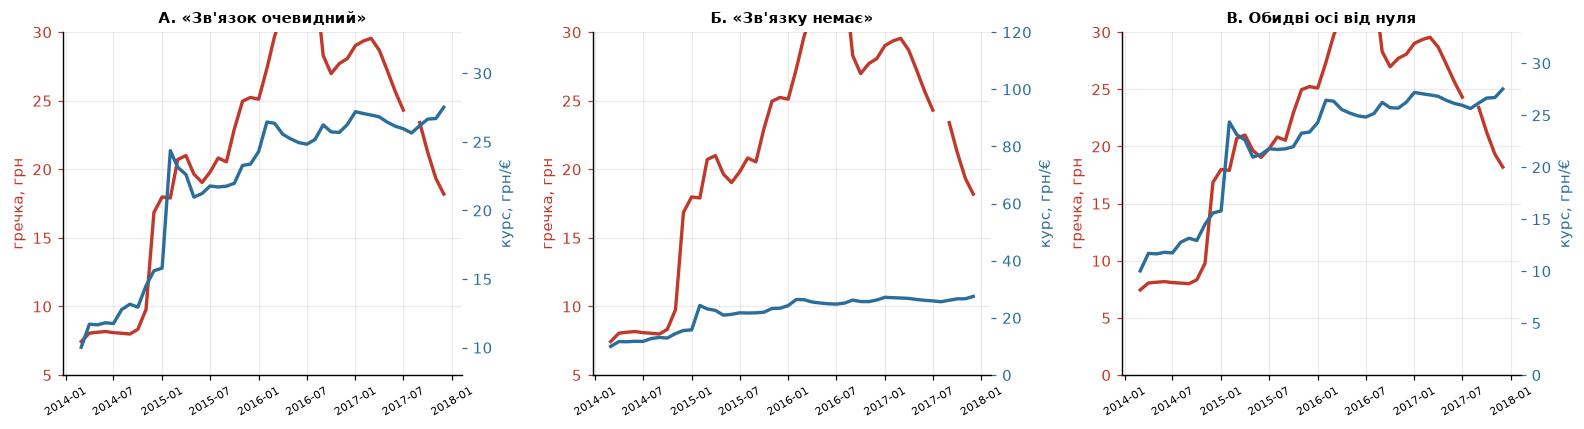

In [14]:
rate_w = uah['2014-03':'2017-12']

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))

def two_axes(ax, ylim1, ylim2, title):
    ax.plot(buckwheat.index, buckwheat.values, lw=2.2, color='#C0392B')
    ax.set_ylabel('гречка, грн', color='#C0392B'); ax.tick_params(axis='y', colors='#C0392B')
    if ylim1: ax.set_ylim(*ylim1)
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(rate_w.index, rate_w.values, lw=2.2, color='#2C6E9B')
    ax2.set_ylabel('курс, грн/€', color='#2C6E9B'); ax2.tick_params(axis='y', colors='#2C6E9B')
    if ylim2: ax2.set_ylim(*ylim2)
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.tick_params(axis='x', labelrotation=30, labelsize=7)

two_axes(axes[0], (5, 30),   (8, 33),   'A. «Зв\'язок очевидний»')
two_axes(axes[1], (5, 30),   (0, 120),  'Б. «Зв\'язку немає»')
two_axes(axes[2], (0, 30),   (0, 33),   'В. Обидві осі від нуля')
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

**Питання поставлене неправильно, і в цьому вся суть.** Графік із двома осями Y
**не може** ані показати зв'язок, ані спростувати його. Пересунувши межі осей, я змусив
ті самі два ряди то зливатися, то розходитися. Дані не змінилися жодного разу.

Дві осі Y дають авторові **два вільні параметри на кожен ряд** — зсув і масштаб. Цього достатньо,
щоб підігнати будь-яку пару рядів під будь-який бажаний вигляд.

**Що робити замість цього** — два чесні способи:

1. **Нормувати обидва ряди** до спільної бази (перше значення = 100) і малювати на одній осі.
   Тоді вертикальне положення щось означає.
2. **Побудувати діаграму розсіювання** одного проти одного й порахувати коефіцієнт кореляції —
   число, яке не залежить від меж осей.

Нижче — обидва.

</details>

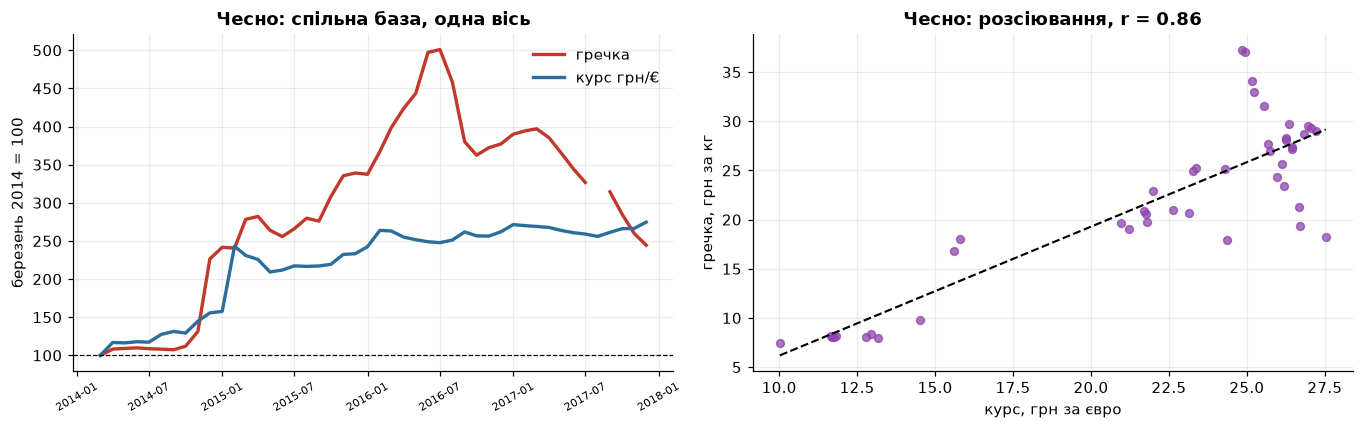

Коефіцієнт кореляції Пірсона: r = 0.863
Це число не залежить від того, які межі осей я оберу. Саме тому йому можна вірити.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))

# 1. Спільна база: березень 2014 = 100, одна вісь
buck100 = buckwheat / buckwheat.iloc[0] * 100
rate100 = rate_w / rate_w.iloc[0] * 100
axes[0].plot(buck100.index, buck100.values, lw=2.2, color='#C0392B', label='гречка')
axes[0].plot(rate100.index, rate100.values, lw=2.2, color='#2C6E9B', label='курс грн/€')
axes[0].axhline(100, color='k', lw=.8, ls='--')
axes[0].set_ylabel('березень 2014 = 100'); axes[0].legend(frameon=False)
axes[0].set_title('Чесно: спільна база, одна вісь', fontweight='bold')
axes[0].tick_params(axis='x', labelrotation=30, labelsize=7)

# 2. Розсіювання
pair = pd.concat([buckwheat.rename('гречка'), rate_w.rename('курс')], axis=1).dropna()
axes[1].scatter(pair['курс'], pair['гречка'], s=26, color='#8E44AD', alpha=.75)
k, b = np.polyfit(pair['курс'], pair['гречка'], 1)
xx = np.linspace(pair['курс'].min(), pair['курс'].max(), 50)
axes[1].plot(xx, k*xx + b, color='k', lw=1.4, ls='--')
r = pair['курс'].corr(pair['гречка'])
axes[1].set_xlabel('курс, грн за євро'); axes[1].set_ylabel('гречка, грн за кг')
axes[1].set_title(f'Чесно: розсіювання, r = {r:.2f}', fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Коефіцієнт кореляції Пірсона: r = {r:.3f}')
print('Це число не залежить від того, які межі осей я оберу. Саме тому йому можна вірити.')

Зверніть увагу: на діаграмі розсіювання **втрачено час**. Точки більше не впорядковані,
і ми не бачимо, що було раніше, а що пізніше. Для часових рядів це серйозна втрата —
саме через неї висока кореляція двох зростаючих рядів майже нічого не доводить.
До цього ми повернемось на кроці 5.

### Теорія: чим небезпечне агрегування

Середнє — це **стиснення**: із $n$ чисел ми робимо одне. Будь-яке стиснення втрачає
інформацію, питання лише в тому, яку саме.

**Перша втрата — розкид.** Класична ілюстрація — **квартет Анскомба** (1973):
чотири набори по одинадцять точок з однаковими середніми, однаковими дисперсіями,
однаковою кореляцією та однаковою лінією регресії — і цілком різними графіками.
Пізніша версія, **Datasaurus Dozen** (2017), доводить те саме ефектніше:
один із наборів із тими самими статистиками при побудові дає силует динозавра.

**Друга втрата — неоднорідність груп.** Якщо середнє рахується по групах різного розміру
або різної природи, воно може не відповідати жодній із них. Крайній випадок —
**парадокс Сімпсона**: напрямок залежності в об'єднаних даних протилежний до напрямку
в кожній із груп окремо.

**Третя, специфічна для просторових і соціальних даних, — екологічна помилка**
(*ecological fallacy*): перенесення висновку, отриманого на агрегованих даних (області, країни),
на окремі об'єкти (людей). З того, що в області вища середня ціна, не випливає,
що конкретний мешканець платить більше.

**Практичне правило:** щоразу, коли ви показуєте агреговану величину, показуйте поруч
**розподіл, з якого вона порахована** — boxplot, скрипковий графік, розсіювання окремих
значень або просто всі криві світлим кольором. Це коштує один рядок коду
й рятує від усіх трьох помилок одразу.

## 2.4. Середнє, яке ховає розкид

Перший графік лекції побудовано на «National Average». Подивімось, що саме це середнє приховало.

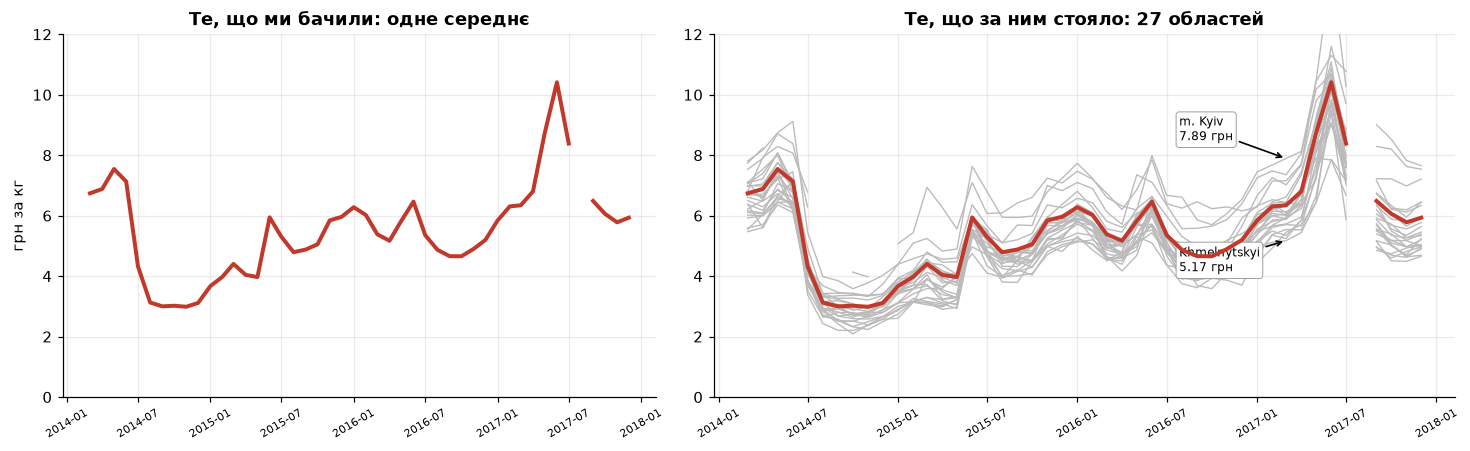

Березень 2017, картопля по областях:
  найдешевше: Khmelnytskyi — 5.17 грн
  найдорожче: m. Kyiv — 7.89 грн
  середнє: 6.15 грн, розмах у 1.53 раза


In [16]:
potato = (prices[(prices['товар'] == 'Potatoes - Retail') & (prices['ринок'] != 'National Average')]
            .pivot_table(index='дата', columns='ринок', values='ціна')
            .reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS')))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), gridspec_kw=dict(width_ratios=[1, 1.25]))

axes[0].plot(avg.index, avg['Potatoes - Retail'], lw=2.6, color='#C0392B')
axes[0].set_title('Те, що ми бачили: одне середнє', fontweight='bold')
axes[0].set_ylabel('грн за кг'); axes[0].set_ylim(0, 12)

axes[1].plot(potato.index, potato.values, lw=.9, color='#bbb')
axes[1].plot(avg.index, avg['Potatoes - Retail'], lw=2.6, color='#C0392B', zorder=5)
axes[1].set_title('Те, що за ним стояло: 27 областей', fontweight='bold')
axes[1].set_ylim(0, 12)

snap = potato.loc['2017-03-01'].dropna()
for reg, dy in [(snap.idxmax(), 12), (snap.idxmin(), -20)]:
    axes[1].annotate(f'{reg}\n{snap[reg]:.2f} грн',
                     xy=(pd.Timestamp('2017-03-01'), snap[reg]), xytext=(-70, dy),
                     textcoords='offset points', fontsize=8,
                     bbox=dict(boxstyle='round,pad=.25', fc='white', ec='#999', lw=.6),
                     arrowprops=dict(arrowstyle='->', lw=1.1))
for ax in axes: ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print('Березень 2017, картопля по областях:')
print(f'  найдешевше: {snap.idxmin()} — {snap.min():.2f} грн')
print(f'  найдорожче: {snap.idxmax()} — {snap.max():.2f} грн')
print(f'  середнє: {snap.mean():.2f} грн, розмах у {snap.max()/snap.min():.2f} раза')

Розкид не катастрофічний, але він є, і середнє про нього не повідомляє.
Проблема не в тому, що середнє «неправильне» — воно правильне. Проблема в тому, що
**середнє відповідає на питання, якого ніхто не ставив**: ніхто не купує картоплю за національною
середньою ціною, кожен купує її у своїй області.

Універсальний прийом: коли показуєте агреговану величину, **покажіть поруч розподіл**,
з якого її пораховано. Це коштує один рядок коду.

### Теорія: коли змінюється сам об'єкт вимірювання

Досі ми говорили про те, що середнє ховає **розкид між об'єктами**. Є значно
підступніша ситуація: змінюється **сам склад об'єктів**, за якими рахують середнє.

Явище має кілька назв залежно від контексту:

* **Зміна складу вибірки** (*composition change*) — набір об'єктів у групі змінився між періодами.
* **Помилка виживання** (*survivorship bias*) — до пізніших періодів «дожили» не всі об'єкти,
  і ті, що дожили, відрізняються від тих, що зникли, систематично.
* **Зміщення відбору** (*selection bias*) — загальна назва для ситуації, коли ймовірність
  потрапити у вибірку залежить від величини, яку ми вивчаємо.

Класичний приклад помилки виживання — робота **Абрагама Вальда** з поверненими бомбардувальниками
під час Другої світової війни. Аналітики пропонували посилити броню там, де на літаках
було найбільше пробоїн. Вальд указав на протилежне: пробоїни на повернених літаках
показують місця, ушкодження яких **сумісні з поверненням**; бронювати треба там,
де пробоїн немає, бо звідти не поверталися.

**Чому це критично саме для часових рядів.** У звичайній таблиці зміна складу помітна одразу:
рядків стало менше. У ряді вона **маскується**, бо ряд лишається неперервною лінією,
і в кожній точці є число. Дивлячись на лінію, ви не бачите, що за нею стоїть різний набір об'єктів.

**Як це виявляти.** Не аналізуйте лише значення — аналізуйте **індикатор наявності**:
$$\mathbb{1}_{it} = \begin{cases} 1, & \text{об'єкт } i \text{ виміряно в момент } t\\ 0, & \text{інакше}\end{cases}$$
Теплова карта цієї матриці — один із найдешевших і найінформативніших діагностичних
графіків, які взагалі існують. Наступна клітинка саме її й будує.

## 2.5. Середнє, яке ховає те, чого вже немає

Розкид — не найбільше з того, що приховало національне середнє. Подивімось не на значення,
а на **сам факт наявності запису**: для кожного ринку й кожного місяця позначимо, є там вимір чи ні.

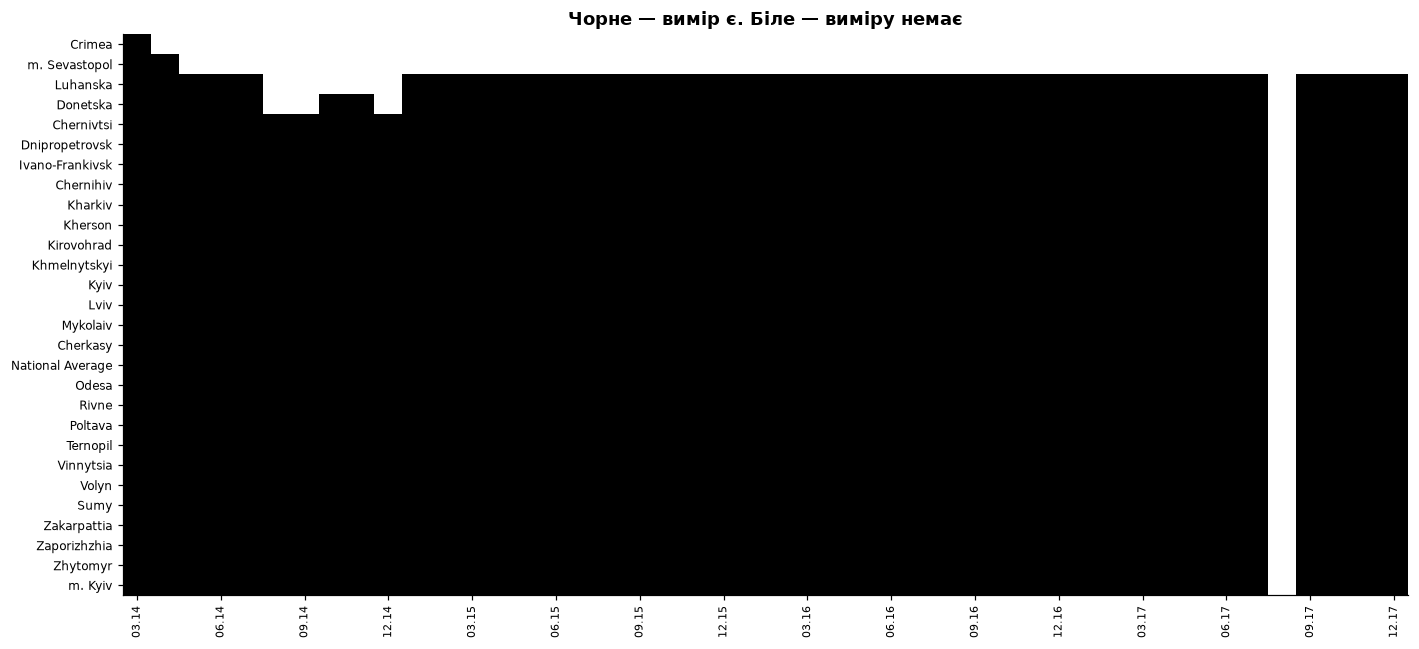

Скільки місяців із 46 у сітці мають хоч один вимір:
ринок
Crimea             1
m. Sevastopol      2
Luhanska          40
Donetska          42
Chernivtsi        45
Dnipropetrovsk    45


In [17]:
present = (prices.pivot_table(index='ринок', columns='дата', values='ціна', aggfunc='size')
             .reindex(columns=pd.date_range('2014-03-01', '2017-12-01', freq='MS'))
             .notna().astype(int))
present = present.loc[present.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(present.values, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(len(present))); ax.set_yticklabels(present.index, fontsize=8)
ticks = range(0, present.shape[1], 3)
ax.set_xticks(list(ticks))
ax.set_xticklabels([present.columns[i].strftime('%m.%y') for i in ticks], fontsize=7, rotation=90)
ax.set_title('Чорне — вимір є. Біле — виміру немає', fontweight='bold')
ax.grid(False)
plt.tight_layout(); plt.show()

print('Скільки місяців із 46 у сітці мають хоч один вимір:')
print(present.sum(axis=1).sort_values().head(6).to_string())

Верхні рядки теплової карти — майже суцільно білі.

* **Crimea** — останній вимір у **березні 2014**.
* **m. Sevastopol** — останній вимір у **квітні 2014**.
* **Luhanska** — немає вимірів із **серпня по грудень 2014**.
* **Donetska** — немає вимірів за **серпень, вересень і грудень 2014**.
* І тонка біла смуга через усю карту — **серпень 2017**, коли вимірів немає взагалі ніде.

Збір даних припинився там і тоді, де й коли припинився доступ до ринків.
Дати в таблиці збігаються з датами подій, які ви знаєте без моїх пояснень.

Для нас із вами тут важливе методологічне: **національне середнє за 2015 рік і національне середнє
за 2014 рік пораховані по різних наборах областей**. Формально це один ряд. Фактично — два різні
об'єкти вимірювання, зшиті в одну лінію. Порівнюючи їх, ми порівнюємо не лише ціни.

Це та сама думка, з якою ми працювали в третій лекції: **пропуск — не порожнє місце, а повідомлення**.
Різниця в тому, що там пропуски були розкидані по таблиці, а тут вони мають **структуру в часі** —
і саме з цього починається розмова про часові ряди.

### Теорія: номінальні та реальні величини

Будь-яка сума грошей є добутком двох величин: **кількості товару** та **ціни грошової одиниці**.
Порівнюючи суми за різні періоди, ми порівнюємо добутки — і приписуємо всю зміну першому
множнику, хоча насправді змінився і другий.

**Номінальна величина** виміряна в грошових одиницях того періоду, до якого належить.
**Реальна величина** приведена до спільної бази й придатна для порівняння між періодами.

Перехід виконують діленням на **дефлятор** $P_t$ — показник рівня цін у період $t$:

$$y^{\text{реал}}_t = \frac{y^{\text{ном}}_t}{P_t} \cdot P_{t_0}$$

**Що брати за дефлятор** — залежить від питання, на яке ви відповідаєте:

| Дефлятор | Відповідає на питання |
|---|---|
| Індекс споживчих цін (ІСЦ, CPI) | чи подорожчав товар **відносно інших товарів** для споживача |
| Дефлятор ВВП | чи подорожчав він відносно всього, що виробляється в країні |
| Курс іноземної валюти | скільки товар коштує **в міжнародному вимірі** |
| Середня зарплата | скільки **праці** треба віддати за товар |

У цьому зошиті ми беремо **курс до євро**. Це не найкращий дефлятор для споживчої інфляції —
для неї правильніший ІСЦ, — але він має дві переваги для навчання: він є у нас у файлі,
і він відповідає на змістовне питання «скільки цей товар коштує в міжнародному вимірі».

**Важлива пересторога.** Дефлювання не дає «правдивішої» відповіді — воно дає **іншу**.
Для людини, яка отримує зарплату в гривні, номінальне подорожчання є цілком реальним
досвідом. Обидва графіки правдиві; питання в тому, чий саме досвід ви описуєте.
Саме тому в економічній статистиці **завжди вказують**, у цінах якого року подано суму.

## 2.6. І нарешті — чому перша відповідь була неправильною

## ❓ Питання 5

Ліворуч — ціна хліба в гривні. Праворуч — **та сама ціна того самого хліба в ті самі місяці**,
переведена в євро за офіційним курсом. **Який із графіків правдивий?**

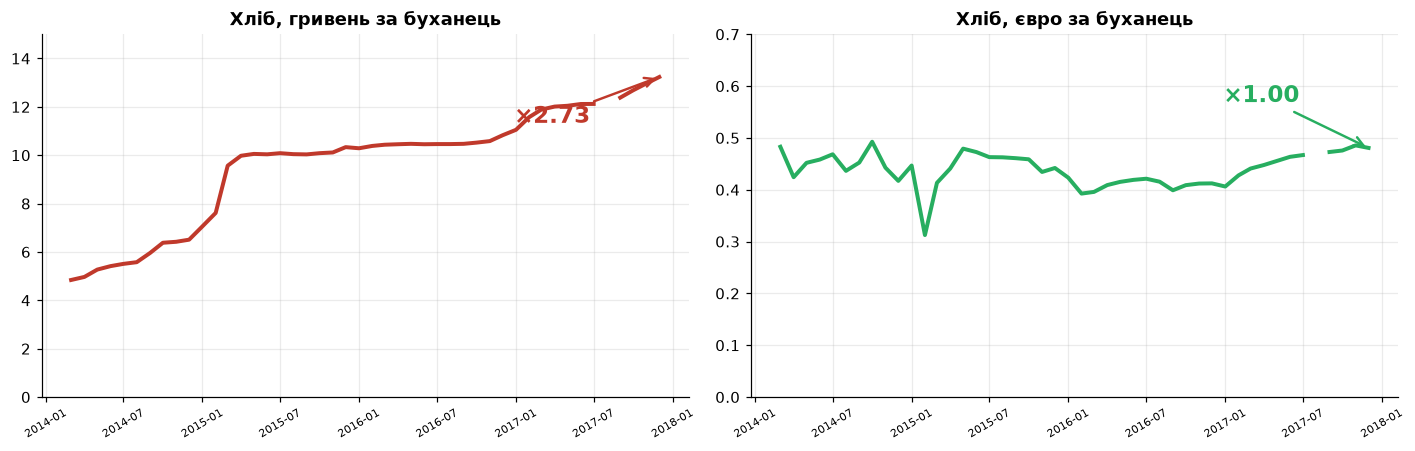

In [18]:
rate_m = uah.reindex(avg.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(bread.index, bread.values, lw=2.6, color='#C0392B')
axes[0].set_title('Хліб, гривень за буханець', fontweight='bold'); axes[0].set_ylim(0, 15)
axes[0].annotate(f'×{bread.iloc[-1]/bread.iloc[0]:.2f}', xy=(bread.index[-1], bread.iloc[-1]),
                 xytext=(-95, -30), textcoords='offset points', fontsize=15,
                 fontweight='bold', color='#C0392B',
                 arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.6))

bread_eur = bread / rate_m
axes[1].plot(bread_eur.index, bread_eur.values, lw=2.6, color='#27AE60')
axes[1].set_title('Хліб, євро за буханець', fontweight='bold'); axes[1].set_ylim(0, .7)
axes[1].annotate(f'×{bread_eur.iloc[-1]/bread_eur.iloc[0]:.2f}', xy=(bread_eur.index[-1], bread_eur.iloc[-1]),
                 xytext=(-95, 30), textcoords='offset points', fontsize=15,
                 fontweight='bold', color='#27AE60',
                 arrowprops=dict(arrowstyle='->', color='#27AE60', lw=1.6))
for ax in axes: ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

**Обидва.** І саме тому питання «чи подорожчала їжа» досі не має відповіді — воно погано поставлене.

У гривні хліб подорожчав майже втричі. У євро його ціна **не змінилася зовсім**.
Обидва твердження описують ту саму реальність із різних боків:
для того, хто отримує зарплату в гривні, хліб став утричі дорожчим;
для того, хто дивиться на вартість хліба як товару в світових цінах, не змінилося нічого.

Ми весь цей час малювали **дві величини, які змішалися в одному числі**: вартість товару й вартість грошей.
Перший графік лекції не брехав про гречку — він просто здебільшого показував курс гривні.

Ось що дає ця ж операція для інших товарів.

</details>

,товар,грн 03.2014,грн 12.2017,"у грн, разів",€ 03.2014,€ 12.2017,"у євро, разів"
0,хліб,4.84,13.23,2.73,0.48,0.48,1.00
1,гречка,7.44,18.19,2.44,0.74,0.66,0.89
2,свинина,44.78,99.67,2.23,4.47,3.62,0.81
3,цукор,8.90,12.69,1.42,0.89,0.46,0.52
4,молоко,7.94,18.51,2.33,0.79,0.67,0.85
5,капуста,3.63,4.33,1.19,0.36,0.16,0.43


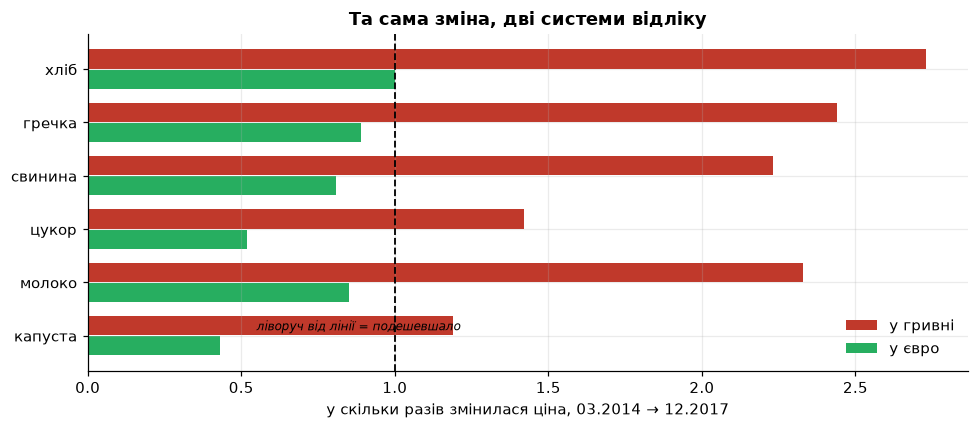

Курс гривні до євро: 10.02 → 27.53, у 2.75 раза


In [19]:
rows = []
for g in ['Bread (wheat) - Retail', 'Buckwheat grits - Retail', 'Meat (pork) - Retail',
          'Sugar - Retail', 'Milk - Retail', 'Cabbage - Retail']:
    s = avg[g]; s_eur = s / rate_m
    rows.append([UA[g], s.iloc[0], s.iloc[-1], s.iloc[-1]/s.iloc[0],
                  s_eur.iloc[0], s_eur.iloc[-1], s_eur.iloc[-1]/s_eur.iloc[0]])
cmp_cur = pd.DataFrame(rows, columns=['товар', 'грн 03.2014', 'грн 12.2017', 'у грн, разів',
                                     '€ 03.2014', '€ 12.2017', 'у євро, разів']).round(2)
display(cmp_cur)

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(cmp_cur))
ax.barh(y - .19, cmp_cur['у грн, разів'],   height=.36, color='#C0392B', label='у гривні')
ax.barh(y + .19, cmp_cur['у євро, разів'], height=.36, color='#27AE60', label='у євро')
ax.axvline(1, color='k', lw=1.2, ls='--')
ax.set_yticks(y); ax.set_yticklabels(cmp_cur['товар']); ax.invert_yaxis()
ax.set_xlabel('у скільки разів змінилася ціна, 03.2014 → 12.2017')
ax.set_title('Та сама зміна, дві системи відліку', fontweight='bold')
ax.legend(frameon=False)
ax.annotate('ліворуч від лінії = подешевшало', xy=(.55, len(cmp_cur)-1.1), fontsize=8, style='italic')
plt.tight_layout(); plt.show()

print(f'Курс гривні до євро: {rate_m.iloc[0]:.2f} → {rate_m.iloc[-1]:.2f}, '
      f'у {rate_m.iloc[-1]/rate_m.iloc[0]:.2f} раза')

Цукор у гривні подорожчав у півтора раза — а в євро **подешевшав удвічі**.
Дві стовпчикові діаграми, обидві з правдивих чисел, протилежні висновки.

> **Правило:** перш ніж порівнювати величини в грошах за різні роки, спитайте себе,
> чи не змінилася сама одиниця вимірювання. Гривня 2014 року й гривня 2017 року — **різні одиниці**,
> як і долар 1990 року та долар сьогодні. Порівняння номінальних сум за різні періоди без
> приведення до спільної бази — найпоширеніша помилка в аналізі економічних даних.

### Теорія: чому веселкова палітра погана

Проблема має точне формулювання: **сприйняттєва нерівномірність**.

Колір у комп'ютері задають у просторі RGB, але око сприймає не RGB. Щоб описати
сприйняття, побудували простори на кшталт **CIELAB**, у яких евклідова відстань між
двома кольорами приблизно пропорційна тому, наскільки різними їх бачить людина.
Палітра називається **сприйняттєво рівномірною**, якщо однаковим крокам за величиною
відповідають однакові відстані в CIELAB.

Палітра `jet` (успадкована з MATLAB) цій умові не задовольняє **категорично**:

1. **Нерівномірність.** Перехід зелений → жовтий око читає як різкий стрибок,
   а такий самий за величиною перехід усередині синього — як плавний. Палітра малює
   межі там, де в даних їх немає, і приховує межі там, де вони є.
2. **Немонотонна світлість.** Світлість уздовж `jet` зростає, потім спадає, потім знову зростає.
   Для чорно-білого друку це означає, що різні значення дають однаковий сірий.
3. **Відсутність природного порядку.** Ніхто не знає напам'ять, що червоне більше за фіолетове.

Замість неї в matplotlib типовою зробили **`viridis`** — палітру, спеціально побудовану так,
щоб світлість зростала **монотонно й лінійно**, а сама вона лишалася розрізнюваною
для людей із порушенням кольоросприйняття.

### Порушення кольоросприйняття

| Тип | Що саме | Поширеність серед чоловіків |
|---|---|---|
| Дейтераномалія / дейтеранопія | послаблене або відсутнє сприйняття зеленого | близько 6% |
| Протаномалія / протанопія | послаблене або відсутнє сприйняття червоного | близько 2% |
| Тританопія | порушення сприйняття синього | менш як 0,01% |

Разом це приблизно **8% чоловіків і 0,5% жінок**. У групі з тридцяти студентів
майже напевно є один такий. Пара «червоне — зелене», найпоширеніша в бізнес-графіці,
для них не розрізнювана.

**Практичне правило, яке розв'язує проблему повністю:** колір ніколи не має бути
**єдиним** носієм змісту. Дублюйте його типом лінії, формою маркера, підписом або
положенням — і графік переживе і дальтонізм, і чорно-білий друк, і поганий проєктор.

Наступна клітинка містить просту модель дейтеранопії, щоб ви могли перевіряти
власні палітри самостійно.

## 2.7. Колір — це теж шкала, і її теж можна обрати неправильно

Колір у граматиці графіки — така сама естетика, як положення чи розмір. А отже, палітра має
відповідати типу величини, яку вона кодує.

| Тип величини | Яка палітра | Приклад |
|---|---|---|
| номінальна (категорії) | якісна, кольори розрізнювані й рівноправні | області, товари |
| впорядкована/кількісна від нуля | послідовна, від світлого до темного | ціна, кількість |
| кількісна з осмисленою серединою | розбіжна, дві гілки від нейтрального центру | відхилення від норми, зміна у % |

## ❓ Питання 6

Нижче та сама теплова карта в трьох палітрах. **Яка палітра правильна і чому дві інші шкодять?**

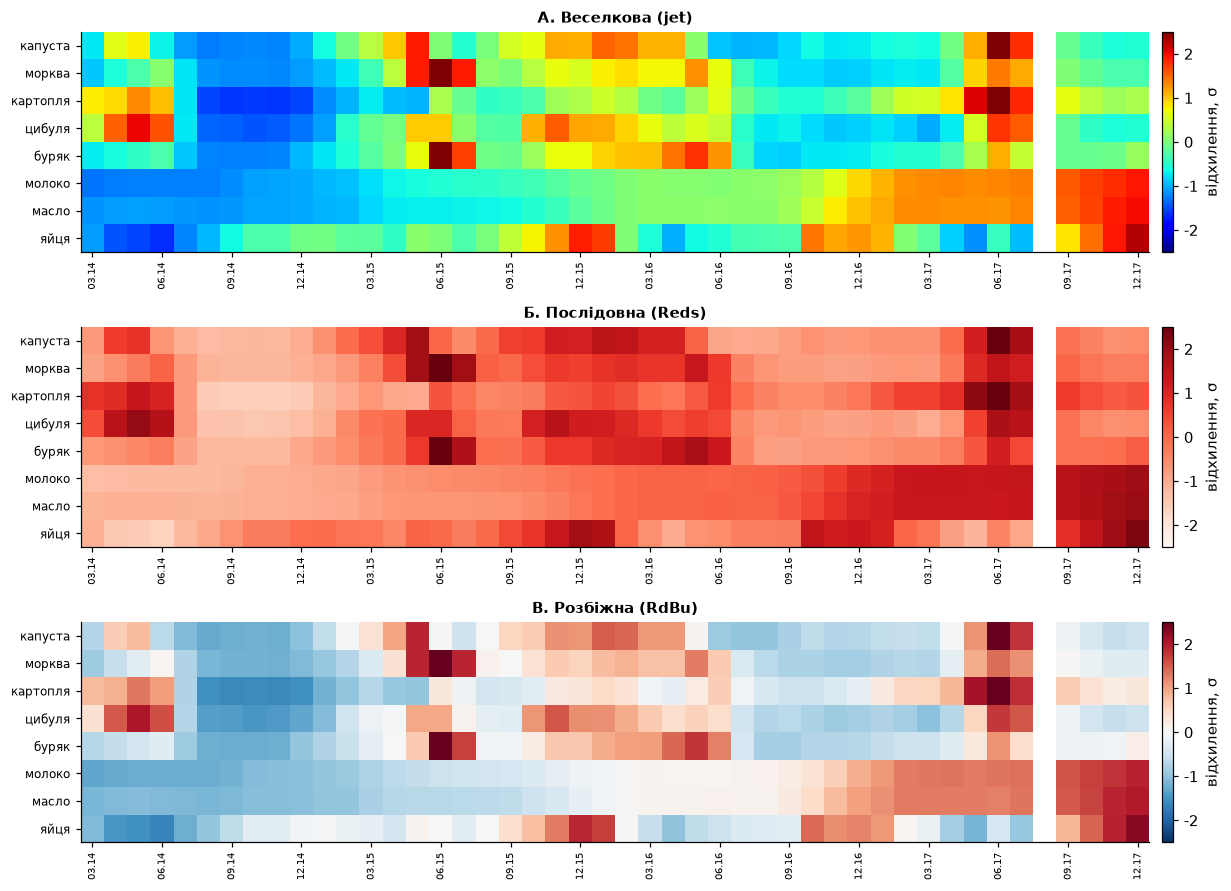

In [20]:
seas = (avg[['Cabbage - Retail', 'Carrots - Retail', 'Potatoes - Retail', 'Onions - Retail',
                'Beetroots - Retail', 'Milk - Retail', 'Butter - Retail', 'Eggs - Retail']]
         .apply(lambda s: (s - s.mean())/s.std()))
seas.columns = [UA[c] for c in seas.columns]
M = seas.T.values

fig, axes = plt.subplots(3, 1, figsize=(12.5, 8.2))
for ax, (cm, title) in zip(axes, [('jet', 'A. Веселкова (jet)'),
                                  ('Reds', 'Б. Послідовна (Reds)'),
                                  ('RdBu_r', 'В. Розбіжна (RdBu)')]):
    im = ax.imshow(M, aspect='auto', cmap=cm, vmin=-2.5, vmax=2.5, interpolation='nearest')
    ax.set_yticks(range(len(seas.columns))); ax.set_yticklabels(seas.columns, fontsize=8)
    ax.set_xticks(range(0, M.shape[1], 3))
    ax.set_xticklabels([seas.index[i].strftime('%m.%y') for i in range(0, M.shape[1], 3)],
                       fontsize=6.5, rotation=90)
    ax.set_title(title, fontweight='bold', fontsize=10); ax.grid(False)
    plt.colorbar(im, ax=ax, pad=.01, label='відхилення, σ')
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

Правильна — **В, розбіжна**. Величина на карті це відхилення від власного середнього,
тобто в неї є **осмислений центр — нуль**. Розбіжна палітра показує нуль нейтральним кольором,
а два напрямки відхилення — двома різними гілками. Око одразу розділяє «дорожче за звичайне»
і «дешевше за звичайне».

**Б (послідовна)** не помилка, але тут недоречна: вона подає величину як таку, що зростає від малого
до великого, і центр у ній нічим не виділений. Для ціни в гривнях вона була б ідеальною,
для відхилення — ні.

**А (веселкова)** шкідлива, і на це є три причини:

1. Вона **нерівномірна за сприйняттям**: перехід від зеленого до жовтого око читає як різкий стрибок,
   а такий самий за величиною перехід усередині синього — як плавний. Палітра малює межі там, де їх немає.
2. У ній **немає природного порядку**. Ніхто не знає напам'ять, що червоне більше за фіолетове, —
   читач мусить щоразу звірятися зі шкалою.
3. Після чорно-білого друку чи в очах людини з порушенням кольоросприйняття вона розсипається повністю.

Саме тому `jet` прибрали з типових палітр у matplotlib, а типовою зробили `viridis`.

</details>

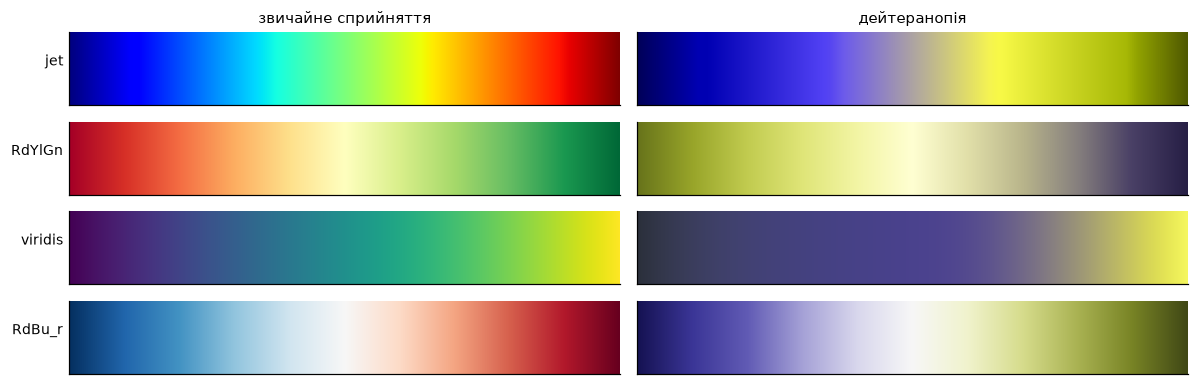

In [21]:
# Як виглядають палітри для людини з дейтеранопією (~8% чоловіків)
def deuteranopia(rgb):
    """Груба, але достатня для демонстрації модель: матриця Віньо-Брета."""
    M = np.array([[0.625, 0.375, 0.0],
                  [0.70,  0.30,  0.0],
                  [0.0,   0.30,  0.70]])
    return np.clip(rgb @ M.T, 0, 1)

strip = np.linspace(0, 1, 256).reshape(1, -1)
fig, axes = plt.subplots(4, 2, figsize=(11, 3.6))
for i, cm in enumerate(['jet', 'RdYlGn', 'viridis', 'RdBu_r']):
    rgb = plt.get_cmap(cm)(strip)[..., :3]
    axes[i, 0].imshow(rgb, aspect='auto'); axes[i, 0].set_ylabel(cm, rotation=0, ha='right', fontsize=9)
    axes[i, 1].imshow(deuteranopia(rgb[0]).reshape(1, -1, 3), aspect='auto')
    for j in (0, 1):
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([]); axes[i, j].grid(False)
axes[0, 0].set_title('звичайне сприйняття', fontsize=10)
axes[0, 1].set_title('дейтеранопія', fontsize=10)
plt.tight_layout(); plt.show()

Подивіться на другий рядок — **RdYlGn**, класична пара «червоне погано / зелене добре».
Для людини з дейтеранопією обидва кінці шкали зливаються в один брудно-жовтий,
і графік перестає нести будь-яку інформацію.

> **Правило:** колір ніколи не має бути **єдиним** носієм змісту. Дублюйте його формою маркера,
> типом лінії, підписом або положенням. Тоді графік переживе і чорно-білий друк, і дальтонізм,
> і поганий проєктор в аудиторії.

---
### Підсумок кроку 2

Ми жодного разу не змінили дані. Ми міняли тільки **шари граматики** — шкали, вікно, естетику, агрегування.
І щоразу отримували інший висновок.

**Висновок, який варто винести:** графік — це не ілюстрація до аналізу, це **частина аналізу**,
і в ньому стільки ж місця для помилки, скільки в будь-якій формулі. Різниця лише в тому,
що помилку у формулі рецензент помітить, а помилку в межах осі — ні.

---
### Проміжна відповідь 2

**«Залежно від того, у чому міряти».** У гривні хліб подорожчав у 2,73 раза; у євро його ціна
не змінилася зовсім. Обидва твердження правдиві, бо початкове питання не вказувало системи відліку.

Крім того, ми виявили, що національне середнє за 2014 і за 2015 роки пораховане
**по різних наборах областей**, тобто це формально один ряд, а фактично два різні об'єкти.

Відповідь уточнено, але залишилося питання, якого ми досі не ставили:
**чи маємо ми взагалі право аналізувати ці дані як звичайну таблицю?**

---
# Крок 3. Це не таблиця. Це часовий ряд

> **Підзадача кроку.** З'ясувати, що саме змінюється в аналізі через те, що дані
> **впорядковані в часі**, розібратися з пропусками й розкласти ряд на складові —
> тобто підготувати його до прогнозування.

Дотепер ми поводилися з даними як зі звичайною таблицею. Настав час сказати вголос,
чим часовий ряд від таблиці відрізняється — і чому це змінює геть усе.

**Три властивості, яких немає у звичайної таблиці:**

1. **Впорядкованість.** Рядки не можна переставляти місцями. У звичайній таблиці порядок рядків
   не несе інформації; у ряді він і є інформацією.
2. **Залежність спостережень.** Ціна в квітні залежить від ціни в березні. Більшість статистичних
   методів припускають незалежність спостережень — і на рядах ці припущення порушено.
3. **Напрямок часу.** Минуле пояснює майбутнє, але не навпаки. Ця несиметричність робить
   недійсними звичні прийоми перевірки моделей — до цього дійдемо на кроці 4.

### Теорія: формальне означення

**Часовий ряд** — це послідовність спостережень $\{y_t\}_{t=1}^{n}$, впорядкована в часі.
За цим простим означенням ховається важливе припущення: ми вважаємо, що спостереження
породжені **випадковим процесом** $\{Y_t\}$, а наш ряд є однією його **реалізацією**.

У цьому й полягає головна відмінність від звичайної статистики. Коли ми міряємо зріст
ста людей, у нас сто незалежних спостережень однієї випадкової величини. Коли ми міряємо
ціну сто місяців поспіль, у нас **одна** реалізація процесу завдовжки сто — і все,
що ми можемо про процес дізнатися, ми мусимо дізнатися з неї.

**Автоковаріаційна функція** описує зв'язок ряду із самим собою на відстані $k$:

$$\gamma_k = \operatorname{Cov}(Y_t,\, Y_{t+k}) = \mathbb{E}\big[(Y_t-\mu)(Y_{t+k}-\mu)\big]$$

**Автокореляційна функція (ACF)** — її нормована версія, тобто коефіцієнт кореляції
ряду зі зсунутою копією самого себе:

$$\rho_k = \frac{\gamma_k}{\gamma_0}, \qquad -1 \le \rho_k \le 1, \qquad \rho_0 = 1$$

На вибірці її оцінюють так:

$$\hat\rho_k = \frac{\sum_{t=1}^{n-k}(y_t-\bar y)(y_{t+k}-\bar y)}{\sum_{t=1}^{n}(y_t-\bar y)^2}$$

**Межі значущості.** Якщо ряд є білим шумом, то $\hat\rho_k$ для $k \ne 0$ приблизно
нормально розподілені із середнім 0 і стандартним відхиленням $1/\sqrt{n}$. Звідси
95-відсоткові межі:

$$\pm \frac{1{,}96}{\sqrt{n}}$$

Це та сама сіра смуга, яку ви побачите на графіках. **Зверніть увагу на $\sqrt{n}$ у знаменнику:**
на 45 спостереженнях смуга має піввисоту $1{,}96/\sqrt{45} \approx 0{,}29$, а на 347 —
лише $0{,}11$. Ось чому короткий ряд знецінює висновки ACF: майже все потрапляє в межі,
і відрізнити структуру від шуму неможливо.

**Чому описові статистики сліпі до порядку.** Середнє, дисперсія, медіана, квантилі —
усі вони є функціями **мультимножини** значень, тобто не змінюються при перестановці.
Наступна клітинка перевіряє це експериментально.

## 3.1. Перевіримо, що порядок справді щось означає

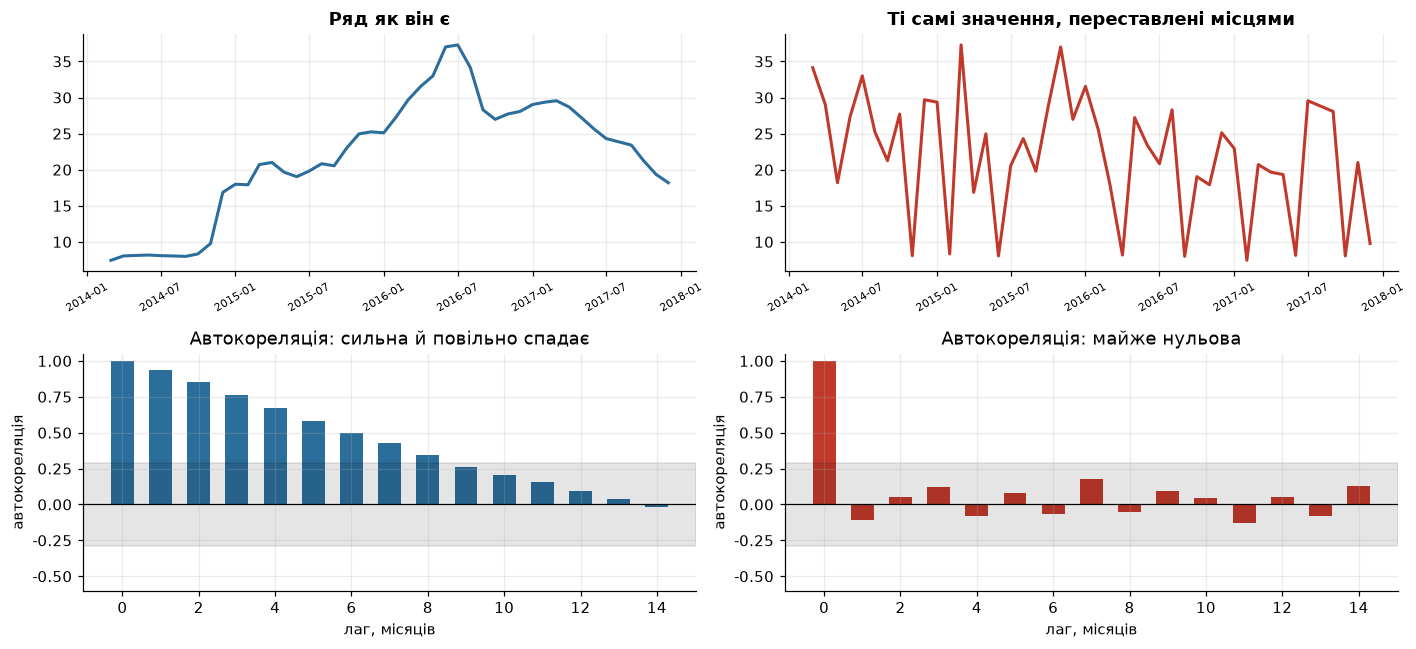

Описові статистики ідентичні — перестановка їх не змінює:
          ряд  перемішаний
count  45.000       45.000
mean   21.860       21.860
std     8.448        8.448
min     7.443        7.443
25%    17.987       17.987
50%    22.937       22.937
75%    28.070       28.070
max    37.287       37.287


In [22]:
from statsmodels.tsa.stattools import acf

series = buckwheat.dropna()
rng = np.random.default_rng(42)
shuffled = pd.Series(rng.permutation(series.values), index=series.index)

fig, axes = plt.subplots(2, 2, figsize=(13, 6))

axes[0,0].plot(series.index, series.values, lw=2, color='#2C6E9B')
axes[0,0].set_title('Ряд як він є', fontweight='bold')
axes[0,1].plot(shuffled.index, shuffled.values, lw=2, color='#C0392B')
axes[0,1].set_title('Ті самі значення, переставлені місцями', fontweight='bold')

for ax, s, c in [(axes[1,0], series, '#2C6E9B'), (axes[1,1], shuffled, '#C0392B')]:
    a = acf(s, nlags=14)
    ax.bar(range(len(a)), a, color=c, width=.6)
    bound = 1.96/np.sqrt(len(s))
    ax.axhspan(-bound, bound, color='k', alpha=.10)
    ax.axhline(0, color='k', lw=.8)
    ax.set_xlabel('лаг, місяців'); ax.set_ylabel('автокореляція'); ax.set_ylim(-.6, 1.05)
axes[1,0].set_title('Автокореляція: сильна й повільно спадає')
axes[1,1].set_title('Автокореляція: майже нульова')
for ax in axes[0]: ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print('Описові статистики ідентичні — перестановка їх не змінює:')
print(pd.DataFrame({'ряд': series.describe(), 'перемішаний': shuffled.describe()}).round(3))

Середнє, медіана, стандартне відхилення, мінімум, максимум — **усе збіглося до останнього знаку**.
Гістограми теж були б однакові. І при цьому другий ряд не містить жодної корисної інформації.

Це означає, що **всі описові статистики, якими ми користувалися в третій лекції, сліпі до порядку**.
Для часового ряду потрібен інший інструмент, і він у нас уже з'явився внизу: **автокореляційна функція**,
тобто кореляція ряду із самим собою, зсунутим на *k* кроків назад.

У лівому нижньому полі видно, що сусідні місяці корелюють на рівні близько 0,9 і зв'язок спадає повільно.
У правому — усі значення в сірій смузі, тобто невідрізнювані від нуля.
Сіра смуга — це межі ±1,96/√n, за якими автокореляцію вважають значущою.

### Теорія: механізми виникнення пропусків

Класифікацію запропонував **Дональд Рубін** (1976), і вона є спільною для всієї статистики,
не лише для часових рядів. Нехай $Y$ — величина, $R$ — індикатор того, що її виміряно.

| Механізм | Формально | Змістовно | Чи можна відновлювати |
|---|---|---|---|
| **MCAR** *(повністю випадково)* | $P(R) $ не залежить ні від чого | прилад зламався в випадковий момент | так, без зміщення |
| **MAR** *(випадково за спостереженим)* | $P(R)$ залежить лише від спостережених величин | старших пацієнтів обстежують частіше | так, з урахуванням тих величин |
| **MNAR** *(невипадково)* | $P(R)$ залежить від **самого пропущеного значення** | аналіз не робили, бо стан був надто тяжким | **ні**, відновлення вносить зміщення |

Саме цю класифікацію ми розбирали в лекції 3. Тут вона повертається в новій формі.

**Специфіка часових рядів.** Для ряду додається ще одна вісь класифікації —
**структура пропусків у часі**:

* **Поодинокі пропуски** всередині ряду — найлегший випадок; інтерполяція між сусідами
  вносить мало помилки, якщо ряд гладкий.
* **Суцільні проміжки** — чим довший проміжок, тим менше сусіди про нього знають.
  Пропуск довжиною в сезонний період $m$ інтерполювати лінійно вже не можна.
* **Пропуски на кінці ряду** — це вже не заповнення, а **прогноз** (уперед)
  або **ретроказ** (назад). Жодна інтерполяція тут не застосовна.
* **Нерівномірні відліки** — коли відстань між вимірами взагалі непостійна.
  Більшість методів вимагає рівномірної сітки, тому ряд спершу приводять до неї.

**Методи заповнення, від простого до складного:**

| Метод | Формула або суть | Коли доречний |
|---|---|---|
| Перенесення вперед (`ffill`) | $\hat y_t = y_{t-1}$ | величина змінюється східцями; сезонності немає |
| Перенесення назад (`bfill`) | $\hat y_t = y_{t+1}$ | те саме, але при заповненні початку ряду |
| Лінійна інтерполяція | $\hat y_t = y_{t_1} + (y_{t_2}-y_{t_1})\frac{t-t_1}{t_2-t_1}$ | поодинокий пропуск у гладкому ряді |
| Сплайн | кусково-поліноміальна гладка крива | довший пропуск у дуже гладкому ряді |
| Сезонна підстановка | зняти тренд → додати сезонну поправку до локального рівня | ряд із вираженою сезонністю |
| Модельне заповнення | прогноз моделі, навченої на решті ряду | коли ряд добре моделюється |
| Множинне заповнення | кілька варіантів заповнення + усереднення оцінок | коли потрібна чесна оцінка невизначеності |

**Головне правило, важливіше за вибір методу.** Заповнення — це **вигадування даних**.
Воно допустиме тоді, коли величина існувала, а ми її не зафіксували (MCAR або MAR).
Коли ж відсутність запису означає, що самої величини не було (MNAR), заповнення
не просто вносить похибку — воно **знищує найважливішу інформацію в наборі**.

## 3.2. Пропуски й нерівномірні відліки

Повернімося до білих плям з кроку 2. Тепер подивимось на них не як на статистику,
а як на дірки в конкретному ряді.

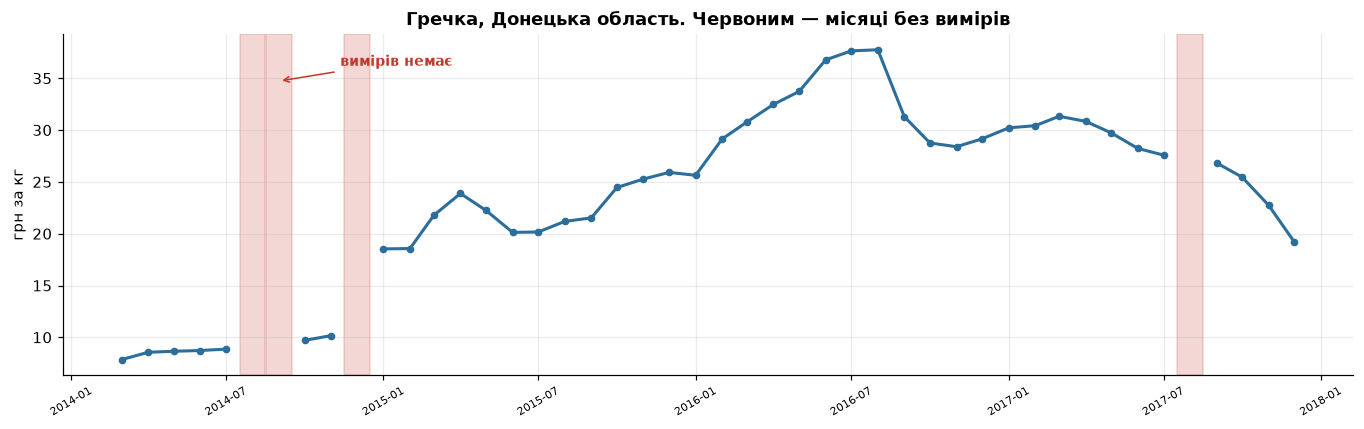

Місяці без вимірів: 08.2014, 09.2014, 12.2014, 08.2017
Усього пропусків: 4 із 46


In [23]:
donetsk = (prices[(prices['ринок'] == 'Donetska') & (prices['товар'] == 'Buckwheat grits - Retail')]
           .set_index('дата')['ціна']
           .reindex(pd.date_range('2014-03-01', '2017-12-01', freq='MS')))

fig, ax = plt.subplots(figsize=(12.5, 4))
ax.plot(donetsk.index, donetsk.values, lw=2, marker='o', ms=4, color='#2C6E9B')

# Заштриховуємо кожен проміжок, де виміру немає
gaps = donetsk[donetsk.isna()].index
for d in gaps:
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15),
               color='#C0392B', alpha=.20, zorder=0)
ax.annotate('вимірів немає', xy=(pd.Timestamp('2014-09-01'), donetsk.max()*.92),
            xytext=(40, 10), textcoords='offset points', fontsize=9, color='#C0392B',
            fontweight='bold', arrowprops=dict(arrowstyle='->', color='#C0392B'))
ax.set_title('Гречка, Донецька область. Червоним — місяці без вимірів', fontweight='bold')
ax.set_ylabel('грн за кг'); ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print('Місяці без вимірів:', ', '.join(d.strftime('%m.%Y') for d in gaps))
print('Усього пропусків:', donetsk.isna().sum(), 'із', len(donetsk))

## ❓ Питання 7

Пропуск у ряді треба чимось заповнити, інакше більшість методів просто не запрацює.
Нижче **чотири способи** заповнити серпень 2017 — місяць, якого немає в жодному ряді.
**Який спосіб обрати і чи можна взагалі заповнювати?**

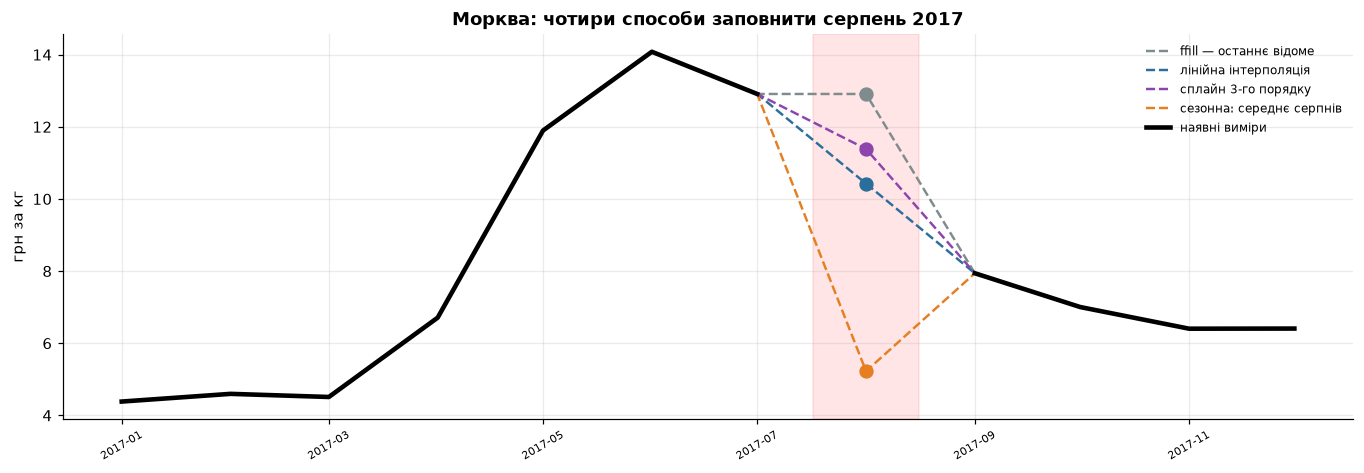

ffill — останнє відоме      12.91
лінійна інтерполяція        10.42
сплайн 3-го порядку         11.39
сезонна: середнє серпнів     5.23

Липень 2017: 12.91   Вересень 2017: 7.94


In [24]:
base = avg['Carrots - Retail']
gap = pd.Timestamp('2017-08-01')

methods = {
    'ffill — останнє відоме':     base.ffill(),
    'лінійна інтерполяція':        base.interpolate(method='linear'),
    'сплайн 3-го порядку':         base.interpolate(method='spline', order=3),
    'сезонна: середнє серпнів':    base.fillna(base[base.index.month == 8].mean()),
}

fig, ax = plt.subplots(figsize=(12.5, 4.4))
window = slice('2017-01-01', '2017-12-01')
palette = ['#7F8C8D', '#2C6E9B', '#8E44AD', '#E67E22']
for (title, s), c in zip(methods.items(), palette):
    ax.plot(s[window].index, s[window].values, lw=1.6, ls='--', color=c, label=title)
    ax.scatter([gap], [s[gap]], s=70, color=c, zorder=5)
ax.plot(base[window].index, base[window].values, lw=3, color='k', label='наявні виміри')
ax.axvspan(gap - pd.Timedelta(days=15), gap + pd.Timedelta(days=15), color='r', alpha=.10)
ax.set_title('Морква: чотири способи заповнити серпень 2017', fontweight='bold')
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, frameon=False)
ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print(pd.Series({nm: s[gap] for nm, s in methods.items()}).round(2).to_string())
print(f'\nЛипень 2017: {base[pd.Timestamp("2017-07-01")]:.2f}   '
      f'Вересень 2017: {base[pd.Timestamp("2017-09-01")]:.2f}')

<details>
<summary><b>💡 Відповідь</b></summary>

Тут відповідь залежить від того, **чому саме виміру немає**, — а не від того, який метод гарніший.

* **ffill** переносить липневе значення вперед. Для ряду з вираженою сезонністю це найгірший вибір:
  саме в серпні морква стрімко дешевшає, і ffill цю зміну просто скасовує.
* **Лінійна інтерполяція** бере середнє між липнем і вереснем. Для одиночного пропуску всередині
  гладкого ряду це розумний і чесний вибір — він не вигадує нічого понад те, що видно сусідам.
* **Сплайн** гладший, але він **довільно домальовує форму**, якої ніхто не міряв, і на краях ряду
  здатен видавати значення поза будь-якими розумними межами. Для одного пропуску — зайва складність.
* **Сезонне середнє** ігнорує рівень 2017 року: середнє всіх серпнів включає 2014-й, коли ціни були інші.
  Правильна сезонна підстановка робиться інакше — спершу знімається тренд, і лише потім додається
  сезонна поправка до локального рівня.

**Але головне питання інше — чи можна заповнювати взагалі.**

Серпень 2017 відсутній у **всіх** рядах одночасно. Це ознака того, що зникло не значення,
а **сам акт вимірювання** — не зібрали дані. Тут інтерполяція допустима: ринки працювали,
ціни існували, ми просто їх не записали.

А ось пропуски по Донецькій і Луганській областях у 2014 році заповнювати **не можна**.
Там відсутність виміру означає, що ринку в звичному вигляді не було. Заповнивши ці місяці
інтерполяцією, ми **вигадаємо ціни, яких не існувало**, і — що гірше — замаскуємо найважливішу
подію в усьому наборі даних.

> **Правило:** заповнювати пропуск можна тоді, коли величина існувала, а ми її не зафіксували.
> Коли ж пропуск означає, що самої величини не було, — його треба залишити пропуском
> і сказати про це у висновках.

</details>

## 3.3. Розкладання ряду на тренд, сезонну складову та залишок

Базова ідея: будь-який ряд можна подати як суму трьох частин.

$$y_t = T_t + S_t + R_t$$

* **$T_t$ — тренд:** повільна зміна рівня, те, куди ряд іде загалом;
* **$S_t$ — сезонна складова:** те, що повторюється з відомим періодом (тут — 12 місяців);
* **$R_t$ — залишок:** усе інше, чого ми не пояснили.

Розкладання **нічого не прогнозує**. Це інструмент розвідувального аналізу: він розділяє змішане,
щоб ми могли дивитися на частини окремо. Ми скористаємося методом **STL**
(Seasonal-Trend decomposition using Loess), бо він стійкий до викидів і не вимагає,
щоб сезонна складова була однаковою щороку.

### Теорія: адитивна й мультиплікативна моделі

Розкладання ряду на складові можливе у двох основних формах.

**Адитивна:**
$$y_t = T_t + S_t + R_t$$
Сезонні коливання мають **сталу амплітуду** незалежно від рівня ряду.

**Мультиплікативна:**
$$y_t = T_t \cdot S_t \cdot R_t$$
Амплітуда коливань **пропорційна рівню**: що дорожчий товар, то більший розмах у гривнях.

**Як обрати.** Подивіться на ряд: якщо розмах сезонних коливань зростає разом із рівнем —
модель мультиплікативна. Це той самий критерій, за яким вирішують, чи брати логарифм.

**Зручний прийом:** логарифмування перетворює мультиплікативну модель на адитивну:

$$\log y_t = \log T_t + \log S_t + \log R_t$$

Тому на практиці часто роблять так: беруть логарифм, розкладають адитивно,
а потім, якщо потрібно, повертаються експонентою. Ми побачимо на кроці 4,
до чого призводить хибний вибір між цими двома моделями.

### Як працює STL

**STL** (*Seasonal-Trend decomposition using Loess*, Cleveland et al., 1990) —
метод розкладання, побудований на локальній регресії **LOESS**.

LOESS оцінює значення у точці, підганяючи поліном низького степеня до **сусідніх точок**
із вагами, що спадають із відстанню. Ніякої глобальної формули для тренду не постулюється,
тому метод здатен описати довільно вигнутий тренд.

STL працює двома вкладеними циклами:

* **Внутрішній цикл** по черзі уточнює сезонну складову та тренд:
  ряд розділяють на $m$ підрядів (усі січні, усі лютні, …), кожен згладжують LOESS —
  це дає $S_t$; віднімають $S_t$ від ряду й згладжують залишок — це дає $T_t$; повторюють.
* **Зовнішній цикл** обчислює ваги робастності: точкам із великим залишком дають меншу вагу
  й повторюють внутрішній цикл. Саме це робить метод стійким до викидів
  (параметр `robust=True`).

**Переваги STL** над класичним розкладанням ковзними середніми: сезонна складова
може **повільно змінюватися з часом**; метод стійкий до викидів; користувач керує
гладкістю обох складових.

**Обмеження, про яке треба пам'ятати:** STL **завжди** поверне вам три складові.
Він не має способу відповісти «сезонності в цьому ряді немає» — він лише розділяє
ряд на частини згідно з періодом, який ви йому назвали. Відповідальність
за висновок про наявність сезонності лежить на аналітику, і саме для цього
потрібна кількісна міра з наступного розділу.

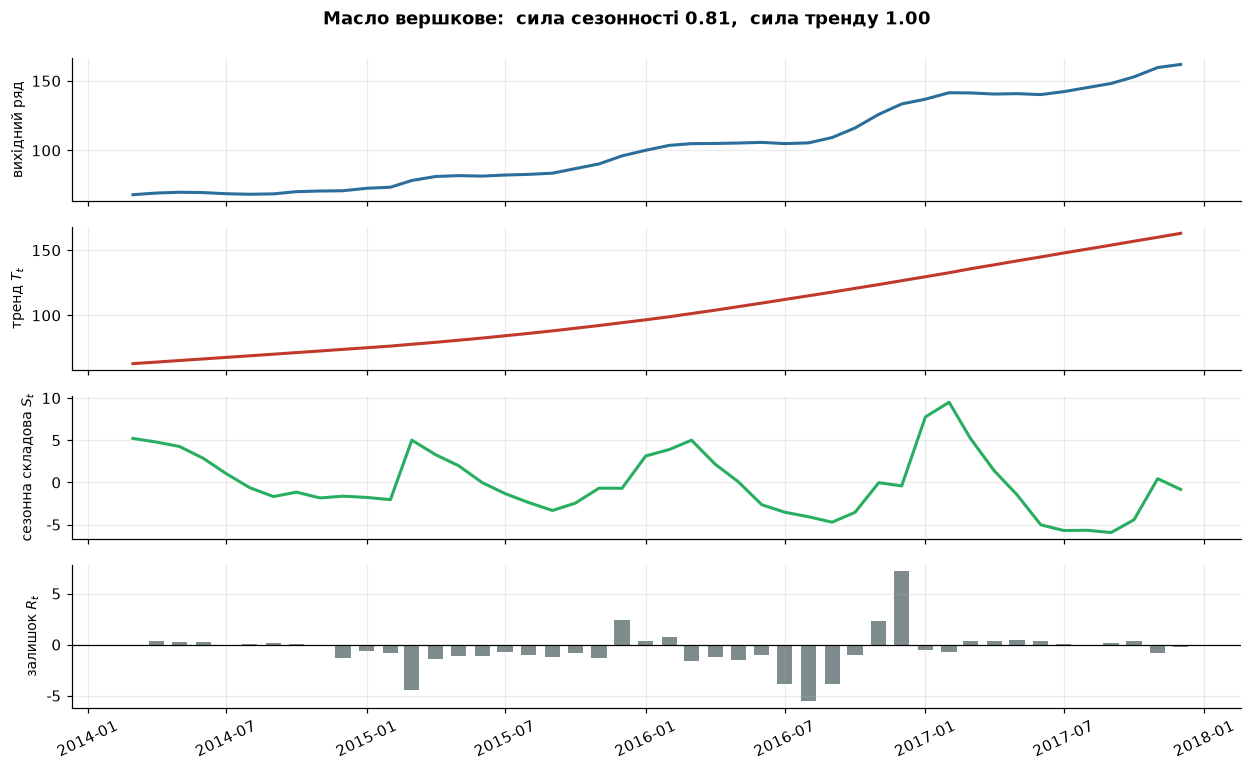

In [25]:
from statsmodels.tsa.seasonal import STL

def decompose(series, title, color='#2C6E9B'):
    s = series.interpolate().bfill().ffill()
    res = STL(s, period=12, robust=True).fit()
    fig, axes = plt.subplots(4, 1, figsize=(11.5, 7), sharex=True)
    for ax, data, label, c in zip(
            axes,
            [s, res.trend, res.seasonal, res.resid],
            ['вихідний ряд', 'тренд $T_t$', 'сезонна складова $S_t$', 'залишок $R_t$'],
            [color, '#C0392B', '#27AE60', '#7F8C8D']):
        if label.startswith('залишок'):
            ax.bar(data.index, data.values, width=20, color=c)
            ax.axhline(0, color='k', lw=.8)
        else:
            ax.plot(data.index, data.values, lw=2, color=c)
        ax.set_ylabel(label, fontsize=9)
    Fs = max(0, 1 - res.resid.var()/(res.seasonal + res.resid).var())
    Ft = max(0, 1 - res.resid.var()/(res.trend   + res.resid).var())
    fig.suptitle(f'{title}:  сила сезонності {Fs:.2f},  сила тренду {Ft:.2f}',
                 fontweight='bold', y=.995)
    axes[-1].tick_params(axis='x', labelrotation=25)
    plt.tight_layout(); plt.show()
    return Fs, Ft

decompose(avg['Butter - Retail'], 'Масло вершкове');

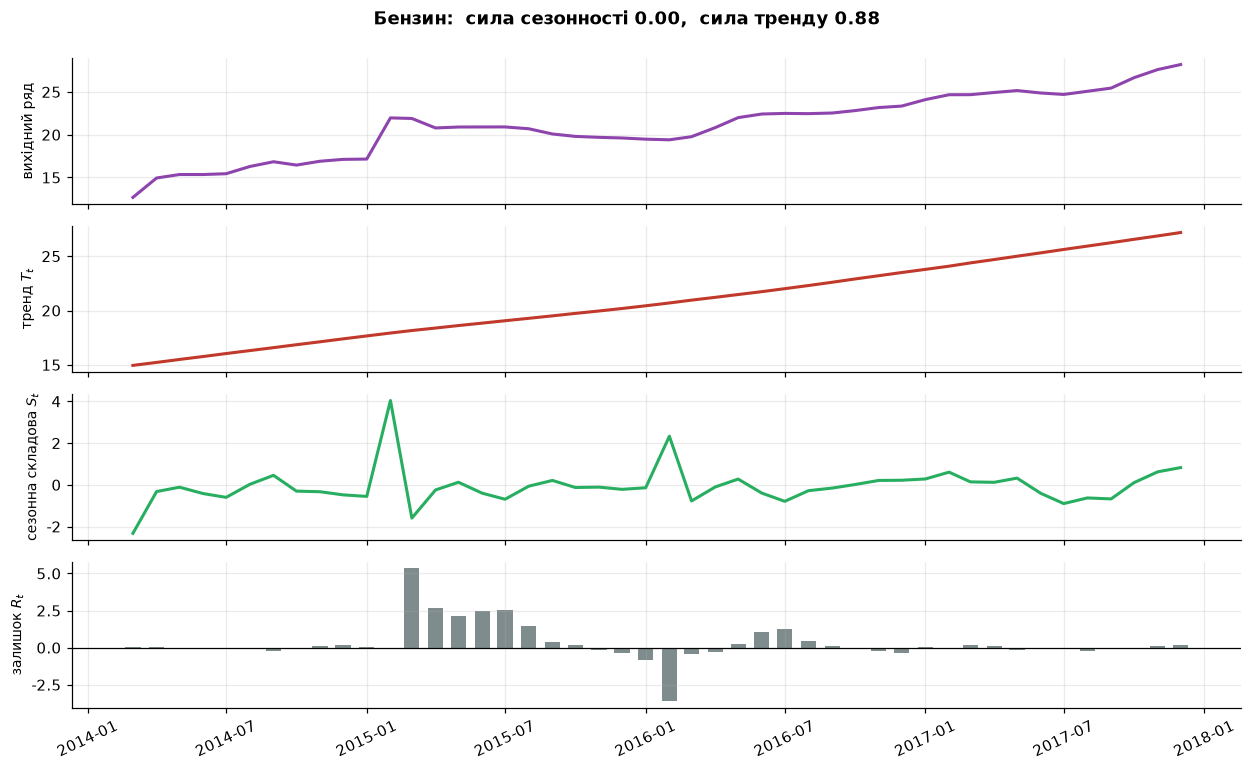

In [26]:
decompose(avg['Fuel (petrol-gasoline) - Retail'], 'Бензин', color='#8E44AD');

Два ряди з одного набору, той самий метод, ті самі 45 місяців — і принципово різний результат.

У масла сезонна складова має стабільну амплітуду близько ±5 грн і повторюється рік у рік
(влітку молока більше — масло дешевшає). У бензину сезонної складової **немає взагалі**:
те, що STL позначив як $S_t$, — це шум, який метод був зобов'язаний кудись покласти.

**Це ключова пересторога:** STL **завжди** поверне вам сезонну складову, навіть якщо сезонності немає.
Метод не вміє відповідати «сезонності тут немає» — він уміє лише розділити ряд на три частини.
Відповідальність за висновок лежить на вас.

Числова міра, якою це перевіряють, — **сила сезонності**:

$$F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

Вона показує, яку частку мінливості, що залишилась після зняття тренду, пояснює сезонність.
Значення нижче приблизно 0,3 означає, що сезонну складову виділяти не варто.

### Теорія: кількісні міри сили складових

Означення запропонували Гіндман і Атанасопулос. Ідея: складова сильна тоді, коли
її вилучення істотно зменшує дисперсію.

**Сила сезонності:**
$$F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

**Сила тренду:**
$$F_T = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(T_t + R_t)}\right)$$

Обидві змінюються від 0 до 1. Знаменник — це дисперсія ряду **після вилучення іншої складової**,
тому міри не заважають одна одній: ряд може мати одночасно сильний тренд і сильну сезонність.

**Як читати значення:**

| $F_S$ | Висновок |
|---|---|
| менше 0,3 | сезонної складової фактично немає; те, що виділив STL, — шум |
| від 0,3 до 0,5 | сезонність слабка; моделювати її варто лише за змістовних підстав |
| від 0,5 до 0,7 | сезонність виражена |
| більше 0,7 | сезонність домінує над рештою мінливості |

**Пересторога про короткі ряди.** На 45 спостереженнях ці оцінки самі мають велику
невизначеність: маючи всього три з половиною повні цикли, ми оцінюємо сезонний профіль
по трьох-чотирьох значеннях на кожен місяць. Низьке $F_S$ може означати як відсутність
сезонності, так і **нестабільність її амплітуди** — а це геть різні речі.
Саме з таким випадком ми зустрінемося на капусті.

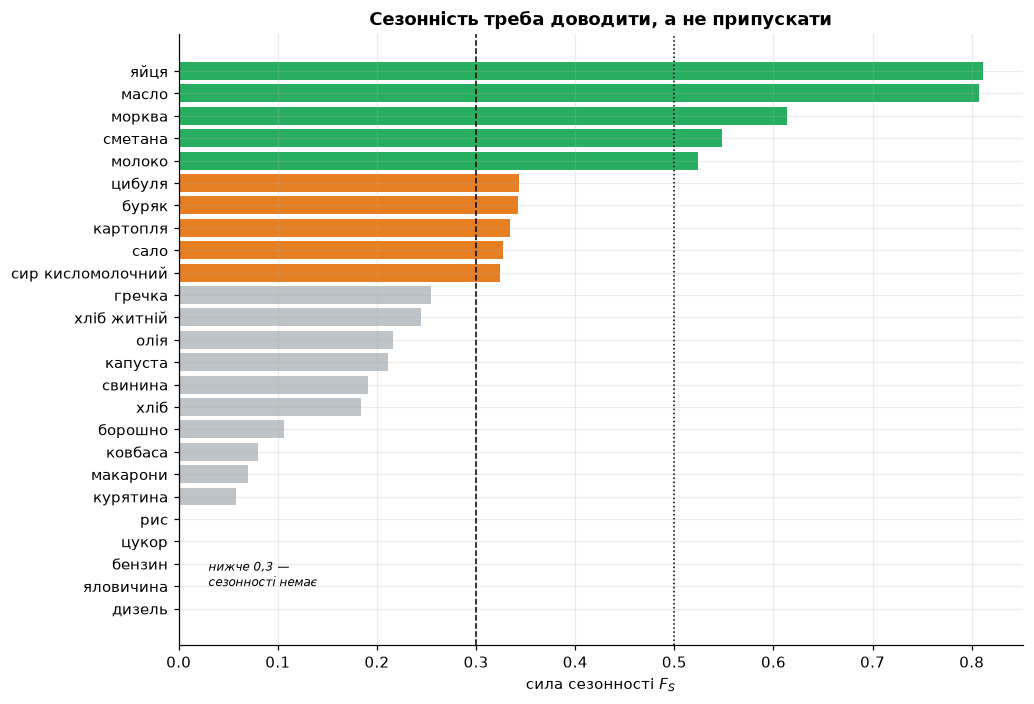

                   сезонність  тренд
товар                               
дизель                   0.00   0.58
яловичина                0.00   0.90
бензин                   0.00   0.88
цукор                    0.00   0.69
рис                      0.00   0.21
курятина                 0.06   0.90
макарони                 0.07   0.70
ковбаса                  0.08   0.97
борошно                  0.11   0.71
хліб                     0.18   0.95
свинина                  0.19   0.82
капуста                  0.21   0.25
олія                     0.22   0.93
хліб житній              0.24   0.95
гречка                   0.25   0.88
сир кисломолочний        0.32   0.99
сало                     0.33   0.71
картопля                 0.33   0.47
буряк                    0.34   0.34
цибуля                   0.34   0.05
молоко                   0.52   0.99
сметана                  0.55   0.99
морква                   0.61   0.57
масло                    0.81   1.00
яйця                     0.81   0.64


In [27]:
# Рахуємо силу сезонності для всіх 25 товарів одразу
res_all = []
for g in avg.columns:
    s = avg[g].interpolate().bfill().ffill()
    r = STL(s, period=12, robust=True).fit()
    Fs = max(0, 1 - r.resid.var()/(r.seasonal + r.resid).var())
    Ft = max(0, 1 - r.resid.var()/(r.trend + r.resid).var())
    res_all.append([UA.get(g, g), Fs, Ft])
strength = pd.DataFrame(res_all, columns=['товар', 'сезонність', 'тренд']).sort_values('сезонність')

fig, ax = plt.subplots(figsize=(9.5, 6.5))
palette = ['#27AE60' if v >= .5 else '#E67E22' if v >= .3 else '#BDC3C7' for v in strength['сезонність']]
ax.barh(strength['товар'], strength['сезонність'], color=palette)
ax.axvline(.3, color='k', ls='--', lw=1)
ax.axvline(.5, color='k', ls=':',  lw=1)
ax.set_xlabel('сила сезонності $F_S$')
ax.set_title('Сезонність треба доводити, а не припускати', fontweight='bold')
ax.annotate('нижче 0,3 —\nсезонності немає', xy=(.03, 1), fontsize=8, style='italic')
plt.tight_layout(); plt.show()

print(strength.set_index('товар').round(2).to_string())

**П'ятнадцять товарів із двадцяти п'яти** мають $F_S < 0{,}3$ — тобто більшість.
Якби ми бездумно застосували сезонну модель до всього набору, для цих п'ятнадцяти ми б моделювали шум.

І зверніть увагу на капусту: $F_S = 0{,}21$, хоча її коливання видно оком і ми весь крок 2
говорили про її річну регулярність. Розгадка чекає на кроці 4.

## Циклічна шкала: чому місяць не можна класти на звичайну вісь

Пам'ятаєте таблицю шкал на початку? Місяць — **циклічна** величина. Подивимось, що це означає на практиці.

### Теорія: як кодувати циклічну величину для моделей

Проблема циклічної шкали не обмежується графіками. Якщо подати місяць у модель
машинного навчання як число від 1 до 12, модель вважатиме, що грудень (12) і січень (1)
відстоять на одинадцять одиниць, тоді як насправді вони сусіди.

**Стандартний розв'язок — тригонометричне кодування.** Замість одного числа $m$
подаємо два:

$$x_{\sin} = \sin\!\left(\frac{2\pi m}{12}\right), \qquad
  x_{\cos} = \cos\!\left(\frac{2\pi m}{12}\right)$$

Тепер кожен місяць є точкою на одиничному колі, і евклідова відстань між груднем
і січнем така сама, як між січнем і лютим. Цей прийом працює для будь-якої циклічної
величини: години доби (період 24), дня тижня (7), дня року (365), напрямку вітру (360°).

**Альтернатива — one-hot кодування:** дванадцять двійкових стовпців. Воно не припускає
жодного порядку взагалі, тому не помиляється, але й не використовує того, що сусідні
місяці схожі, і витрачає дванадцять ознак замість двох.

У цьому зошиті ми до моделей не доходимо, але прийом варто запам'ятати:
він знадобиться вам у лабораторній роботі й у всіх подальших темах курсу.

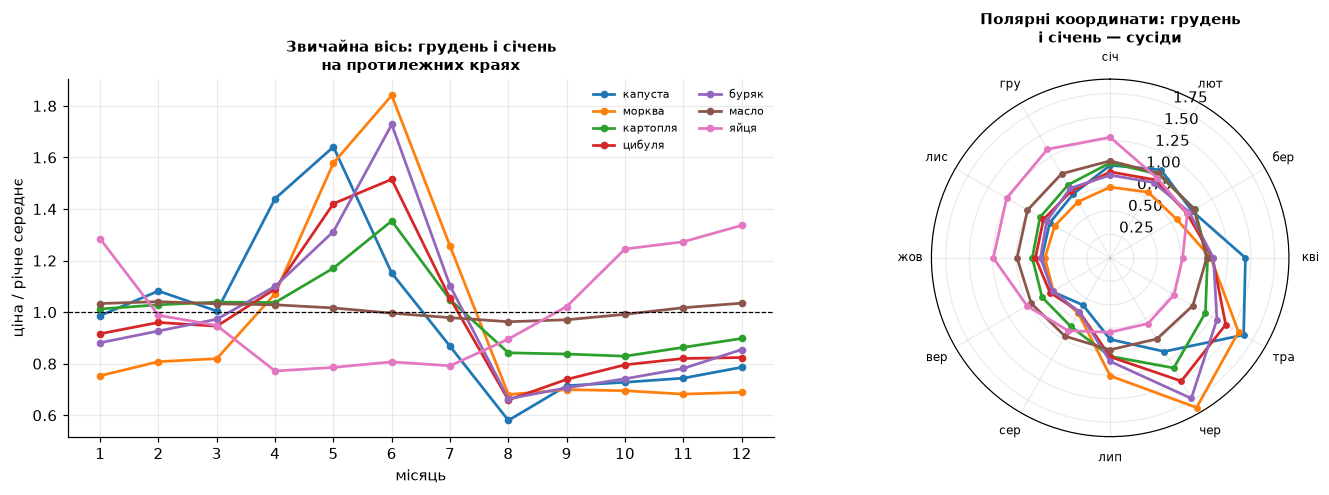

In [28]:
veg = ['Cabbage - Retail', 'Carrots - Retail', 'Potatoes - Retail',
         'Onions - Retail', 'Beetroots - Retail', 'Butter - Retail', 'Eggs - Retail']
profile = pd.DataFrame({
    UA[g]: (avg[g]/avg[g].rolling(12, center=True, min_periods=6).mean())
            .groupby(avg.index.month).mean()
    for g in veg})

fig = plt.figure(figsize=(13.5, 4.6))
ax1 = fig.add_subplot(1, 2, 1)
for c in profile.columns:
    ax1.plot(profile.index, profile[c], marker='o', ms=4, lw=1.8, label=c)
ax1.axhline(1, color='k', lw=.8, ls='--')
ax1.set_xticks(range(1, 13)); ax1.set_xlabel('місяць')
ax1.set_ylabel('ціна / річне середнє')
ax1.set_title('Звичайна вісь: грудень і січень\nна протилежних краях', fontsize=10, fontweight='bold')
ax1.legend(fontsize=7, frameon=False, ncol=2)

ax2 = fig.add_subplot(1, 2, 2, projection='polar')
angles = np.linspace(0, 2*np.pi, 12, endpoint=False)
for c in profile.columns:
    v = profile[c].values
    ax2.plot(np.append(angles, angles[0]), np.append(v, v[0]), marker='o', ms=3.5, lw=1.8)
ax2.set_xticks(angles)
ax2.set_xticklabels(['січ','лют','бер','кві','тра','чер','лип','сер','вер','жов','лис','гру'], fontsize=8)
ax2.set_theta_direction(-1); ax2.set_theta_offset(np.pi/2)
ax2.set_title('Полярні координати: грудень\nі січень — сусіди', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

Ліворуч крива овочів обривається на грудні й починається наново з січня — хоча насправді там
нічого не обривається. Праворуч та сама крива **замкнена в кільце**, і сезонний цикл видно як цикл.

Полярні координати не завжди краще: порівнювати амплітуди на них важче, бо площа зростає
як квадрат радіуса. Але для самого **факту циклічності** вони чесніші.

---
### Проміжна відповідь 3

**«Ми досі не знаємо, з чим працюємо».** Виявилося, що описові статистики сліпі до порядку;
що пропуски в наборі мають **різні причини**, і частину з них заповнювати не можна;
що сезонність є лише у десяти товарів із двадцяти п'яти, а решті її приписав би метод,
якби ми йому повірили.

Тепер ряд підготовлено, і можна спробувати те, заради чого це все робиться, — **прогноз**.

---
# Крок 4. Спроба спрогнозувати

> **Підзадача кроку.** З'ясувати, чи можемо ми передбачити майбутні ціни — і, що важливіше,
> **чи можемо ми чесно виміряти якість такого передбачення**.

Ми розклали ряд і зрозуміли його будову. Природне бажання — передбачити, що буде далі.
І тут починається найнебезпечніша частина аналізу даних, бо **прогноз завжди має вигляд успіху**:
модель завжди щось намалює, метрика завжди порахується, число завжди виглядатиме переконливо.

## 4.1. Наївний прогноз — обов'язковий базис порівняння

Перш ніж будувати будь-що складне, треба знати, **що дає найтупіший можливий метод**.
Без цього числа жодна метрика не має сенсу.

| Метод | Формула | Коли доречний |
|---|---|---|
| Наївний | $\hat y_{t+1} = y_t$ | ряд без вираженої сезонності |
| Сезонний наївний | $\hat y_{t+1} = y_{t+1-m}$ | ряд із періодом $m$ |
| Середнє | $\hat y_{t+1} = \bar y$ | ряд без тренду, коливається навколо рівня |
| Дрейф | $\hat y_{t+1} = y_t + \frac{y_t - y_1}{t-1}$ | ряд зі сталим нахилом |

### Теорія: горизонт прогнозу й відносна якість

**Горизонт** $h$ — на скільки кроків уперед робиться прогноз. Позначення $\hat y_{t+h|t}$
читається як «прогноз значення в момент $t+h$, зроблений з інформацією, доступною на момент $t$».
Вертикальна риска тут принципова: вона фіксує, **що саме модель мала право бачити**.

Розрізняють:

* **одно́кроковий прогноз** ($h=1$) — найлегший випадок, часто оманливо точний;
* **багатокроковий прогноз** ($h>1$) — помилка накопичується з кожним кроком;
* **рекурсивний** багатокроковий — прогноз підставляють як вхід для наступного кроку
  (помилки накопичуються швидко) на противагу **прямому**, коли для кожного $h$
  навчають окрему модель.

**Чому потрібен базис.** Метрика сама по собі не має інтерпретації. MAE = 2,05 грн — це добре
чи погано? Відповіді немає, поки немає з чим порівняти. Тому якість вимірюють **відносно**:

$$\text{Skill Score} = 1 - \frac{\text{помилка моделі}}{\text{помилка базису}}$$

Значення 0 означає «модель не краща за базис», 1 — «ідеальний прогноз»,
**від'ємне значення — модель гірша за базис** і не має права на існування.

**Чому базисів має бути кілька.** Кожен наївний метод сліпий до чогось свого:

* **наївний** ($\hat y_{t+1|t} = y_t$) ловить рівень, але не бачить сезонності;
* **сезонний наївний** ($\hat y_{t+1|t} = y_{t+1-m}$) ловить сезонність, але відстає
  від тренду на цілий період;
* **середнє** не бачить ані того, ані того, зате стійке до шуму;
* **дрейф** ловить сталий нахил, але не витримує зламу тренду.

На ряді з сильним трендом сезонний наївний програє навіть тоді, коли сезонність виражена,
бо він бере значення річної давнини. Саме це ви побачите на наступному графіку.
Порівнювати модель треба **з найкращим** із базисів, а не з найзручнішим.

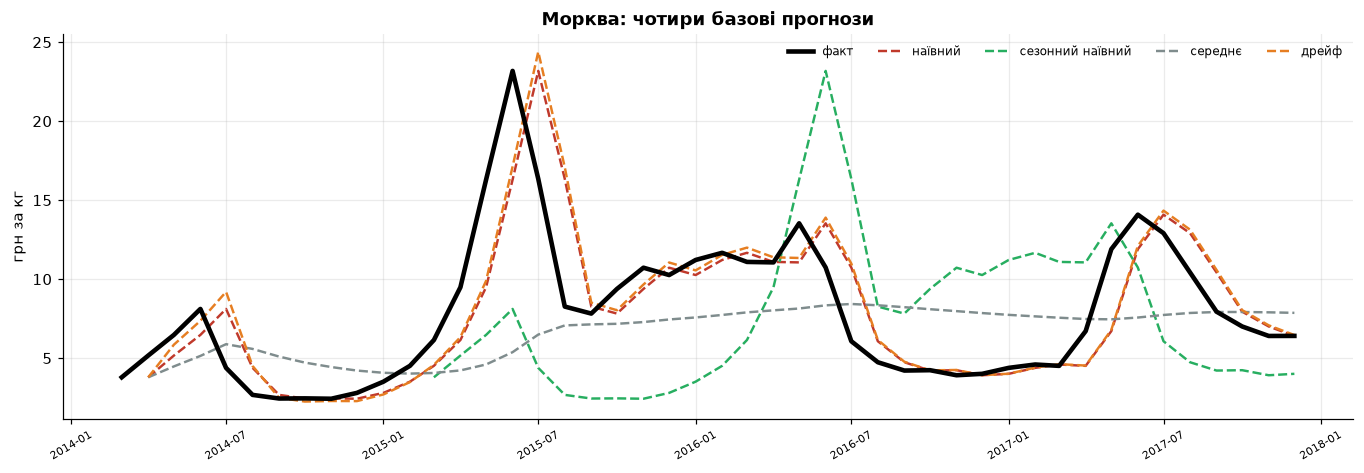

,MAE,RMSE,MAPE
наївний,2.05,3.04,20.50
дрейф,2.09,3.13,21.20
середнє,3.92,5.16,44.69
сезонний наївний,5.97,6.76,75.78


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    m = ~(np.isnan(actual) | np.isnan(pred))
    actual, pred = actual[m], pred[m]
    return dict(MAE  = mean_absolute_error(actual, pred),
                RMSE = np.sqrt(mean_squared_error(actual, pred)),
                MAPE = np.mean(np.abs((actual - pred)/actual))*100)

series = avg['Carrots - Retail'].interpolate()
m = 12
baselines = {
    'наївний':          series.shift(1),
    'сезонний наївний': series.shift(m),
    'середнє':          series.expanding().mean().shift(1),
    'дрейф':            series.shift(1) + (series.shift(1) - series.iloc[0])/np.arange(len(series)).clip(1),
}

fig, ax = plt.subplots(figsize=(12.5, 4.4))
ax.plot(series.index, series.values, lw=3, color='k', label='факт', zorder=5)
for (nm, p), c in zip(baselines.items(), ['#C0392B', '#27AE60', '#7F8C8D', '#E67E22']):
    ax.plot(p.index, p.values, lw=1.6, ls='--', color=c, label=nm)
ax.set_title('Морква: чотири базові прогнози', fontweight='bold')
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, frameon=False, ncol=5)
ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

tbl = pd.DataFrame({nm: metrics(series[m:], p[m:]) for nm, p in baselines.items()}).T.round(2)
display(tbl.sort_values('MAE'))

Результат вартий уваги: **виграє найпростіший наївний прогноз**, а сезонний наївний — найгірший
із чотирьох, дарма що морква має виражену річну регулярність.

Причина в тому, що сезонний наївний бере значення **річної давнини**, а за рік ціни встигли
помітно зрости. Він правильно вгадує форму коливання і грубо промахується по рівню.
Наївний прогноз, навпаки, форму не вгадує зовсім, зате завжди стартує з правильного рівня —
і на ряді з сильним трендом цього виявляється достатньо, щоб перемогти.

> **Висновок, який варто запам'ятати:** базисів має бути кілька. Один наївний прогноз —
> це ще не базис, бо кожен із них сліпий до чогось свого. Модель має перевершити **найкращий** із них.

> Професійне правило: у звіті про прогноз **завжди** має бути рядок із наївним базисом.
> Звіт без нього неможливо оцінити — метрика сама по собі не означає нічого.

## 4.2. Найпоширеніша помилка перевірки прогнозу

## ❓ Питання 8

Ми хочемо оцінити, наскільки добре модель прогнозує. Звичний спосіб з машинного навчання —
випадково поділити дані на навчальну й тестову частини у співвідношенні 75/25.

**Що станеться, якщо зробити так із часовим рядом?**

### Теорія: витік даних і чому час несиметричний

**Витік даних** (*data leakage*) — ситуація, коли під час навчання модель отримує
інформацію, якої не буде в момент реального застосування. Наслідок завжди однаковий:
оцінка якості виявляється **надто оптимістичною**, і модель не відтворює її на практиці.

**Різновиди, з якими стикаються найчастіше:**

| Різновид | Суть | Приклад |
|---|---|---|
| **Часовий витік** | у навчальну вибірку потрапило майбутнє | випадковий поділ часового ряду |
| **Цільовий витік** | ознака є наслідком цільової величини | «дата виписки» при прогнозі одужання |
| **Витік при обробці** | нормування або відбір ознак зроблено до поділу | `StandardScaler` на всьому наборі |
| **Груповий витік** | записи одного об'єкта потрапили і в навчання, і в тест | кілька вимірів того самого пацієнта |

Другий різновид ми детально розбирали в лекції 3 на ковідному наборі.
Сьогодні нас цікавить перший.

**Чому випадковий поділ руйнує часовий ряд.** Формально задача прогнозування —
оцінити $\mathbb{E}[Y_{t+h} \mid \mathcal{F}_t]$, де $\mathcal{F}_t$ — уся інформація,
доступна **до моменту $t$ включно**. Випадковий поділ дає моделі точки
з обох боків від прогнозованої, тобто підмінює умову на $\mathcal{F}_t \cup \{y_{t+1}, y_{t+2}, \dots\}$.

Це вже не прогнозування, а **інтерполяція** — задача набагато легша.
Для гладкого ряду знати сусідів зліва й справа означає знати відповідь майже точно.

**Практичне правило без винятків:** у будь-якій задачі, де є час, поділ на навчальну
й тестову частини робиться **тільки за часом**. `train_test_split(shuffle=True)`
на часовому ряді — це помилка, а не спрощення.

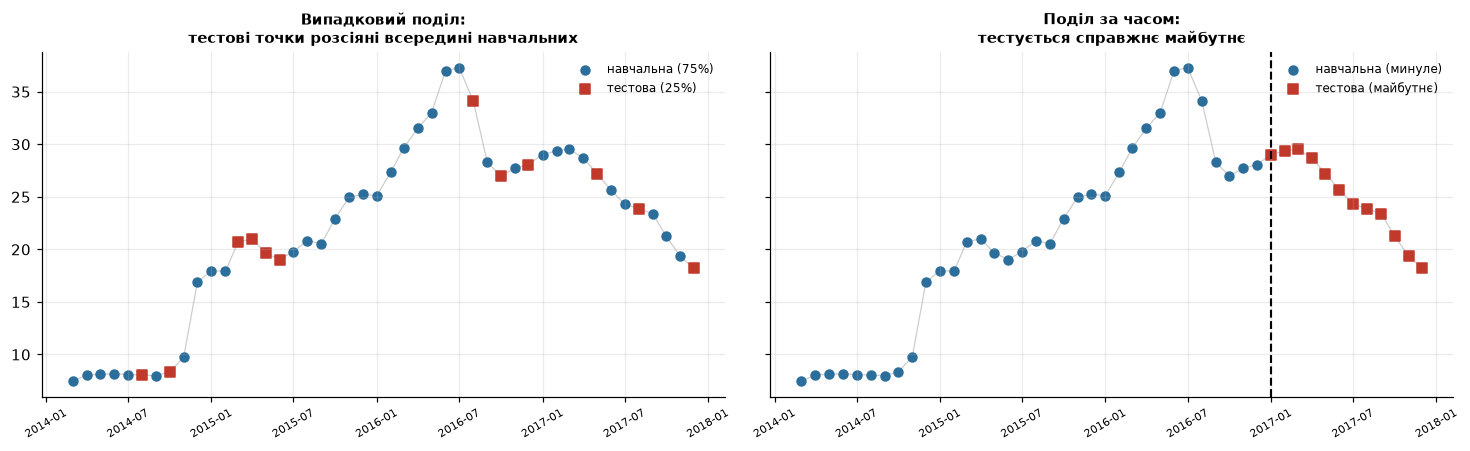

In [30]:
from sklearn.linear_model import LinearRegression

s = avg['Buckwheat grits - Retail'].interpolate()
X = np.arange(len(s)).reshape(-1, 1); y = s.values
rng = np.random.default_rng(0)
idx = rng.permutation(len(s)); tr, te = np.sort(idx[:34]), np.sort(idx[34:])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2), sharey=True)

axes[0].scatter(s.index[tr], y[tr], s=34, color='#2C6E9B', label='навчальна (75%)')
axes[0].scatter(s.index[te], y[te], s=48, color='#C0392B', marker='s', label='тестова (25%)')
axes[0].plot(s.index, y, lw=.8, color='#ccc', zorder=0)
axes[0].set_title('Випадковий поділ:\nтестові точки розсіяні всередині навчальних',
                  fontweight='bold', fontsize=10)
axes[0].legend(fontsize=8, frameon=False)

bound = 34
axes[1].scatter(s.index[:bound], y[:bound], s=34, color='#2C6E9B', label='навчальна (минуле)')
axes[1].scatter(s.index[bound:], y[bound:], s=48, color='#C0392B', marker='s', label='тестова (майбутнє)')
axes[1].axvline(s.index[bound], color='k', ls='--', lw=1.4)
axes[1].plot(s.index, y, lw=.8, color='#ccc', zorder=0)
axes[1].set_title('Поділ за часом:\nтестується справжнє майбутнє', fontweight='bold', fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
for ax in axes: ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

Подивіться на ліве поле: кожна червона тестова точка **оточена синіми навчальними з обох боків**.
Модель, яка знає ціну в липні та вересні, вгадає серпень майже точно — але це **не прогноз**,
це інтерполяція. У реальності майбутніх точок праворуч від прогнозованої не існує.

Випадковий поділ дозволяє моделі **зазирнути в майбутнє** й тому систематично **занижує помилку**.
Це окремий випадок витоку даних (data leakage), з яким ми зустрічалися в третій лекції.

Нижче — скільки саме коштує ця помилка.

</details>

### Теорія: ретроспективна перевірка з рухомим початком

Метод має кілька назв: *rolling-origin evaluation*, *walk-forward validation*,
*time series cross-validation*. Схема така:

1. Обираємо мінімальний розмір навчальної частини $k_0$ і горизонт $h$.
2. Навчаємо модель на $y_1,\dots,y_{k}$, прогнозуємо $y_{k+1},\dots,y_{k+h}$,
   рахуємо помилку — це один **фолд**.
3. Збільшуємо $k$ на крок $s$ і повторюємо, поки вистачає даних.
4. Підсумкова оцінка — середнє помилок по всіх фолдах.

**Два різновиди вікна:**

* **Розширюване вікно** (*expanding window*): навчальна частина щоразу довша,
  $y_1,\dots,y_k$. Доречне, коли вважаємо, що старі дані досі інформативні.
* **Ковзне вікно** (*sliding window*): навчальна частина сталої довжини,
  $y_{k-w+1},\dots,y_k$. Доречне, коли процес змінюється з часом
  і давні дані описують уже іншу систему — наприклад, після зміни режиму.

У цьому зошиті використано розширюване вікно з $k_0 = 24$, $h = 3$, $s = 3$.

**Скільки виходить фолдів:**
$$\text{кількість фолдів} = \left\lfloor \frac{n - k_0 - h + 1}{s} \right\rfloor + 1$$

**Ціна методу.** Модель навчається стільки разів, скільки є фолдів — для важких моделей
це дорого. Але альтернативи немає: будь-яка оцінка, отримана з випадкового поділу,
є оцінкою іншої, легшої задачі.

**Ще одна перевага, яку часто не помічають.** Рухомий початок дає не одне число,
а **розподіл помилок по фолдах**. Якщо помилка стабільна — модель надійна.
Якщо на одному фолді вона різко гірша — там сталося щось, варте окремого розгляду;
дуже часто це саме точка зміни режиму.

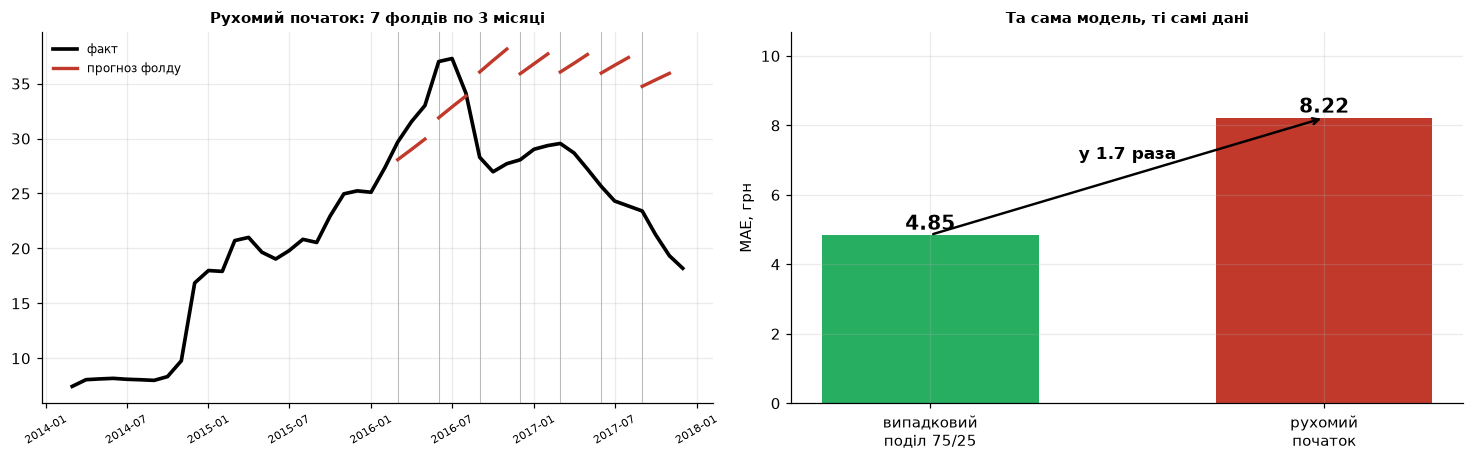

Випадковий поділ:  MAE = 4.85 грн
Рухомий початок:   MAE = 8.22 грн
Випадковий поділ применшує помилку у 1.70 раза.


In [31]:
# А. Випадковий поділ, усереднений по 200 розбиттях
mae_rand = []
for _ in range(200):
    i = rng.permutation(len(s)); a, b = i[:34], i[34:]
    model = LinearRegression().fit(X[a], y[a])
    mae_rand.append(mean_absolute_error(y[b], model.predict(X[b])))

# Б. Ретроспективна перевірка з рухомим початком
mae_roll, folds = [], []
for start in range(24, len(s)-2, 3):
    model = LinearRegression().fit(X[:start], y[:start])
    fc = model.predict(X[start:start+3])
    mae_roll.append(mean_absolute_error(y[start:start+3], fc))
    folds.append((start, fc))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
axes[0].plot(s.index, y, lw=2.4, color='k', label='факт')
for i, (start, fc) in enumerate(folds):
    axes[0].plot(s.index[start:start+3], fc, lw=2.2, color='#C0392B',
                 label='прогноз фолду' if i == 0 else None)
    axes[0].axvline(s.index[start], color='#bbb', lw=.7, zorder=0)
axes[0].set_title(f'Рухомий початок: {len(mae_roll)} фолдів по 3 місяці', fontweight='bold', fontsize=10)
axes[0].legend(fontsize=8, frameon=False); axes[0].tick_params(axis='x', labelrotation=30, labelsize=7)

axes[1].bar(['випадковий\nподіл 75/25', 'рухомий\nпочаток'],
            [np.mean(mae_rand), np.mean(mae_roll)], color=['#27AE60', '#C0392B'], width=.55)
for i, v in enumerate([np.mean(mae_rand), np.mean(mae_roll)]):
    axes[1].text(i, v + .15, f'{v:.2f}', ha='center', fontweight='bold', fontsize=13)
axes[1].set_ylabel('MAE, грн'); axes[1].set_ylim(0, max(np.mean(mae_roll)*1.3, 1))
axes[1].set_title('Та сама модель, ті самі дані', fontweight='bold', fontsize=10)
axes[1].annotate('', xy=(1, np.mean(mae_roll)), xytext=(0, np.mean(mae_rand)),
                 arrowprops=dict(arrowstyle='->', lw=1.6, color='k'))
axes[1].text(.5, (np.mean(mae_rand)+np.mean(mae_roll))/2 + .5,
             f'у {np.mean(mae_roll)/np.mean(mae_rand):.1f} раза', ha='center',
             fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Випадковий поділ:  MAE = {np.mean(mae_rand):.2f} грн')
print(f'Рухомий початок:   MAE = {np.mean(mae_roll):.2f} грн')
print(f'Випадковий поділ применшує помилку у {np.mean(mae_roll)/np.mean(mae_rand):.2f} раза.')

Одна й та сама модель, один і той самий ряд — і оцінка якості відрізняється майже вдвічі.
Якби ми звітували першим числом, замовник отримав би модель, удвічі гіршу за обіцяну.

**Ретроспективна перевірка з рухомим початком** (rolling-origin, walk-forward) влаштована просто:
навчаємось на перших $k$ спостереженнях, прогнозуємо наступні $h$, зсуваємо початок,
повторюємо. Кожен прогноз робиться **тільки з минулого**, як і в реальній роботі.
Підсумкова метрика — середнє по всіх фолдах.

## 4.3. MAE, RMSE, MAPE та їхні пастки

$$\text{MAE}=\frac1n\sum|y_t-\hat y_t| \qquad
\text{RMSE}=\sqrt{\frac1n\sum(y_t-\hat y_t)^2} \qquad
\text{MAPE}=\frac{100}{n}\sum\left|\frac{y_t-\hat y_t}{y_t}\right|$$

## ❓ Питання 9

Нижче наївний прогноз для двох товарів. **Який із них прогнозується краще?**

### Теорія: повний набір метрик

Нехай $e_t = y_t - \hat y_t$ — помилка прогнозу.

**Метрики в одиницях величини** (*scale-dependent*) — не порівнюються між рядами
різного масштабу:

$$\text{MAE} = \frac1n\sum_{t=1}^{n}|e_t| \qquad
  \text{RMSE} = \sqrt{\frac1n\sum_{t=1}^{n}e_t^2} \qquad
  \text{ME} = \frac1n\sum_{t=1}^{n}e_t$$

**ME** (середня помилка) сама по собі нічого не каже про точність, зате показує **зміщення**:
якщо вона істотно відрізняється від нуля, модель систематично завищує або занижує прогноз.
Її варто дивитися завжди — це одне число, яке ловить цілий клас проблем.

**Співвідношення MAE та RMSE.** Завжди $\text{RMSE} \ge \text{MAE}$, причому рівність
досягається лише тоді, коли всі помилки однакові за модулем. Що більший розрив,
то більш нерівномірні помилки: кілька грубих промахів серед багатьох точних.
Відношення $\text{RMSE}/\text{MAE}$ — безкоштовний діагностичний показник.

**Відсоткові метрики** (*scale-independent*):

$$\text{MAPE} = \frac{100}{n}\sum \left|\frac{e_t}{y_t}\right| \qquad
  \text{sMAPE} = \frac{100}{n}\sum \frac{|e_t|}{(|y_t|+|\hat y_t|)/2}$$

**sMAPE** («симетрична») створювалася, щоб виправити несиметричність MAPE,
але має власні вади: вона не є симетричною насправді й поводиться непередбачувано
поблизу нуля. Користуватися нею не рекомендують.

**Масштабована метрика — MASE** (Hyndman & Koehler, 2006), найкращий сучасний вибір:

$$\text{MASE} = \frac{\text{MAE моделі}}{\text{MAE наївного прогнозу на навчальній вибірці}}
= \frac{\frac1n\sum_{t}|e_t|}{\frac{1}{n-m}\sum_{t=m+1}^{n}|y_t - y_{t-m}|}$$

Її переваги: вона **безрозмірна**, тому порівнюється між рядами; вона **визначена**
навіть коли $y_t = 0$; і вона має пряму інтерпретацію — **$\text{MASE} < 1$ означає,
що модель краща за наївний прогноз**, $\text{MASE} > 1$ — гірша.
Фактично це вже згаданий skill score у зручній формі.

**Як обирати:**

| Ситуація | Метрика |
|---|---|
| усі помилки рівноцінні, один ряд | MAE |
| одна велика помилка гірша за багато дрібних | RMSE |
| треба порівняти якість між рядами різного масштабу | MASE |
| замовник мислить у відсотках і значення далекі від нуля | MAPE, з переліком її вад |
| перевірка на систематичне зміщення | ME |

**І про пастку інструментів.** Одна й та сама абревіатура в різних бібліотеках може означати
різні величини. Найвідоміший випадок ви зустрінете в лабораторній роботі:
в **Orange** метрика `MAE` означає *median* absolute error — **медіану** абсолютних похибок,
тоді як у **scikit-learn** `MAE` — це *mean* absolute error, **середнє**.
Медіана стійка до викидів, тому на ряді з кількома грубими промахами вона дасть
помітно менше число. Перш ніж порівнювати числа з двох інструментів, завжди звіряйте
означення, а не назву.

,середня ціна,MAE,RMSE,MAPE
капуста,6.29,1.64,2.34,27.09
яловичина,82.75,1.51,1.90,1.85


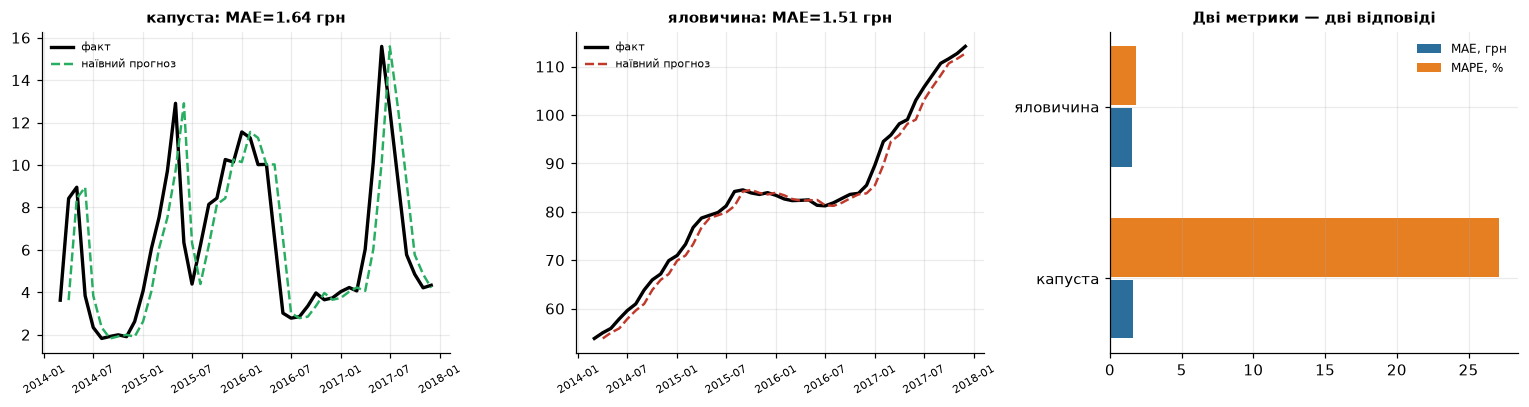

In [32]:
pair2 = {}
for g in ['Cabbage - Retail', 'Meat (beef) - Retail']:
    x = avg[g].interpolate()
    pair2[UA[g]] = metrics(x[1:], x.shift(1)[1:]) | {'середня ціна': x.mean()}
cmp_metrics = pd.DataFrame(pair2).T[['середня ціна', 'MAE', 'RMSE', 'MAPE']].round(2)
display(cmp_metrics)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, g, c in zip(axes[:2], ['Cabbage - Retail', 'Meat (beef) - Retail'], ['#27AE60', '#C0392B']):
    x = avg[g].interpolate()
    ax.plot(x.index, x.values, lw=2.2, color='k', label='факт')
    ax.plot(x.index, x.shift(1).values, lw=1.6, ls='--', color=c, label='наївний прогноз')
    ax.set_title(f'{UA[g]}: MAE={metrics(x[1:], x.shift(1)[1:])["MAE"]:.2f} грн',
                 fontweight='bold', fontsize=10)
    ax.legend(fontsize=7, frameon=False); ax.tick_params(axis='x', labelrotation=30, labelsize=7)

y = np.arange(2)
axes[2].barh(y-.18, cmp_metrics['MAE'],  height=.34, color='#2C6E9B', label='MAE, грн')
axes[2].barh(y+.18, cmp_metrics['MAPE'], height=.34, color='#E67E22', label='MAPE, %')
axes[2].set_yticks(y); axes[2].set_yticklabels(cmp_metrics.index)
axes[2].legend(fontsize=8, frameon=False)
axes[2].set_title('Дві метрики — дві відповіді', fontweight='bold', fontsize=10)
plt.tight_layout(); plt.show()

<details>
<summary><b>💡 Відповідь</b></summary>

**За MAE вони майже однакові** (1,64 грн проти 1,51 грн), тобто яловичина ніби навіть трохи краща.
**За MAPE яловичина краща у п'ятнадцять разів** (1,8 % проти 27,1 %).

Обидві метрики пораховані правильно. Суперечності немає — вони відповідають на різні питання.

* **MAE** — це помилка **в одиницях величини**. Питання: «на скільки гривень я помиляюсь?»
  Помилятися на 1,6 грн, торгуючи капустою по 6 грн, і на 1,5 грн, торгуючи яловичиною по 83 грн, —
  зовсім різні ситуації, хоч число майже те саме. **MAE не можна порівнювати між рядами різного масштабу.**
* **RMSE** — теж в одиницях величини, але **карає великі помилки сильніше** (квадрат).
  Беріть RMSE, коли одна груба помилка гірша за десять дрібних; MAE — коли всі помилки рівноцінні.
* **MAPE** — відносна, **безрозмірна**, тому її можна порівнювати між рядами. Ціною трьох вад:

**Пастки MAPE:**

1. **Ділення на факт.** Якщо $y_t$ близьке до нуля, MAPE вибухає до сотень відсотків.
   Для попиту, який іноді дорівнює нулю, MAPE непридатна взагалі.
2. **Несиметричність.** Завищення прогнозу вдвічі дає 100 %, заниження вдвічі — лише 50 %.
   Модель, яку оптимізують за MAPE, **систематично занижує прогноз**.
3. **Відсотки від різних баз не можна усереднювати** наївно, як ми щойно й зробили.

І окремо — **пастка, специфічна для інструментів**: в Orange, який чекає на вас у лабораторній роботі,
метрика, підписана `MAE`, означає **median absolute error**, тобто медіану абсолютних похибок,
тоді як у `scikit-learn` `MAE` — це **mean absolute error**, середнє. Однакова абревіатура,
різні величини. Саме тому в лабораторній ви будете зобов'язані **пояснити розбіжність**
між числами з двох середовищ, а не просто їх показати.

</details>

,прогноз,"помилка, од.","MAPE, %"
0,50,-50.0,50.0
1,75,-25.0,25.0
2,100,0.0,0.0
3,125,25.0,25.0
4,150,50.0,50.0
5,200,100.0,100.0


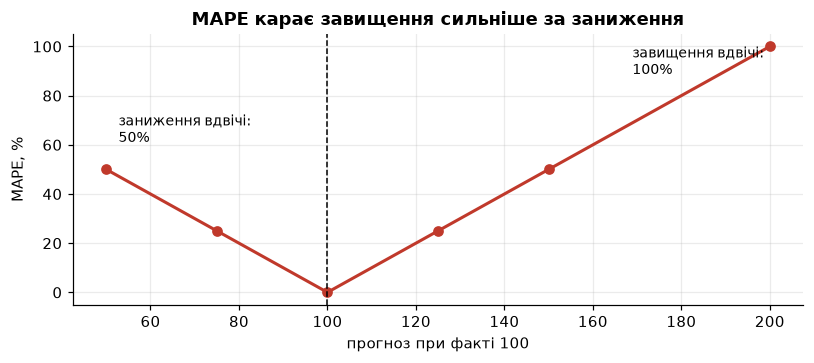

In [33]:
# Несиметричність MAPE: показ на простому прикладі
actual = 100.0
variants = pd.DataFrame({
    'прогноз': [50, 75, 100, 125, 150, 200],
})
variants['помилка, од.'] = variants['прогноз'] - actual
variants['MAPE, %'] = (variants['прогноз'] - actual).abs()/actual*100
display(variants)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(variants['прогноз'], variants['MAPE, %'], marker='o', lw=2, color='#C0392B')
ax.axvline(actual, color='k', ls='--', lw=1)
ax.annotate('заниження вдвічі:\n50%', xy=(50, 50), xytext=(8, 18),
            textcoords='offset points', fontsize=9)
ax.annotate('завищення вдвічі:\n100%', xy=(200, 100), xytext=(-90, -18),
            textcoords='offset points', fontsize=9)
ax.set_xlabel('прогноз при факті 100'); ax.set_ylabel('MAPE, %')
ax.set_title('MAPE карає завищення сильніше за заниження', fontweight='bold')
plt.tight_layout(); plt.show()

## 4.4. Експоненційне згладжування

Наївний прогноз бере лише останнє значення. Середнє бере всі з однаковою вагою.
Експоненційне згладжування — компроміс: усі значення враховано, але **вага спадає
експоненційно в минуле**.

$$\hat y_{t+1} = \alpha y_t + (1-\alpha)\hat y_t, \qquad 0<\alpha<1$$

Метод Голта-Вінтерса розширює цю ідею на три складові — рівень, тренд і сезонність —
і тому природно лягає на розкладання з кроку 3.

### Теорія: родина методів експоненційного згладжування

**Просте експоненційне згладжування (SES)** — для ряду без тренду й сезонності:

$$\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}, \qquad \hat y_{t+h|t} = \ell_t$$

Розкривши рекурсію, дістанемо зважену суму всієї історії з вагами, що спадають
геометрично: $\alpha,\ \alpha(1-\alpha),\ \alpha(1-\alpha)^2,\dots$
Параметр $\alpha \in (0,1)$ керує «пам'яттю»: що він більший, то швидше метод забуває минуле.

**Метод Голта** додає складову тренду $b_t$:

$$\ell_t = \alpha y_t + (1-\alpha)(\ell_{t-1}+b_{t-1})$$

$$b_t = \beta^*(\ell_t-\ell_{t-1}) + (1-\beta^*)b_{t-1}$$

$$\hat y_{t+h|t} = \ell_t + h\,b_t$$

**Метод Голта-Вінтерса** додає сезонну складову $s_t$ з періодом $m$.
Адитивна форма:

$$\ell_t = \alpha(y_t - s_{t-m}) + (1-\alpha)(\ell_{t-1}+b_{t-1})$$

$$b_t = \beta^*(\ell_t-\ell_{t-1}) + (1-\beta^*)b_{t-1}$$

$$s_t = \gamma(y_t-\ell_{t-1}-b_{t-1}) + (1-\gamma)s_{t-m}$$

$$\hat y_{t+h|t} = \ell_t + h\,b_t + s_{t+h-m(\lfloor (h-1)/m\rfloor +1)}$$

Мультиплікативна форма відрізняється тим, що сезонна складова **множиться**,
а не додається:
$$\hat y_{t+h|t} = (\ell_t + h\,b_t)\cdot s_{t+h-m(\dots)}$$

**Таксономія ETS.** Усі варіанти систематизують трилітерним кодом **(E, T, S)**:
помилка, тренд, сезонність, кожна — `N` (немає), `A` (адитивна), `M` (мультиплікативна),
а тренд ще й `Ad` (згасаючий). Наприклад:

* `ETS(A,N,N)` — просте експоненційне згладжування;
* `ETS(A,A,N)` — метод Голта;
* `ETS(A,A,A)` — Голт-Вінтерс адитивний (саме його ми зараз використаємо);
* `ETS(M,A,M)` — мультиплікативна сезонність, типова для економічних рядів.

**Найважливіше, що треба винести.** Кожна літера коду — це **твердження про природу даних**,
а не налаштування за смаком:

* `A` проти `M` у сезонності: «розмах коливань сталий у гривнях» проти «розмах пропорційний рівню»;
* `A` проти `Ad` у тренді: «підйом триватиме вічно» проти «підйом поступово згасатиме»;
* `N` у тренді: «тренду немає взагалі».

Найнебезпечніший із цих виборів — **незгасаючий тренд `A`**. Він екстраполює приріст лінійно
й без обмежень, тому на ряді, який фізично не може вийти за певні межі, здатен видати
прогноз у кілька разів вищий за все, що коли-небудь спостерігалося. Саме тому
для реальних задач майже завжди беруть `Ad` — згасаючий тренд із параметром $\phi < 1$:

$$\hat y_{t+h|t} = \ell_t + (\phi + \phi^2 + \dots + \phi^h)\,b_t$$

Сума в дужках обмежена значенням $\phi/(1-\phi)$, тож прогноз виходить на плато
замість того, щоб іти в нескінченність. Ви побачите обидві поведінки за дві клітинки.

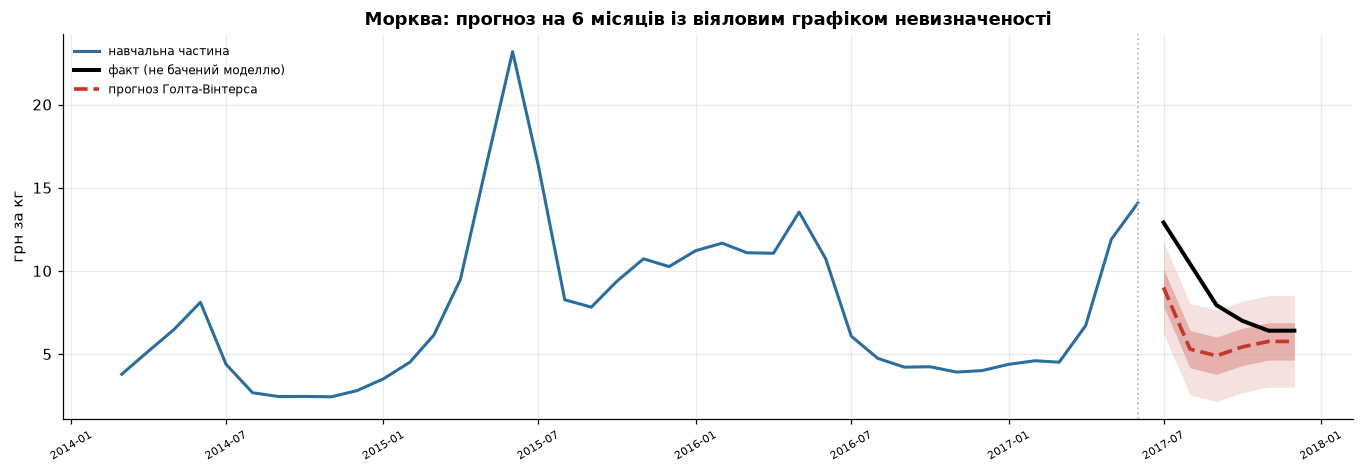

,MAE,RMSE,MAPE
Голт-Вінтерс,2.49,3.00,26.75
сезонний наївний,3.98,4.33,45.04
наївний,5.57,6.06,77.03


Складна модель має право на існування лише тому, що перевершила обидва базиси.


In [34]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

carrots_s = avg['Carrots - Retail'].interpolate()
train, test = carrots_s[:-6], carrots_s[-6:]

model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit()
fc = model.forecast(6)
sd = np.std(model.resid)

fig, ax = plt.subplots(figsize=(12.5, 4.4))
ax.plot(train.index, train.values, lw=2, color='#2C6E9B', label='навчальна частина')
ax.plot(test.index, test.values, lw=2.6, color='k', label='факт (не бачений моделлю)')
ax.plot(fc.index, fc.values, lw=2.4, ls='--', color='#C0392B', label='прогноз Голта-Вінтерса')
# Віяловий графік: інтервали 50% і 90%
for z, a in [(0.67, .28), (1.64, .15)]:
    ax.fill_between(fc.index, fc - z*sd, fc + z*sd, color='#C0392B', alpha=a, lw=0)
ax.axvline(train.index[-1], color='#bbb', lw=1.2, ls=':')
ax.set_title('Морква: прогноз на 6 місяців із віяловим графіком невизначеності', fontweight='bold')
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, frameon=False)
ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

cmp_hw = pd.DataFrame({
    'Голт-Вінтерс':     metrics(test, fc),
    'сезонний наївний': metrics(test, carrots_s.shift(12)[-6:]),
    'наївний':          metrics(test, pd.Series(train.iloc[-1], index=test.index)),
}).T.round(2)
display(cmp_hw)
print('Складна модель має право на існування лише тому, що перевершила обидва базиси.')

**Віяловий графік** — обов'язковий елемент чесного прогнозу. Лінія прогнозу без смуги невизначеності
створює враження точності, якої не існує. Що далі в майбутнє — то ширшою має бути смуга.

### А тепер та сама модель, той самий код — на капусті

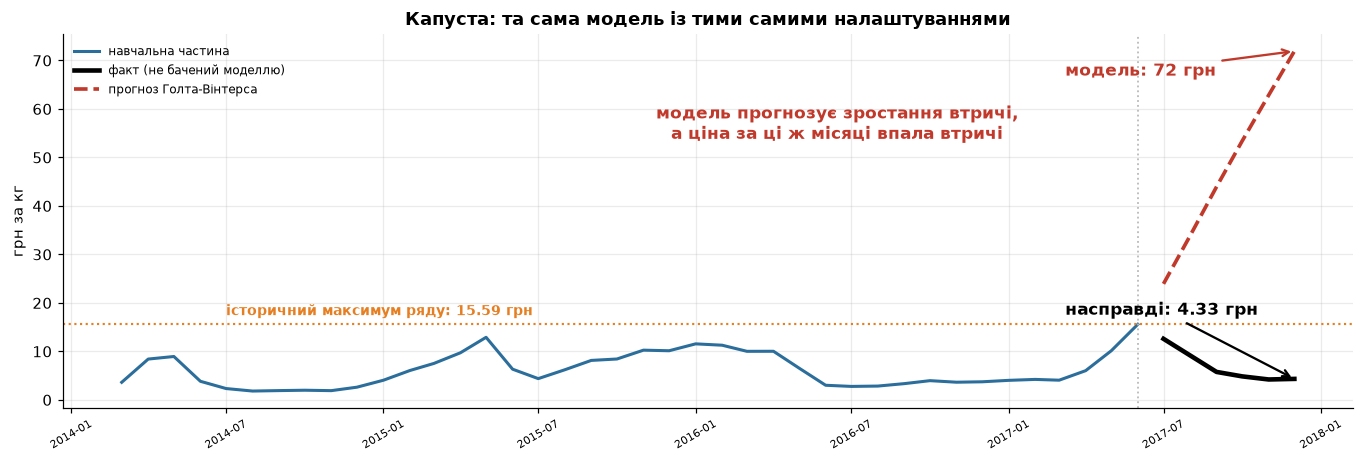

Останні шість місяців навчальної частини (січень–червень 2017):
2017-01-01     4.03
2017-02-01     4.22
2017-03-01     4.06
2017-04-01     6.03
2017-05-01    10.14
2017-06-01    15.59
Freq: MS

Липень – грудень 2017: що було насправді і що передбачила модель
             факт  прогноз  помилка
2017-07-01  12.60    23.94    11.34
2017-08-01   9.18    33.82    24.64
2017-09-01   5.77    43.95    38.18
2017-10-01   4.85    53.41    48.56
2017-11-01   4.21    62.86    58.65
2017-12-01   4.33    71.93    67.60

За ці шість місяців ціна впала з 12.60 до 4.33 грн (у 2.9 раза),
а модель передбачала зростання з 23.94 до 71.93 грн (у 3.0 раза).

Підібрані параметри згладжування:
   рівень  alpha = 1.000
   тренд   beta  = 0.889
   сезон   gamma = 0.000


In [35]:
cabbage_s = avg['Cabbage - Retail'].interpolate()
train2, test2 = cabbage_s[:-6], cabbage_s[-6:]
model2 = ExponentialSmoothing(train2, trend='add', seasonal='add', seasonal_periods=12).fit()
fc2 = model2.forecast(6)

hist_max = cabbage_s.max()

fig, ax = plt.subplots(figsize=(12.5, 4.3))
ax.plot(train2.index, train2.values, lw=2.0, color='#2C6E9B', label='навчальна частина')
ax.plot(test2.index, test2.values, lw=3.0, color='k', label='факт (не бачений моделлю)')
ax.plot(fc2.index, fc2.values, lw=2.4, ls='--', color='#C0392B', label='прогноз Голта-Вінтерса')
ax.axvline(train2.index[-1], color='#bbb', lw=1.2, ls=':')
ax.axhline(hist_max, color='#E67E22', lw=1.4, ls=':')
ax.annotate(f'історичний максимум ряду: {hist_max:.2f} грн',
            xy=(cabbage_s.index[4], hist_max), xytext=(0, 6), textcoords='offset points',
            fontsize=9, color='#E67E22', fontweight='bold')
ax.annotate(f'модель: {fc2.iloc[-1]:.0f} грн',
            xy=(fc2.index[-1], fc2.iloc[-1]), xytext=(-150, -16), textcoords='offset points',
            fontsize=11, color='#C0392B', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#C0392B', lw=1.5))
ax.annotate(f'насправді: {test2.iloc[-1]:.2f} грн',
            xy=(test2.index[-1], test2.iloc[-1]), xytext=(-150, 42), textcoords='offset points',
            fontsize=11, color='k', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='k', lw=1.5))
ax.annotate('модель прогнозує зростання втричі,\nа ціна за ці ж місяці впала втричі',
            xy=(0.60, 0.72), xycoords='axes fraction', fontsize=11, color='#C0392B',
            fontweight='bold', ha='center')
ax.set_title('Капуста: та сама модель із тими самими налаштуваннями', fontweight='bold')
ax.set_ylabel('грн за кг'); ax.legend(fontsize=8, frameon=False, loc='upper left')
ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

print('Останні шість місяців навчальної частини (січень–червень 2017):')
print(train2[-6:].round(2).to_string())
print()
cmp2 = pd.DataFrame({'факт': test2, 'прогноз': fc2})
cmp2['помилка'] = cmp2['прогноз'] - cmp2['факт']
print('Липень – грудень 2017: що було насправді і що передбачила модель')
print(cmp2.round(2).to_string())
print()
print('За ці шість місяців ціна впала з %.2f до %.2f грн (у %.1f раза),'
      % (test2.iloc[0], test2.iloc[-1], test2.iloc[0]/test2.iloc[-1]))
print('а модель передбачала зростання з %.2f до %.2f грн (у %.1f раза).'
      % (fc2.iloc[0], fc2.iloc[-1], fc2.iloc[-1]/fc2.iloc[0]))
print()
print('Підібрані параметри згладжування:')
for cap, key in [('рівень  alpha', 'smoothing_level'),
                 ('тренд   beta ', 'smoothing_trend'),
                 ('сезон   gamma', 'smoothing_seasonal')]:
    print(f'   {cap} = {model2.params[key]:.3f}')

### Що тут сталося

Подивіться на графік: синя лінія — те, що модель бачила, чорна — те, чого вона не бачила,
червона штрихова — її прогноз. Після червня 2017 вони розходяться в **протилежні боки**.

**Модель не просто помилилася в числі — вона переплутала напрямок.**
За липень–грудень 2017 ціна капусти **впала** з 12,60 до 4,33 грн, тобто майже втричі.
Модель за ті самі місяці передбачала **зростання** з 23,94 до 71,92 грн, теж утричі.

До того ж 72 грн — це в 4,6 раза більше за найдорожчу капусту за всю історію ряду (15,59 грн).
Прогноз вийшов за межі всього, що коли-небудь спостерігалося, і вже тільки це мало б
зупинити аналітика ще до того, як він подивиться на метрику.

Подивіться на надруковані параметри згладжування, вони пояснюють усе:

* **gamma = 0** — сезонну складову модель **не підібрала взагалі**. Вона залишилася такою,
  якою була на старті, і в прогнозі майже не працює.
* **beta = 0,89** — натомість модель дуже чутливо стежить за трендом.

А тепер подивіться на останні шість місяців навчальної частини: 4,03 → 4,22 → 4,06 → 6,03 → 10,14 → 15,59.
Це **весняне подорожчання**, звичайна частина річного циклу. Але оскільки сезонної складової
в моделі фактично немає, вона прочитала цей підйом як **тренд** — приблизно +4 гривні щомісяця —
і **продовжила його в майбутнє по прямій, без жодного обмеження**.

Адитивний тренд у Голта-Вінтерса лінійний і **незгасаючий**: скільки б кроків уперед ви не просили,
він додаватиме той самий приріст. Для ряду, який фізично не може вийти за певні межі,
це рецепт катастрофи.

### Чи рятує зміна сезонної складової на мультиплікативну

Перевірмо прямо, а не на здогад.

In [36]:
variants_hw = {
    'add, незгасаючий тренд':  dict(trend='add', seasonal='add'),
    'add, ЗГАСАЮЧИЙ тренд':    dict(trend='add', seasonal='add', damped_trend=True),
    'БЕЗ тренду':              dict(trend=None,  seasonal='add'),
    'мультиплікативний сезон': dict(trend='add', seasonal='mul'),
}
rows_hw = []
for cap, kw in variants_hw.items():
    f = ExponentialSmoothing(train2, seasonal_periods=12, **kw).fit().forecast(6)
    rows_hw.append([cap, metrics(test2, f)['MAE'], f.min(), f.max()])
sn = cabbage_s.shift(12)[-6:]
rows_hw.append(['сезонний наївний', metrics(test2, sn)['MAE'], float(sn.min()), float(sn.max())])
rows_hw.append(['наївний', metrics(test2, pd.Series(train2.iloc[-1], index=test2.index))['MAE'],
                float(train2.iloc[-1]), float(train2.iloc[-1])])
display(pd.DataFrame(rows_hw, columns=['варіант', 'MAE, грн', 'прогноз від', 'прогноз до']).round(2))
print('Історичний діапазон ряду: %.2f … %.2f грн' % (cabbage_s.min(), cabbage_s.max()))

,варіант,"MAE, грн",прогноз від,прогноз до
0,"add, незгасаючий тренд",41.49,23.94,71.93
1,"add, ЗГАСАЮЧИЙ тренд",28.94,22.60,45.08
2,БЕЗ тренду,7.69,14.04,14.82
3,мультиплікативний сезон,52.02,19.81,97.09
4,сезонний наївний,3.44,2.78,3.97
5,наївний,8.77,15.59,15.59


Історичний діапазон ряду: 1.82 … 15.59 грн


**Мультиплікативна сезонність не рятує — вона робить гірше** (MAE 52 проти 41).
Моя початкова здогадка була б неправильною, і саме тому її треба було перевірити, а не припустити.

Допомагає інше:

* **згасаючий тренд** (`damped_trend=True`) — приріст із кожним кроком зменшується в $\phi$ разів,
  тож прогноз виходить на плато замість прямої. Помилка падає з 41 до 29 грн;
* **повна відмова від тренду** — помилка падає до 7,7 грн, бо зникає сама можливість
  екстраполювати підйом у нескінченність;
* але **найкращим усе одно лишається сезонний наївний прогноз** із MAE 3,44 грн.

### Чому модель не змогла підібрати сезонність

Причина — у самих даних. Подивіться, на який місяць припадає річний максимум ціни капусти:

| Рік | 2014 | 2015 | 2016 | 2017 |
|---|---|---|---|---|
| Місяць піку | травень | травень | **січень** | червень |

Пік «гуляє» на пів року. Для порівняння, у моркви це червень, червень, травень, червень,
а в масла — грудень у всі чотири роки.

Ось чому сила сезонності капусти виявилась лише 0,21, хоча коливання видно неозброєним оком:
**розмах коливань у неї стабільний** (8,6 · 7,8 · 8,8 · 11,7 грн за роками),
а от **момент їх настання — ні**. І STL, і Голт-Вінтерс шукають складову, яка повторюється
**в ті самі місяці**; коли фаза плаває, обидва методи не знаходять нічого й відносять
коливання до залишку.

Змістовно це зрозуміло: ціна капусти залежить від того, коли закінчуються запаси з попереднього
врожаю й коли надходить новий, а це різні дати в різні роки. У 2016-му пік припав на січень —
наслідок поганого врожаю 2015-го.

> **Мораль перша.** Незгасаючий лінійний тренд екстраполює **без будь-яких обмежень**.
> Перш ніж повірити прогнозу, порівняйте його з **історичним діапазоном ряду**:
> значення за межами того, що коли-небудь спостерігалося, майже завжди означають
> не відкриття, а поломку моделі. Це перевірка на один рядок коду, і вона ловить
> цілий клас помилок.
>
> **Мораль друга.** Параметри моделі — це **припущення про дані**, а не налаштування за смаком.
> `trend='add'` означає «підйом триватиме вічно», `damped_trend=True` — «згасатиме»,
> `trend=None` — «тренду немає». Обирати треба, подивившись на дані, а не навмання.
>
> **Мораль третя.** Я припустив, що винна сезонна складова, — і помилився:
> мультиплікативний варіант виявився гіршим. **Перевіряйте здогадки обчисленням.**

## Залишки: остання перевірка, яку пропускають найчастіше

Модель має право вважатися прийнятною лише тоді, коли в її залишках **не лишилося структури**.
Якщо залишки автокорельовані — модель не вичерпала інформацію з ряду.

### Теорія: діагностика залишків

Модель вважається придатною не тоді, коли в неї мала помилка, а тоді, коли **в залишках
не лишилося структури**. Якщо в $R_t$ ще є закономірність, її можна було використати —
отже, модель не вичерпала інформацію з ряду.

**Чотири властивості, які перевіряють:**

| Властивість | Навіщо | Як перевірити |
|---|---|---|
| Нульове середнє | інакше прогноз систематично зміщений | подивитися на ME; зміщення легко виправити |
| Відсутність автокореляції | інакше лишилася невикористана структура | ACF залишків, тест Льюнга-Бокса |
| Стала дисперсія | інакше інтервали прогнозу неправильні | графік залишків у часі |
| Нормальність | лише для побудови інтервалів | гістограма, Q-Q графік |

Перші дві є **обов'язковими**: без них прогноз можна покращити.
Дві останні потрібні лише для того, щоб інтервали невизначеності були правильними;
точковий прогноз лишається придатним і без них.

**Тест Льюнга-Бокса** перевіряє автокореляцію не на одному лагу, а на всіх одразу:

$$Q = n(n+2)\sum_{k=1}^{H}\frac{\hat\rho_k^2}{n-k} \;\sim\; \chi^2_{H-K}$$

де $H$ — кількість перевірюваних лагів, $K$ — кількість оцінених параметрів моделі.
Нульова гіпотеза: залишки є білим шумом. **Велике $p$-значення — добре**
(структури не виявлено), мале — модель не вичерпала інформацію.

Зверніть увагу на несподівану логіку: тут ми **хочемо** не відхилити нульову гіпотезу.
Це протилежно до звичного використання критеріїв, і на цьому часто плутаються.

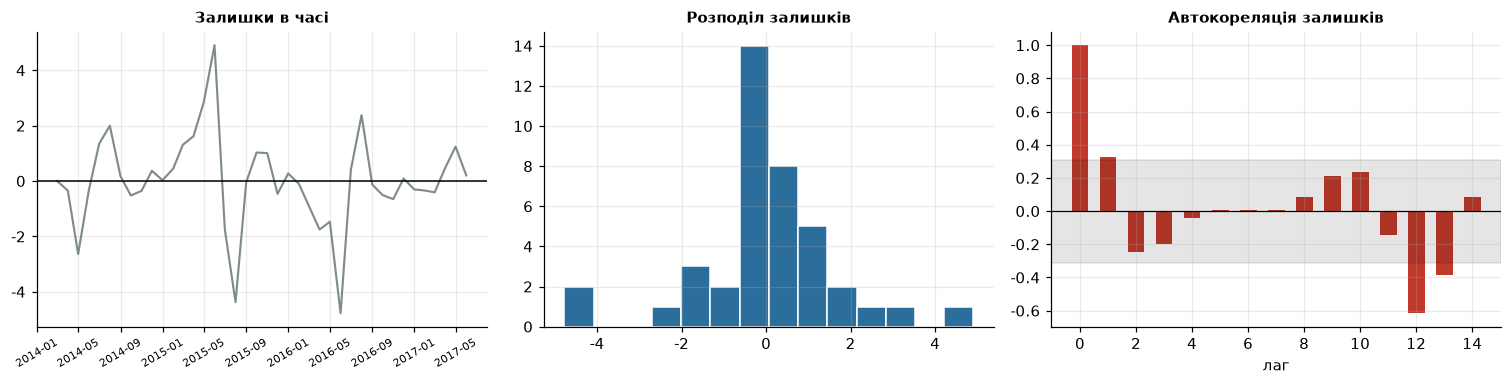

Якщо стовпчики праворуч виходять за сіру смугу — у залишках лишилася структура,
яку модель не пояснила, і її ще можна використати.


In [37]:
resid = model.resid

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(resid.index, resid.values, lw=1.4, color='#7F8C8D')
axes[0].axhline(0, color='k', lw=1)
axes[0].set_title('Залишки в часі', fontsize=10, fontweight='bold')
axes[0].tick_params(axis='x', labelrotation=30, labelsize=7)

axes[1].hist(resid.values, bins=14, color='#2C6E9B', edgecolor='w')
axes[1].set_title('Розподіл залишків', fontsize=10, fontweight='bold')

a = acf(resid.dropna(), nlags=14)
axes[2].bar(range(len(a)), a, color='#C0392B', width=.6)
bound = 1.96/np.sqrt(len(resid.dropna()))
axes[2].axhspan(-bound, bound, color='k', alpha=.10); axes[2].axhline(0, color='k', lw=.8)
axes[2].set_title('Автокореляція залишків', fontsize=10, fontweight='bold')
axes[2].set_xlabel('лаг')
plt.tight_layout(); plt.show()

print('Якщо стовпчики праворуч виходять за сіру смугу — у залишках лишилася структура,')
print('яку модель не пояснила, і її ще можна використати.')

---
### Проміжна відповідь 4

**«Прогноз можливий, але оцінювати його треба інакше».** Найпростіший наївний метод виявився
сильнішим за складніші; випадковий поділ вибірки применшив помилку в 1,7 раза;
дві однаково правильні метрики дали протилежні відповіді на питання, який товар прогнозується краще;
а модель із неправильним припущенням про сезонність видала ціну нижче нуля.

І головне: усе це ми робили на ряді завдовжки 45 місяців, якого **замало** для половини
потрібних інструментів. Останній крок виправляє саме це.

---
# Крок 5. Остаточна відповідь

> **Підзадача кроку.** Перенести аналіз на довгий ряд, де статистичні інструменти
> нарешті працюють на повну силу, і дати відповідь на задачу разом з умовами її чинності.

Повернімося до питання, з якого ми почали. Ми з'ясували, що ціна в гривні — це насправді
**дві величини в одному числі**: вартість товару й вартість гривні. Щоб відповісти на початкове питання,
треба було розібратися з другою складовою. Отже, прогнозувати варто було **курс**.

І тут є практична перевага: курс вимірюють із 1993 року, тобто в нас **347 місяців замість 45**.
Це принципово змінює те, які інструменти стають доступними.

> **Чому довжина ряду вирішує все.** На 45 спостереженнях автокореляційна функція має такі широкі
> довірчі межі, що в них поміщається майже будь-яке значення; тест на стаціонарність має настільки
> низьку потужність, що його висновок не значущий; а сезонна ARIMA витрачає більшу частину
> спостережень на диференціювання. Короткий ряд не забороняє ці методи — він **знецінює їхні висновки**.

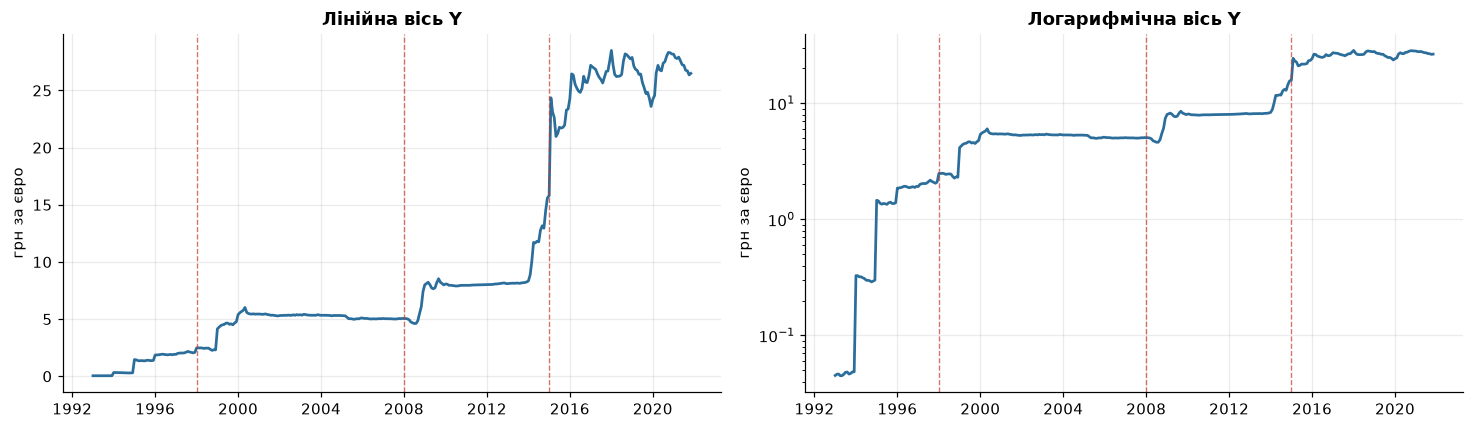

На лінійній осі вся історія до 2008 року — плоска лінія біля нуля.
Насправді там відбулися дві найбільші відносні зміни за весь період.
1993: 0.0453 грн/€   2021: 26.49 грн/€   зміна у 585 разів


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4))
for ax, use_log in zip(axes, [False, True]):
    ax.plot(uah.index, uah.values, lw=1.8, color='#2C6E9B')
    if use_log:
        ax.set_yscale('log')
        ax.set_title('Логарифмічна вісь Y', fontweight='bold')
    else:
        ax.set_title('Лінійна вісь Y', fontweight='bold')
    ax.set_ylabel('грн за євро')
    for yr, label in [(1998, 'криза 1998'), (2008, 'криза 2008'), (2015, 'девальвація 2014–15')]:
        ax.axvline(pd.Timestamp(f'{yr}-01-01'), color='#C0392B', lw=.9, ls='--', alpha=.7)
plt.tight_layout(); plt.show()

print('На лінійній осі вся історія до 2008 року — плоска лінія біля нуля.')
print('Насправді там відбулися дві найбільші відносні зміни за весь період.')
print(f'1993: {uah.iloc[0]:.4f} грн/€   2021: {uah.iloc[-1]:.2f} грн/€   '
      f'зміна у {uah.iloc[-1]/uah.iloc[0]:,.0f} разів')

Ось ще одне застосування шкали як шару граматики. **Логарифмічна вісь показує відносні зміни**:
однакова відстань по вертикалі означає однакову зміну у відсотках, а не в гривнях.
Для величини, що змінилася в тисячі разів, це єдиний спосіб побачити весь ряд одночасно.

## 5.1. Стаціонарність

**Стаціонарний ряд** — це ряд, статистичні властивості якого не змінюються з часом:
середнє, дисперсія і структура автокореляції однакові в будь-якому вікні.

Це не естетична вимога. Більшість класичних моделей (зокрема ARIMA) **виведені за припущення
стаціонарності** й на нестаціонарному ряді дають формально порахований, але беззмістовний результат.

### Теорія: стаціонарність

**Строга стаціонарність.** Процес $\{Y_t\}$ строго стаціонарний, якщо спільний розподіл
будь-якого набору $(Y_{t_1},\dots,Y_{t_k})$ не змінюється при зсуві всіх моментів на однакову
величину. Це дуже сильна умова, яку на практиці не перевіряють.

**Слабка стаціонарність** (стаціонарність другого порядку) вимагає лише трьох речей:

1. $\mathbb{E}[Y_t] = \mu$ — середнє стале й не залежить від $t$;
2. $\operatorname{Var}(Y_t) = \sigma^2 < \infty$ — дисперсія стала й скінченна;
3. $\operatorname{Cov}(Y_t, Y_{t+k}) = \gamma_k$ — коваріація залежить **лише від зсуву** $k$,
   а не від того, у якому місці ряду ми її міряємо.

Саме цю, слабку, умову мають на увазі, коли кажуть «ряд стаціонарний».

**Зверніть увагу на пункт 2.** Порушити стаціонарність можна не лише «пливучим» середнім,
а й **змінною дисперсією**. Це стане ключовим за кілька клітинок, коли два тести
дадуть протилежні відповіді.

### Випадкове блукання та одиничний корінь

**Випадкове блукання:**
$$Y_t = Y_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \text{білий шум}$$

Розкривши рекурсію: $Y_t = Y_0 + \sum_{i=1}^{t}\varepsilon_i$, звідки
$\operatorname{Var}(Y_t) = t\sigma^2$ — дисперсія **зростає з часом**, отже, умову 2 порушено.

Запишемо це через **оператор зсуву назад** $B$, для якого $B y_t = y_{t-1}$:
$$(1-B)Y_t = \varepsilon_t$$
Многочлен $1-z$ має корінь $z=1$ — звідси й назва **одиничний корінь**.
Ряд із одиничним коренем стає стаціонарним після взяття різниці; кажуть, що він
**інтегрований порядку 1**, позначення $I(1)$.

Головна властивість випадкового блукання, важлива для практики: **найкращий можливий
прогноз для нього — останнє спостереження**. Жодна модель не зробить краще, бо
наступний приріст незалежний від усього попереднього. Якщо ваш ряд близький
до випадкового блукання, наївний прогноз непереможний — і це не поразка, а властивість даних.

### Два тести

| | **ADF** (Augmented Dickey-Fuller) | **KPSS** |
|---|---|---|
| $H_0$ | є одиничний корінь (**не**стаціонарний) | ряд стаціонарний |
| $H_1$ | стаціонарний | є одиничний корінь |
| Мале $p$ означає | стаціонарний | **не**стаціонарний |

Їх застосовують **у парі**, бо обидва мають слабкі місця: ADF має низьку потужність
на коротких рядах і схильний не відхиляти $H_0$; KPSS чутливий до вибору кількості лагів.

**Чотири можливі результати:**

| ADF | KPSS | Висновок |
|---|---|---|
| відхиляє | не відхиляє | ряд стаціонарний — обидва згодні |
| не відхиляє | відхиляє | ряд нестаціонарний — обидва згодні |
| не відхиляє | не відхиляє | даних замало для висновку |
| відхиляє | відхиляє | **ряд нестаціонарний не тим способом, який шукає ADF** |

Останній рядок — саме те, що ви зараз побачите на першій різниці курсу.

### Способи досягнення стаціонарності

| Проблема | Засіб | Формула |
|---|---|---|
| рівень «пливе» | перша різниця | $\nabla y_t = y_t - y_{t-1}$ |
| сезонні коливання | сезонна різниця | $\nabla_m y_t = y_t - y_{t-m}$ |
| дисперсія зростає з рівнем | логарифмування | $\log y_t$ |
| дисперсія зростає інакше | перетворення Бокса-Кокса | $\frac{y^\lambda - 1}{\lambda}$ |
| детермінований тренд | віднімання підігнаного тренду | $y_t - (\hat a + \hat b t)$ |

**Пересторога про надлишкове диференціювання.** Узяти різницю зайвий раз — теж помилка:
вона вносить у ряд штучну від'ємну автокореляцію на першому лагу й збільшує дисперсію.
Ознака: після диференціювання $\hat\rho_1$ стає помітно від'ємною (близько $-0{,}5$).
Беріть різницю рівно стільки разів, скільки потрібно, — зазвичай один, зрідка два.

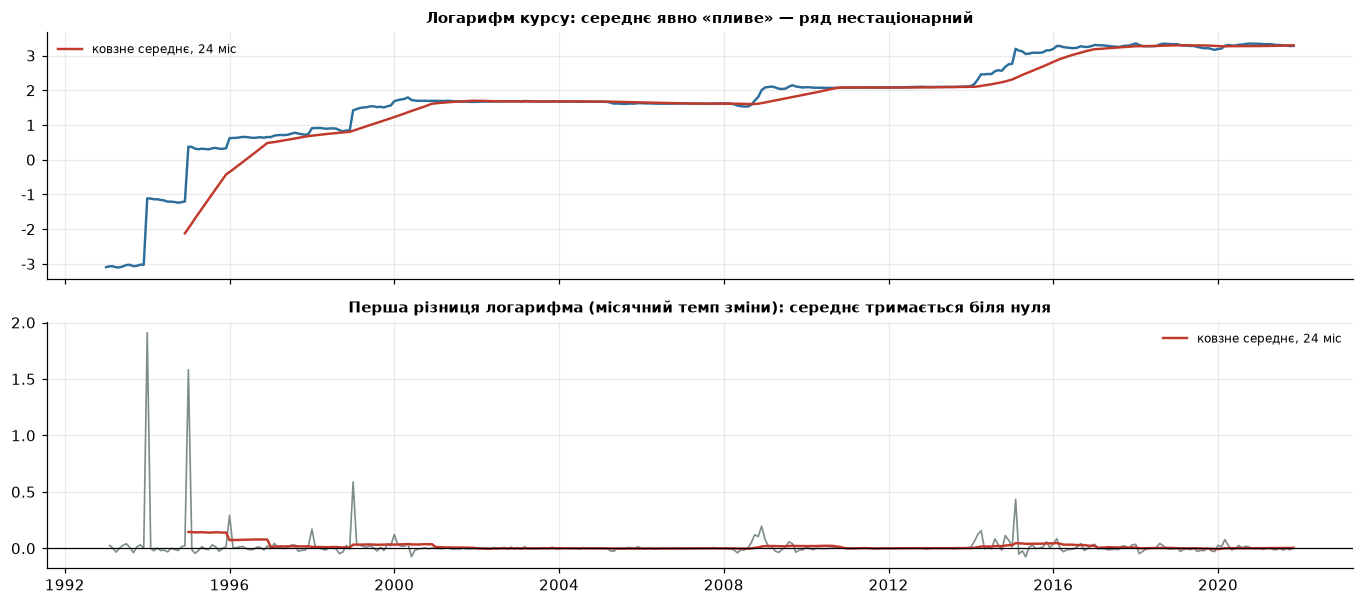

,ряд,ADF p-value,KPSS p-value,висновок
0,логарифм курсу,0.5099,0.0100,нестаціонарний (обидва тести згодні)
1,перша різниця,0.0000,0.0359,ТЕСТИ СУПЕРЕЧАТЬ


In [39]:
from statsmodels.tsa.stattools import adfuller, kpss

log_rate = np.log(uah)
d_log  = log_rate.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.6), sharex=True)
axes[0].plot(log_rate.index, log_rate.values, lw=1.6, color='#2C6E9B')
axes[0].plot(log_rate.rolling(24).mean(), lw=1.6, color='#C0392B', label='ковзне середнє, 24 міс')
axes[0].set_title('Логарифм курсу: середнє явно «пливе» — ряд нестаціонарний',
                  fontweight='bold', fontsize=10)
axes[0].legend(fontsize=8, frameon=False)

axes[1].plot(d_log.index, d_log.values, lw=1.1, color='#7F8C8D')
axes[1].plot(d_log.rolling(24).mean(), lw=1.6, color='#C0392B', label='ковзне середнє, 24 міс')
axes[1].axhline(0, color='k', lw=.8)
axes[1].set_title('Перша різниця логарифма (місячний темп зміни): середнє тримається біля нуля',
                  fontweight='bold', fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

rows = []
for title, ser in [('логарифм курсу', log_rate.dropna()), ('перша різниця', d_log)]:
    adf_p  = adfuller(ser, autolag='AIC')[1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kpss_p = kpss(ser, regression='c', nlags='auto')[1]
    if   adf_p < .05 and kpss_p > .05: verdict = 'стаціонарний (обидва тести згодні)'
    elif adf_p > .05 and kpss_p < .05: verdict = 'нестаціонарний (обидва тести згодні)'
    else:                              verdict = 'ТЕСТИ СУПЕРЕЧАТЬ'
    rows.append([title, adf_p, kpss_p, verdict])
display(pd.DataFrame(rows, columns=['ряд', 'ADF p-value', 'KPSS p-value', 'висновок']).round(4))

Два тести з **протилежними нульовими гіпотезами** — і це навмисно:

* **ADF** (Augmented Dickey-Fuller): $H_0$ — ряд **не**стаціонарний. Мале $p$ → відкидаємо → ряд стаціонарний.
* **KPSS**: $H_0$ — ряд **стаціонарний**. Мале $p$ → відкидаємо → ряд нестаціонарний.

Їх застосовують у парі саме тому, що обидва мають слабкі місця.

**І подивіться на другий рядок таблиці — там тести не погодились.** ADF упевнено каже «стаціонарний»
($p < 0{,}001$), KPSS так само впевнено каже «ні» ($p < 0{,}05$). Це не помилка обчислень і не привід
обрати той тест, який нам зручніший.

Суперечність означає, що ряд порушує стаціонарність **не тим способом, який шукає ADF**.
ADF перевіряє, чи «пливе» середнє. У нашої першої різниці середнє тримається біля нуля —
подивіться на нижнє поле попереднього графіка, червона лінія майже пласка. А от **мінливість
не стала сталою**: у 1993–1995 роках місячні коливання були в десятки разів більшими, ніж у 2000-х.
Стаціонарність вимагає сталості **всіх** властивостей, не лише середнього.

Це важливий урок: **тест не відповідає на питання «чи хороші мої дані»**. Він відповідає на одне
вузьке питання, і коли два тести суперечать — вони обидва праві, просто про різне.
Що робити далі: або обмежити період (після 1996 року, коли запровадили гривню),
або змоделювати мінливість окремо (моделі типу GARCH, поза межами нашого курсу).

**Способи досягнення стаціонарності:**

| Проблема | Засіб |
|---|---|
| рівень «пливе» | взяти першу різницю $y_t - y_{t-1}$ |
| сезонні коливання | сезонна різниця $y_t - y_{t-m}$ |
| дисперсія зростає разом із рівнем | логарифмування (ми це вже зробили) |
| явний детермінований тренд | відняти підігнаний тренд |

Ми застосували два з них: спершу логарифм, потім першу різницю. Саме цю пару позначають
літерами **I(1)** у назві ARIMA.

### Теорія: часткова автокореляційна функція

**Навіщо потрібна друга функція.** Якщо $y_t$ залежить від $y_{t-1}$, а $y_{t-1}$ — від $y_{t-2}$,
то ACF покаже зв'язок і на лагу 2, навіть якщо прямого зв'язку між $y_t$ і $y_{t-2}$ немає.
Це «транзитивний» зв'язок, що проходить через проміжну точку.

**Часткова автокореляція** $\phi_{kk}$ усуває цей ефект: це кореляція між $y_t$ і $y_{t-k}$
**після вилучення впливу всіх проміжних значень** $y_{t-1},\dots,y_{t-k+1}$.
Формально — коефіцієнт при $y_{t-k}$ у регресії

$$y_t = \phi_{k1}y_{t-1} + \phi_{k2}y_{t-2} + \dots + \phi_{kk}y_{t-k} + \varepsilon_t$$

Оцінюють її рекурентно через **рівняння Юла-Вокера** (у коді це метод `ywm`).

**Аналогія, яка допомагає:** ACF — це «чи пов'язані взагалі», PACF — «чи пов'язані **напряму**».

### Як за ними визначають структуру моделі

| ACF | PACF | Модель |
|---|---|---|
| обривається після лагу $q$ | спадає поступово | **MA($q$)** — ковзне середнє |
| спадає поступово | обривається після лагу $p$ | **AR($p$)** — авторегресія |
| спадає поступово | спадає поступово | **ARMA($p,q$)** — змішана |
| спадає дуже повільно, майже лінійно | великий сплеск на лагу 1 | потрібне **диференціювання** |
| сплески на лагах $m$, $2m$, $3m$ | сплеск на лагу $m$ | є **сезонна** складова з періодом $m$ |

«Обривається» означає: різко падає в довірчі межі й більше з них не виходить.

**Важлива пересторога.** Це правило дає **кандидатів**, а не відповідь. На реальних даних
картина рідко буває такою чіткою, як у підручнику, а на коротких рядах — майже ніколи.
Сучасна практика: за ACF і PACF обрати кілька кандидатів, підігнати їх усі
й порівняти за інформаційним критерієм. Саме так працює `auto_arima`.

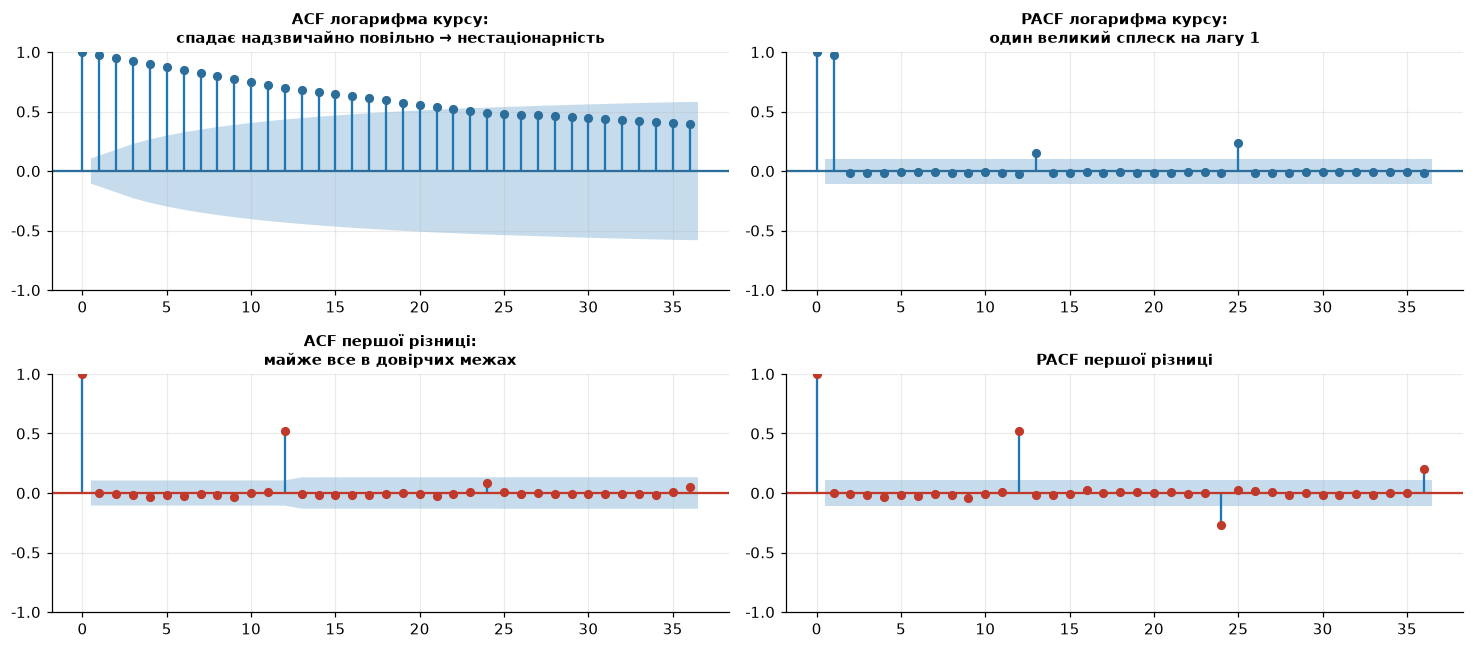

In [40]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(13.5, 6))
plot_acf (log_rate.dropna(), lags=36, ax=axes[0,0], color='#2C6E9B')
axes[0,0].set_title('ACF логарифма курсу:\nспадає надзвичайно повільно → нестаціонарність',
                    fontsize=10, fontweight='bold')
plot_pacf(log_rate.dropna(), lags=36, ax=axes[0,1], method='ywm', color='#2C6E9B')
axes[0,1].set_title('PACF логарифма курсу:\nодин великий сплеск на лагу 1', fontsize=10, fontweight='bold')
plot_acf (d_log, lags=36, ax=axes[1,0], color='#C0392B')
axes[1,0].set_title('ACF першої різниці:\nмайже все в довірчих межах', fontsize=10, fontweight='bold')
plot_pacf(d_log, lags=36, ax=axes[1,1], method='ywm', color='#C0392B')
axes[1,1].set_title('PACF першої різниці', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

Ось для чого потрібні були 347 спостережень. Верхній лівий графік — **еталонний вигляд
нестаціонарного ряду**: автокореляція близька до одиниці й спадає лінійно, а не експоненційно.
На 45 точках ця картина була б невиразною.

**Як читають цю пару функцій:**

| Що видно | Що це означає |
|---|---|
| ACF спадає дуже повільно | потрібне диференціювання |
| ACF обривається після лагу $q$ | модель ковзного середнього MA($q$) |
| PACF обривається після лагу $p$ | авторегресія AR($p$) |
| обидві спадають поступово | змішана модель ARMA |
| сплеск на лагу 12, 24, 36 | сезонна складова з періодом 12 |

### Теорія: моделі ARIMA

Назва розшифровується як **AutoRegressive Integrated Moving Average**.

**Авторегресія AR($p$)** — значення залежить від власних попередніх значень:
$$y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$$

**Ковзне середнє MA($q$)** — значення залежить від попередніх **помилок**:
$$y_t = c + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots + \theta_q\varepsilon_{t-q}$$

**Інтегрування I($d$)** — скільки разів узято різницю, щоб досягти стаціонарності.

Разом, через оператор зсуву $B$:
$$\phi_p(B)\,(1-B)^d\,y_t = c + \theta_q(B)\,\varepsilon_t$$

**Сезонне розширення SARIMA** записують як $\text{ARIMA}(p,d,q)(P,D,Q)_m$,
де великі літери позначають ті самі складові, але на сезонних лагах.

**Окремі випадки, які корисно впізнавати:**

| Позначення | Що це насправді |
|---|---|
| ARIMA(0,0,0) | білий шум |
| ARIMA(0,1,0) | випадкове блукання |
| ARIMA(0,1,0) з константою | випадкове блукання з дрейфом |
| ARIMA(0,1,1) | просте експоненційне згладжування |
| ARIMA(0,2,2) | метод Голта |

Останні два рядки показують, що ARIMA й експоненційне згладжування — не конкуренти,
а різні описи частково однієї родини моделей.

### Методологія Бокса-Дженкінса

Класична процедура побудови (Box & Jenkins, 1970) складається з чотирьох кроків:

1. **Ідентифікація** — досягти стаціонарності (обрати $d$), за ACF і PACF обрати кандидатів на $p$, $q$.
2. **Оцінювання** — підігнати параметри методом максимальної правдоподібності.
3. **Перевірка** — діагностика залишків: ACF, тест Льюнга-Бокса.
4. **Прогнозування** — і обов'язково порівняння з наївним базисом.

**Вибір між кандидатами** роблять за інформаційними критеріями:

$$\text{AIC} = -2\ln L + 2K, \qquad \text{BIC} = -2\ln L + K\ln n$$

де $L$ — правдоподібність, $K$ — кількість параметрів. Обидва штрафують за складність;
BIC штрафує сильніше й тому обирає простіші моделі. **Менше значення — краще.**

**Два застереження.** По-перше, AIC і BIC **не можна порівнювати між моделями з різним $d$**,
бо після диференціювання змінюється сам ряд, для якого рахується правдоподібність.
По-друге, кращий AIC **не означає кращий прогноз**: критерій оцінює узгодженість
з навчальними даними, а не прогностичну здатність. Остаточне слово завжди
за ретроспективною перевіркою з рухомим початком.

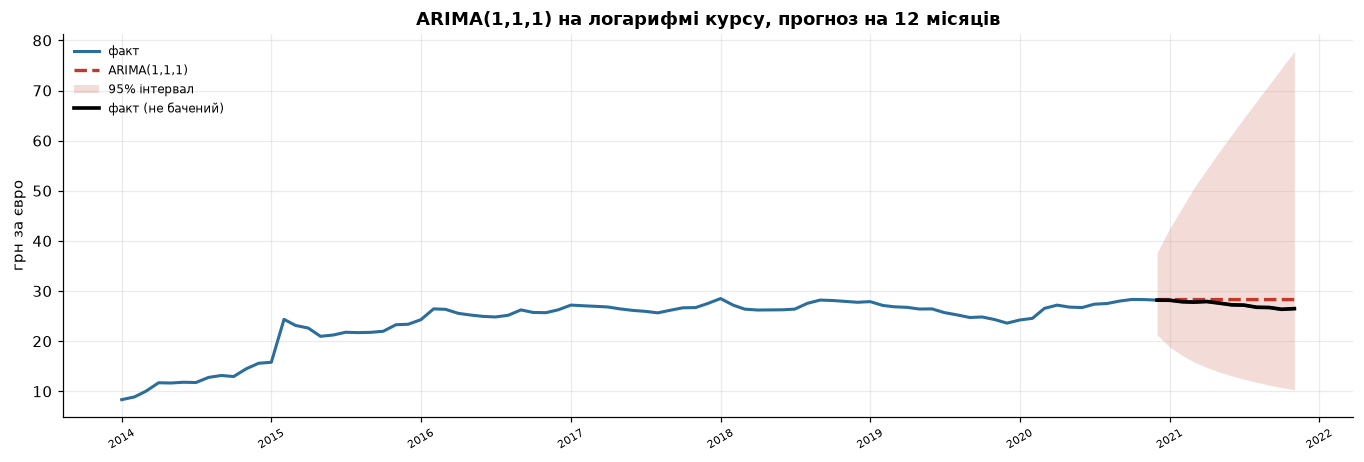

,MAE,RMSE,MAPE
"ARIMA(1,1,1)",0.940,1.129,3.490
наївний прогноз,0.937,1.127,3.481


In [41]:
from statsmodels.tsa.arima.model import ARIMA

train_r, test_r = log_rate[:-12], log_rate[-12:]
arima = ARIMA(train_r, order=(1, 1, 1)).fit()
fc_r  = arima.get_forecast(12)
mean_fc   = fc_r.predicted_mean
ci    = fc_r.conf_int()

fig, ax = plt.subplots(figsize=(12.5, 4.3))
window = log_rate['2014':]
ax.plot(window.index, np.exp(window.values), lw=2, color='#2C6E9B', label='факт')
ax.plot(mean_fc.index, np.exp(mean_fc.values), lw=2.2, ls='--', color='#C0392B', label='ARIMA(1,1,1)')
ax.fill_between(mean_fc.index, np.exp(ci.iloc[:, 0]), np.exp(ci.iloc[:, 1]),
                color='#C0392B', alpha=.18, lw=0, label='95% інтервал')
ax.plot(test_r.index, np.exp(test_r.values), lw=2.4, color='k', label='факт (не бачений)')
ax.set_title('ARIMA(1,1,1) на логарифмі курсу, прогноз на 12 місяців', fontweight='bold')
ax.set_ylabel('грн за євро'); ax.legend(fontsize=8, frameon=False)
ax.tick_params(axis='x', labelrotation=30, labelsize=7)
plt.tight_layout(); plt.show()

naive = pd.Series(np.exp(train_r.iloc[-1]), index=test_r.index)
display(pd.DataFrame({'ARIMA(1,1,1)':   metrics(np.exp(test_r), np.exp(mean_fc)),
                      'наївний прогноз': metrics(np.exp(test_r), naive)}).T.round(3))

Зверніть увагу на два моменти.

По-перше, **95-відсотковий інтервал надзвичайно широкий** — і це чесно. Курс валюти близький
до випадкового блукання, а для випадкового блукання найкращий можливий прогноз — це останнє значення.
Невизначеність зростає як $\sqrt{h}$, і жодна модель цього не обійде.

По-друге, порівняйте рядки в таблиці. Якщо ARIMA не перевершила наївний прогноз — це **не поразка методу**,
а інформація про природу ряду: у ньому просто немає структури, придатної для прогнозування.
Знати це — цінний результат. Гірше було б показати красивий графік і промовчати про базис.

## 5.2. Аномалії та точки зміни режиму

Це два різні поняття, які часто плутають.

| | Що це | Приклад |
|---|---|---|
| **Викид (аномалія)** | одне спостереження, яке не вкладається в загальну картину; далі ряд повертається до звичної поведінки | помилка оператора, разова акція |
| **Точка зміни режиму** | момент, після якого **змінюються самі статистичні властивості** ряду — рівень, мінливість або залежність | девальвація, зміна закону, нова технологія |
| **Сезонний сплеск** | регулярне відхилення, що повторюється з відомим періодом | капуста навесні |

Плутанина між ними коштує дорого: викид можна виправити, сезонність — змоделювати,
а зміна режиму означає, що **дані до неї більше не описують ту саму систему** і навчатися на них небезпечно.

### Теорія: виявлення точок зміни режиму

**Точка зміни режиму** (*change point*, *structural break*) — момент $\tau$, після якого
змінюються параметри процесу, що породжує ряд: рівень, нахил, дисперсія або структура
автокореляції.

**Чому це важливіше, ніж здається.** Уся машина прогнозування будується на припущенні,
що майбутнє схоже на минуле. Зміна режиму це припущення руйнує: дані до $\tau$ описують
**іншу систему**. Навчання на них не просто марне — воно шкідливе.

**Основні підходи:**

| Метод | Ідея | Коли доречний |
|---|---|---|
| Правило $k\sigma$ на приростах | позначити $|\Delta y_t| > k\,\sigma_{\Delta}$ | швидка розвідка; багато хибних тривог |
| **CUSUM** | накопичена сума відхилень від середнього; злам означає зсув | поступові зсуви рівня |
| **Тест Чоу** | порівняння регресій до і після заданої точки | точка відома заздалегідь |
| **Тест Бая-Перрона** | пошук кількох невідомих зламів у регресії | економетричні задачі |
| **PELT** | точна мінімізація функції втрат зі штрафом за кількість точок | кілька точок, довгі ряди |
| **Байєсів онлайн-метод** | ймовірність зміни режиму в реальному часі | потокові дані |

У цьому зошиті ми користуємося найпростішим правилом — і далі побачимо, до чого
воно призводить, якщо застосувати його необережно.

**Обов'язкова послідовність дій:**

1. **Зняти те, що пояснюється** — тренд і сезонність. Інакше детектор знаходитиме сезон.
2. **Шукати в залишках**, а не у вихідному ряді.
3. **Перевірити стійкість**: чи повернувся ряд до попередньої поведінки після знайденої точки?
   Повернувся — це був викид. Не повернувся — це зміна режиму.
4. **Шукати зовнішнє пояснення.** Точка зміни режиму майже завжди має причину поза даними:
   рішення регулятора, війна, нова технологія. Якщо пояснення немає —
   спершу перевірте, чи не є це артефактом збору даних.

**Не лише рівень.** Режим може змінитися й без зсуву рівня — через зміну **мінливості**.
Наступна клітинка дивиться на обидва аспекти окремо, і ви побачите, що в курсі гривні
змінилося і те, і те.

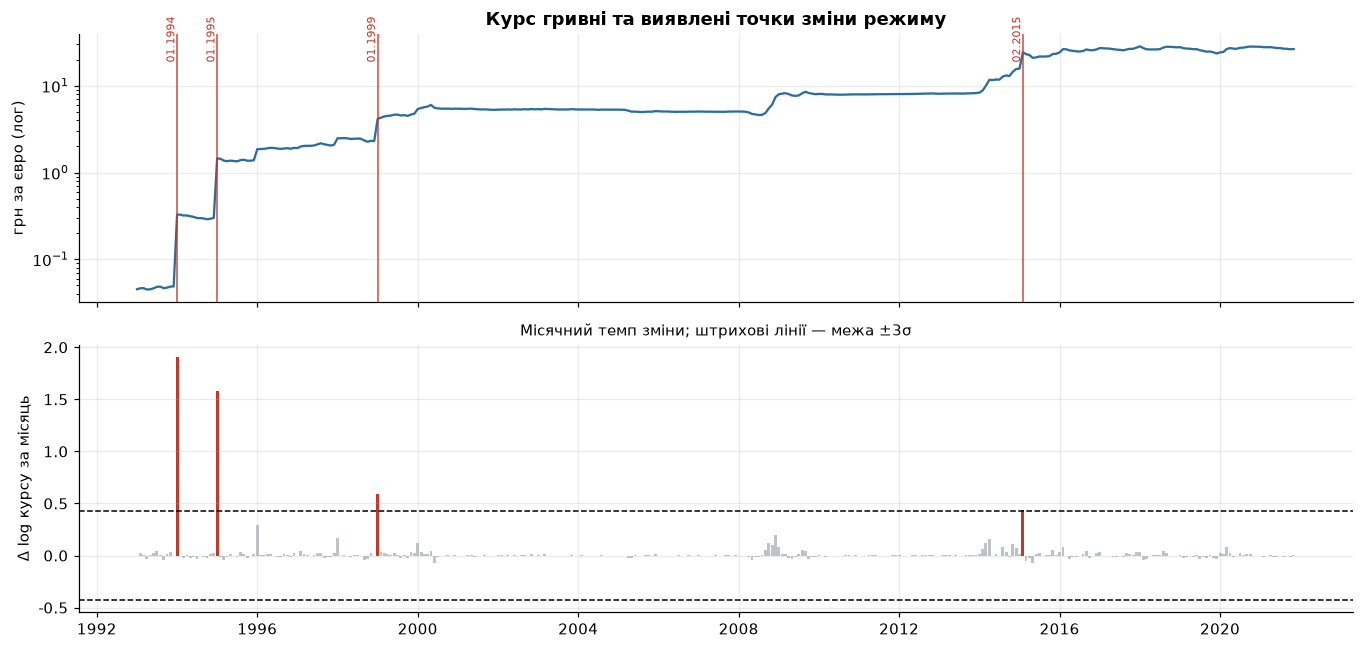

,Δ log,курс до,курс після
дата,,,
1994-01-01,1.909,0.049,0.328
1995-01-01,1.581,0.301,1.460
1999-01-01,0.587,2.308,4.151
2015-02-01,0.433,15.797,24.360


In [42]:
chg = np.log(uah).diff().dropna()
thr = 3 * chg.std()
jumps = chg[chg.abs() > thr].sort_values(key=abs, ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(12.5, 6), sharex=True)
axes[0].plot(uah.index, uah.values, lw=1.5, color='#2C6E9B'); axes[0].set_yscale('log')
axes[0].set_ylabel('грн за євро (лог)')
axes[0].set_title('Курс гривні та виявлені точки зміни режиму', fontweight='bold')

jump_colors = plt.cm.autumn(np.linspace(0, .7, len(jumps)))
for d in jumps.index:
    axes[0].axvline(d, color='#C0392B', lw=1.2, alpha=.75)
    axes[0].annotate(d.strftime('%m.%Y'), xy=(d, uah.max()*.7), rotation=90,
                     fontsize=7.5, color='#C0392B', ha='right')

axes[1].bar(chg.index, chg.values, width=26,
            color=np.where(chg.abs() > thr, '#C0392B', '#BDC3C7'))
axes[1].axhline( thr, color='k', ls='--', lw=1)
axes[1].axhline(-thr, color='k', ls='--', lw=1)
axes[1].set_ylabel('Δ log курсу за місяць')
axes[1].set_title('Місячний темп зміни; штрихові лінії — межа ±3σ', fontsize=10)
plt.tight_layout(); plt.show()

display(pd.DataFrame({'Δ log': jumps.round(3),
                      'курс до': uah.shift(1)[jumps.index].round(3),
                      'курс після': uah[jumps.index].round(3)}))

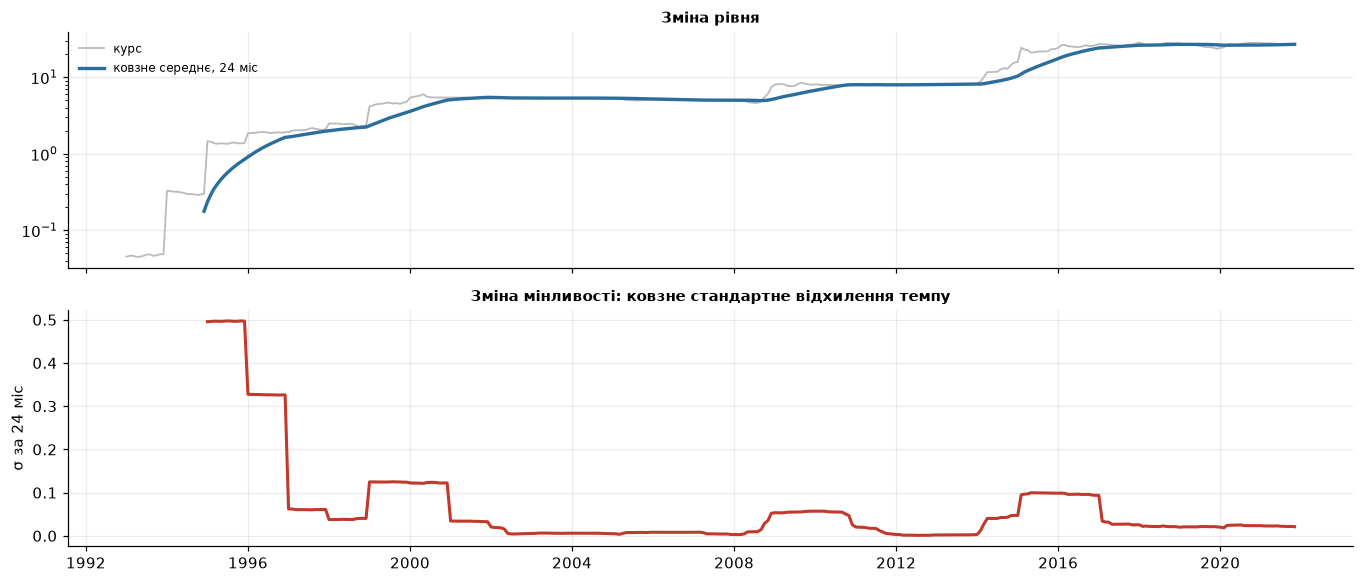

Середній рівень до грудня 2014: 5.06 грн/€
Середній рівень із січня 2015:  25.89 грн/€   (у 5.12 раза вище)

Зверніть увагу на нижнє поле: змінюється не лише рівень, а й мінливість.
Ряд після 2014 року — інший об'єкт, а не продовження попереднього.


In [43]:
# Інший підхід: не окремий стрибок, а зсув рівня між двома вікнами
win = 24
roll_mean = uah.rolling(win).mean()
roll_std = np.log(uah).diff().rolling(win).std()

fig, axes = plt.subplots(2, 1, figsize=(12.5, 5.4), sharex=True)
axes[0].plot(uah.index, uah.values, lw=1.2, color='#bbb', label='курс')
axes[0].plot(roll_mean.index, roll_mean.values, lw=2.2, color='#2C6E9B', label='ковзне середнє, 24 міс')
axes[0].set_yscale('log'); axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title('Зміна рівня', fontweight='bold', fontsize=10)

axes[1].plot(roll_std.index, roll_std.values, lw=2, color='#C0392B')
axes[1].set_title('Зміна мінливості: ковзне стандартне відхилення темпу', fontweight='bold', fontsize=10)
axes[1].set_ylabel('σ за 24 міс')
plt.tight_layout(); plt.show()

before  = uah[:'2014-11'].mean(); after = uah['2015-01':].mean()
print(f'Середній рівень до грудня 2014: {before:.2f} грн/€')
print(f'Середній рівень із січня 2015:  {after:.2f} грн/€   (у {after/before:.2f} раза вище)')
print('\nЗверніть увагу на нижнє поле: змінюється не лише рівень, а й мінливість.')
print('Ряд після 2014 року — інший об\'єкт, а не продовження попереднього.')

## ❓ Питання 10 — остання пастка на сьогодні

Найпоширеніше правило пошуку аномалій: позначити всі місяці, де зміна перевищила
два стандартні відхилення. Застосуймо його до моркви — ряду з добре видимою річною регулярністю.

**Чи є серед позначених точок справжні аномалії?**

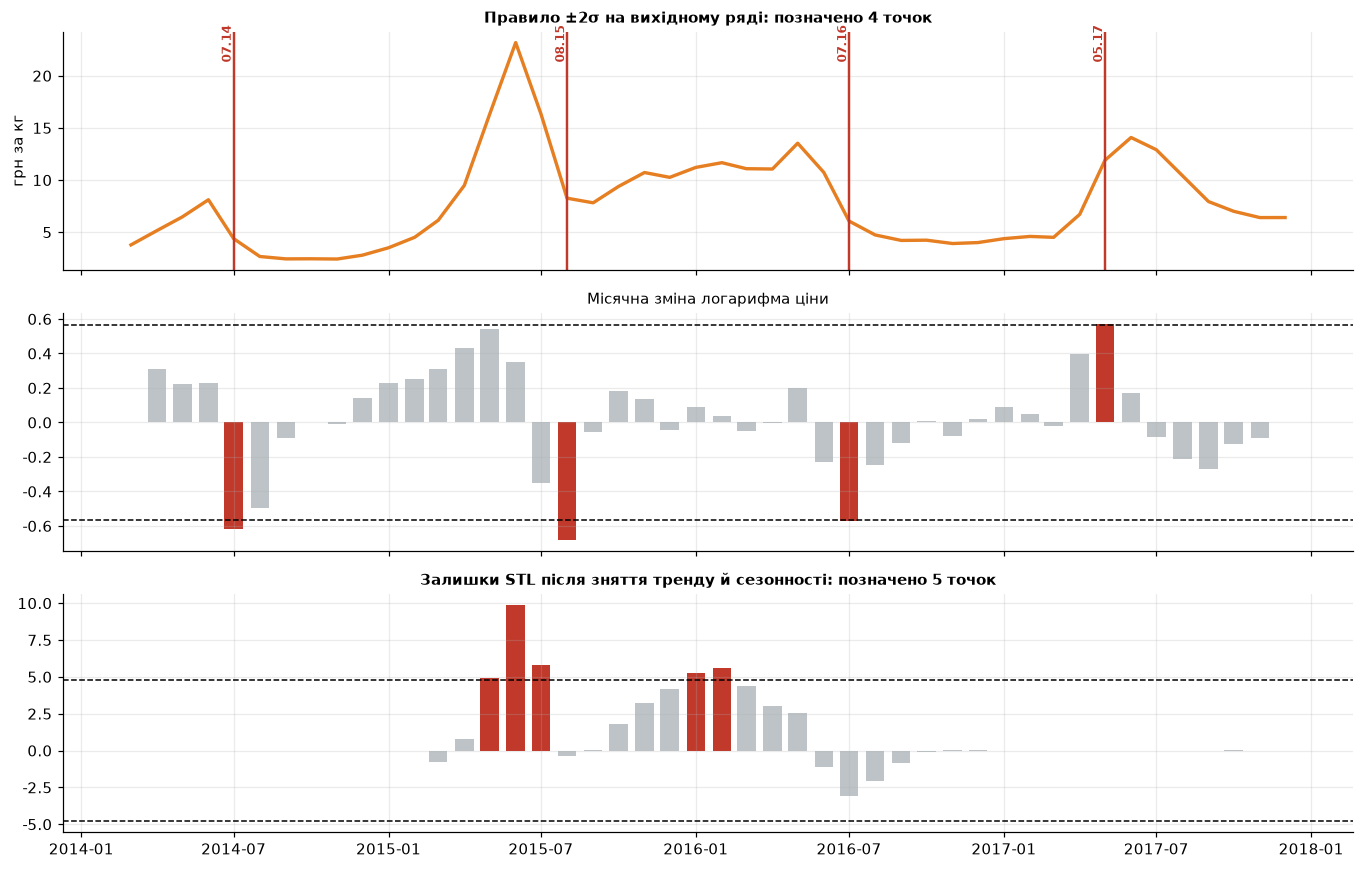

Позначені вихідним правилом:
   07.2014  (липень   ) Δlog = -0.62
   08.2015  (серпень  ) Δlog = -0.68
   07.2016  (липень   ) Δlog = -0.57
   05.2017  (травень  ) Δlog = +0.57

Усі вони припадають на місяці: травень, липень, серпень

Позначені в залишках STL:
   05.2015  (травень  ) залишок = +4.93 грн
   06.2015  (червень  ) залишок = +9.89 грн
   07.2015  (липень   ) залишок = +5.83 грн
   01.2016  (січень   ) залишок = +5.29 грн
   02.2016  (лютий    ) залишок = +5.62 грн


In [44]:
carrots = avg['Carrots - Retail'].interpolate()
chg_c = np.log(carrots).diff().dropna()
thr_c = 2 * chg_c.std()
flagged = chg_c[chg_c.abs() > thr_c]

stl_c = STL(carrots, period=12, robust=True).fit()
resid_c = stl_c.resid
thr_r = 2 * resid_c.std()
flagged_r = resid_c[resid_c.abs() > thr_r]

fig, axes = plt.subplots(3, 1, figsize=(12.5, 8), sharex=True)

axes[0].plot(carrots.index, carrots.values, lw=2.2, color='#E67E22')
for d in flagged.index:
    axes[0].axvline(d, color='#C0392B', lw=1.6)
    axes[0].annotate(d.strftime('%m.%y'), xy=(d, carrots.max()*.93), rotation=90,
                     fontsize=8, color='#C0392B', ha='right', fontweight='bold')
axes[0].set_title('Правило ±2σ на вихідному ряді: позначено %d точок' % len(flagged),
                  fontweight='bold', fontsize=10)
axes[0].set_ylabel('грн за кг')

axes[1].bar(chg_c.index, chg_c.values, width=22,
            color=np.where(chg_c.abs() > thr_c, '#C0392B', '#BDC3C7'))
axes[1].axhline( thr_c, color='k', ls='--', lw=1); axes[1].axhline(-thr_c, color='k', ls='--', lw=1)
axes[1].set_title('Місячна зміна логарифма ціни', fontsize=10)

axes[2].bar(resid_c.index, resid_c.values, width=22,
            color=np.where(resid_c.abs() > thr_r, '#C0392B', '#BDC3C7'))
axes[2].axhline( thr_r, color='k', ls='--', lw=1); axes[2].axhline(-thr_r, color='k', ls='--', lw=1)
axes[2].set_title('Залишки STL після зняття тренду й сезонності: позначено %d точок' % len(flagged_r),
                  fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

MONTHS = {1:'січень',2:'лютий',3:'березень',4:'квітень',5:'травень',6:'червень',
          7:'липень',8:'серпень',9:'вересень',10:'жовтень',11:'листопад',12:'грудень'}
print('Позначені вихідним правилом:')
for d, v in flagged.items():
    print(f'   {d:%m.%Y}  ({MONTHS[d.month]:<9}) Δlog = {v:+.2f}')
print('\nУсі вони припадають на місяці:', ', '.join(MONTHS[m] for m in sorted({d.month for d in flagged.index})))
print('\nПозначені в залишках STL:')
for d, v in flagged_r.items():
    print(f'   {d:%m.%Y}  ({MONTHS[d.month]:<9}) залишок = {v:+.2f} грн')

<details>
<summary><b>💡 Відповідь</b></summary>

**Жодної.** Усі чотири точки — це той самий літній збір урожаю, який повторюється **щороку**.

Подивіться на список місяців: травень, липень, серпень — і по одній точці на кожен рік спостережень.
Детектор аномалій сумлінно знаходить найбільші зміни в ряді, і найбільші зміни в ньому справді
відбуваються влітку. Але подія, яка повторюється чотири роки поспіль у той самий сезон,
за визначенням **не є аномалією** — вона є нормою.

> **Діагностична ознака, якою варто користуватися:** якщо ваші «аномалії» купчаться
> в тих самих місяцях різних років — ви знайшли не аномалії, а сезонність.

Нижнє поле показує, як треба. Після того як STL зняв тренд і сезонну складову, правило ±2σ
позначає **інший набір дат** — і вже осмислений: весна-літо 2015 року, коли ціни на овочі
поводилися незвично навіть з поправкою на сезон, та зима 2016 року.

> **Порядок дій, який варто запам'ятати:**
> 1. розкласти ряд і зняти те, що пояснюється (тренд, сезонність);
> 2. шукати аномалії **в залишках**, а не у вихідному ряді;
> 3. перевірити, чи не є знайдене зміною режиму: подивитися, чи повернувся ряд
>    до попередньої поведінки після цієї точки, чи вже ні.

</details>

---
# ВІДПОВІДЬ НА ЗАДАЧУ

> ### Чи подорожчала їжа в Україні у 2014–2017 роках?

**Питання поставлене неправильно, і в цьому вся відповідь.**

* **У гривні** — так, у два-три рази залежно від товару.
* **У євро** — здебільшого ні: хліб не змінився в ціні зовсім, цукор подешевшав удвічі.
* **Насправді ми міряли дві речі одночасно** — вартість товару й вартість грошей,
  і поки вони змішані в одному числі, жодна відповідь не буде осмисленою.
* **І навіть цифри по країні не описують однієї країни**: набір областей, за якими рахували
  середнє, змінився посеред періоду спостережень.

Ми ані разу не скористалися неправдивими даними. Усі хибні відповіді отримано
з правдивих чисел правильними обчисленнями.

---

### Чи виконано вимоги задачі

| Вимога з умови | Де виконано |
|---|---|
| Дати обґрунтовану відповідь | цей розділ |
| Показати, на чому вона ґрунтується | кроки 1–5, усі обчислення відтворювані |
| Назвати припущення, за яких вона правильна | нижче |
| Назвати межі, за якими вона перестає бути правильною | нижче |

**Припущення, за яких відповідь чинна:**

* національне середнє WFP адекватно описує ціни по країні — з поправкою на те,
  що набір областей у ньому змінився посеред періоду;
* курс до євро є прийнятним дефлятором для питання «скільки товар коштує в міжнародному вимірі»;
  для питання про купівельну спроможність населення правильнішим був би індекс споживчих цін
  або середня зарплата;
* серпень 2017 заповнено лінійною інтерполяцією, що допустимо лише тому,
  що цей пропуск є наслідком незібраних даних, а не відсутності самих ринків.

**Межі чинності:**

* висновок стосується **роздрібних цін на 25 товарів**, а не вартості життя загалом;
* період обмежений 45 місяцями, тому будь-яке твердження про довгострокову тенденцію
  виходить за межі даних;
* дані по Криму, Донецькій і Луганській областях неповні, тому висновок
  не поширюється на ці території.

---

## Що винести з лекції

1. **Геометрія графіка — це твердження про дані.** Хибна геометрія бреше ще до того,
   як ви подивилися на числа.
2. **Межі осей, вікно спостереження й спосіб агрегування — три найпростіші способи збрехати правдою.**
3. **Дві осі Y не доводять нічого.** Потрібен зв'язок — нормуйте до спільної бази або будуйте розсіювання.
4. **Часовий ряд — не таблиця.** Описові статистики сліпі до порядку; потрібна автокореляція.
5. **Пропуск має причину.** Іноді його заповнюють, іноді заповнювати категорично не можна.
6. **Сезонність треба довести** числом, а не припустити. STL поверне її навіть там, де її немає.
7. **Наївний прогноз обов'язковий.** Без нього жодна метрика не інтерпретується.
8. **Випадковий поділ на часовому ряді — це витік даних.** Тільки рухомий початок.
9. **MAE, RMSE і MAPE відповідають на різні питання.** Одна метрика — неповний звіт.
10. **Аномалію шукають у залишках**, а не у вихідному ряді.

---

## Лабораторна робота № 4

Ви виконаєте той самий аналіз **у двох середовищах** на власному варіанті ряду.

**Частина 1 (аудиторно, Python):** заповнення пропусків, розкладання на складові, ACF і PACF,
досягнення стаціонарності, наївний базис, ретроспективна перевірка з рухомим початком,
зіставлення MAE, RMSE і MAPE, виявлення точки зміни режиму.

**Частина 2 (самостійно, Orange):** те саме віджетами додатка Timeseries — і **пояснення розбіжності**
між метриками двох середовищ. Підказка вже прозвучала на кроці 4: подивіться уважно,
що саме кожне середовище називає скороченням MAE.

**Наступна лекція** — «Візуальний аналіз та швидка перевірка гіпотез засобами Orange».

---

### Джерела даних

* World Food Programme. **Global Food Prices Database.** Ліцензія CC BY-IGO.
* **fxtop.com** — місячні курси валют за даними центральних банків.

---
# Додаток А. Глосарій

| Український термін | Англійський | Означення |
|---|---|---|
| Автокореляційна функція (АКФ) | autocorrelation function, ACF | кореляція ряду із самим собою, зсунутим на $k$ кроків |
| Часткова автокореляційна функція | partial ACF, PACF | те саме, але після вилучення впливу проміжних лагів |
| Адитивна модель | additive model | $y_t = T_t + S_t + R_t$; амплітуда сезону стала |
| Мультиплікативна модель | multiplicative model | $y_t = T_t\cdot S_t\cdot R_t$; амплітуда пропорційна рівню |
| Базис порівняння | baseline | найпростіший метод, який модель зобов'язана перевершити |
| Білий шум | white noise | послідовність незалежних однаково розподілених величин |
| Випадкове блукання | random walk | $y_t = y_{t-1}+\varepsilon_t$; найкращий прогноз — останнє значення |
| Витік даних | data leakage | модель під час навчання бачить те, чого не буде при застосуванні |
| Гетероскедастичність | heteroscedasticity | непостійна дисперсія |
| Горизонт прогнозу | forecast horizon | на скільки кроків уперед прогнозуємо |
| Граматика графіки | grammar of graphics | опис графіка через шари: дані, геометрія, естетика, шкали, фасети |
| Дефлятор | deflator | показник рівня цін, на який ділять номінальну величину |
| Диференціювання | differencing | $\nabla y_t = y_t - y_{t-1}$; засіб досягнення стаціонарності |
| Екологічна помилка | ecological fallacy | перенесення висновку з агрегатів на окремі об'єкти |
| Заповнення пропусків | imputation | підстановка значень замість відсутніх |
| Зміна режиму | change point, structural break | момент, після якого змінюються властивості процесу |
| Зміщення відбору | selection bias | ймовірність потрапити у вибірку залежить від досліджуваної величини |
| Інтегрований порядку $d$ | integrated of order $d$, $I(d)$ | стає стаціонарним після $d$ диференціювань |
| Лаг | lag | зсув у часі на задану кількість кроків |
| Наївний прогноз | naïve forecast | $\hat y_{t+1}=y_t$ |
| Одиничний корінь | unit root | корінь $z=1$ характеристичного многочлена; ознака нестаціонарності |
| Помилка виживання | survivorship bias | до пізніх періодів «дожили» не всі об'єкти |
| Ретроспективна перевірка з рухомим початком | rolling-origin / walk-forward validation | послідовна перевірка з поділом тільки за часом |
| Розвідувальний аналіз | exploratory data analysis, EDA | пошук структури, залежностей і аномалій без заздалегідь заданої гіпотези |
| Сезонний наївний прогноз | seasonal naïve | $\hat y_{t+1}=y_{t+1-m}$ |
| Сезонність | seasonality | коливання з відомим сталим періодом |
| Сила сезонності | strength of seasonality | $F_S = \max(0,\,1-\operatorname{Var}(R)/\operatorname{Var}(S+R))$ |
| Стаціонарність (слабка) | weak stationarity | стале середнє, стала дисперсія, коваріація залежить лише від лагу |
| Удавана регресія | spurious regression | висока кореляція між незалежними нестаціонарними рядами |
| Фасети | facets, small multiples | кілька однакових графіків зі спільними шкалами |
| Циклічність | cyclicity | коливання без сталого періоду (на відміну від сезонності) |

---
# Додаток Б. Вісімнадцять питань для самоперевірки

Спробуйте відповісти, не підглядаючи. Якщо не виходить — поверніться до відповідного акту.

**Частина 1. Візуальна грамотність**

<details><summary><b>1.</b> Чому стовпчикову діаграму не можна малювати зі зрізаною віссю, а лінійну — можна?</summary>

Стовпчик кодує величину **довжиною (площею)**, тому за принципом пропорційного чорнила
вісь зобов'язана починатися з нуля — інакше довжина стає неправдивою. Лінія кодує величину
**положенням точки**, а не довжиною, тому зріз пропорційності не порушує. Умова одна:
зріз має бути явно видимий читачеві. Заповнена площа (`fill_between`) підпорядковується
правилу стовпчиків, а не ліній.
</details>

<details><summary><b>2.</b> Чому кругова діаграма гірша за стовпчикову навіть тоді, коли дані справді є частками цілого?</summary>

За впорядкуванням каналів Клівленда й Мак-Ґілла кругова діаграма кодує величину
**кутом і площею** (ранги 4 і 5), а стовпчикова — **довжиною на спільній шкалі** (ранг 3)
або положенням (ранг 1). Люди точніше порівнюють довжини, ніж кути.
</details>

<details><summary><b>3.</b> Два ряди на графіку з двома осями Y ідуть майже впритул. Що з цього випливає про зв'язок між ними?</summary>

Нічого. Межі двох осей дають авторові чотири вільні параметри, і їх достатньо,
щоб сумістити або розвести будь-яку пару рядів. Щоб сказати щось про зв'язок,
потрібні нормування до спільної бази або діаграма розсіювання з коефіцієнтом кореляції —
величиною, інваріантною до лінійних перетворень.
</details>

<details><summary><b>4.</b> Ціна зросла на 150% за півроку. Яке перше питання варто поставити?</summary>

Чому обрано саме цей проміжок. Якщо величина має річну сезонність, будь-яке
піврічне вікно гарантовано потрапляє на висхідну або низхідну частину циклу.
Для сезонних величин порівнюють **рік до року**: $(y_t - y_{t-12})/y_{t-12}$.
</details>

<details><summary><b>5.</b> Чому не можна порівнювати ціни 2014 і 2017 років у гривнях безпосередньо?</summary>

Бо змінилася сама одиниця вимірювання. Номінальна сума є добутком кількості товару
на вартість грошової одиниці; приписувати всю зміну першому множнику неправильно.
Потрібне ділення на дефлятор — ІСЦ, курс валюти або середню зарплату, залежно від питання.
</details>

<details><summary><b>6.</b> Чому палітру <code>jet</code> не слід використовувати?</summary>

Вона сприйняттєво нерівномірна: однаковим крокам величини відповідають різні
сприйняті відстані, тож палітра малює межі там, де їх немає. Світлість уздовж неї
немонотонна, тому чорно-білий друк руйнує графік. Природного порядку кольорів немає.
І вона нерозрізнювана при порушеннях кольоросприйняття (близько 8% чоловіків).
</details>

**Частина 2. Часові ряди**

<details><summary><b>7.</b> Чому описові статистики не годяться для аналізу часового ряду?</summary>

Середнє, дисперсія, медіана й квантилі є функціями мультимножини значень,
тобто **не змінюються при перестановці спостережень**. Вони фізично не здатні
побачити те, що в ряді найголовніше, — порядок. Потрібна автокореляційна функція.
</details>

<details><summary><b>8.</b> Довірча смуга на графіку ACF дорівнює $\pm 1{,}96/\sqrt{n}$. Що це означає для короткого ряду?</summary>

На 45 спостереженнях піввисота смуги становить близько 0,29, на 347 — близько 0,11.
На короткому ряді майже будь-яке значення автокореляції потрапляє в межі,
тож відрізнити структуру від шуму неможливо. Короткий ряд не забороняє метод —
він знецінює його висновки.
</details>

<details><summary><b>9.</b> У ряді бракує одного місяця. Коли його можна заповнити інтерполяцією, а коли ні?</summary>

Можна, коли величина існувала, а ми її не зафіксували (механізм MCAR або MAR).
Не можна, коли відсутність запису означає, що самої величини не було (MNAR):
тоді заповнення вигадує неіснуючі дані й маскує найважливішу подію в наборі.
</details>

<details><summary><b>10.</b> STL повернув сезонну складову. Чи означає це, що ряд сезонний?</summary>

Ні. STL **завжди** повертає три складові — він не має способу відповісти
«сезонності немає». Потрібна кількісна перевірка: сила сезонності
$F_S = \max(0,\,1-\operatorname{Var}(R)/\operatorname{Var}(S+R))$.
Значення нижче приблизно 0,3 означає, що виділена складова є шумом.
</details>

<details><summary><b>11.</b> Модель має MAE = 2,05 грн. Це добре?</summary>

Питання не має відповіді без базису. Треба порівняти з наївним і сезонним наївним
прогнозами; зручно рахувати MASE — відношення MAE моделі до MAE наївного прогнозу.
MASE менше одиниці означає, що модель краща за наївну, більше — гірша.
</details>

<details><summary><b>12.</b> Чому випадковий поділ 75/25 на часовому ряді дає надто оптимістичний результат?</summary>

Тестові точки виявляються оточеними навчальними з обох боків, тож модель розв'язує
задачу інтерполяції замість прогнозування. Це часовий витік даних. У прикладі зошита
різниця становила 1,7 раза: MAE 4,85 проти 8,22 грн.
</details>

<details><summary><b>13.</b> MAE двох моделей однакова, MAPE відрізняється у п'ятнадцять разів. Хто помилився?</summary>

Ніхто. MAE вимірює помилку в одиницях величини й не порівнюється між рядами
різного масштабу; MAPE безрозмірна й порівнюється. Помилка в 1,6 грн на товарі
за 6 грн і на товарі за 83 грн — це зовсім різні ситуації, хоча число те саме.
</details>

<details><summary><b>14.</b> Модель Голта-Вінтерса передбачила ціну капусти в 72 грн при історичному максимумі 15,59. Що сталося?</summary>

Модель не змогла підібрати сезонну складову (**gamma = 0**), бо в капусти **плаває фаза циклу**:
пік припадає на травень, травень, січень і червень у чотири послідовні роки.
Не маючи сезонності, вона прочитала звичайне весняне подорожчання як **тренд**
(приблизно +4 грн щомісяця) і продовжила його по прямій, бо адитивний тренд
у Голта-Вінтерса **незгасаючий**.

Зміна сезонності на мультиплікативну не допомагає — стає гірше (MAE 52 проти 41).
Допомагає згасаючий тренд (`damped_trend=True`, MAE 29) і ще більше — відмова від тренду
(MAE 7,7), але найкращим усе одно лишається сезонний наївний прогноз (MAE 3,44).

**Перевірка на один рядок, яка ловить цілий клас таких помилок:** зіставте прогноз
з історичним діапазоном ряду. Значення за межами будь-коли спостережуваного —
майже завжди поломка моделі, а не відкриття.
</details>

<details><summary><b>15.</b> ADF каже «стаціонарний», KPSS каже «ні». Який тест правильний?</summary>

Обидва. ADF перевіряє наявність одиничного кореня, тобто «пливе» середнє;
KPSS перевіряє стаціонарність загалом. Суперечність означає, що ряд порушує
стаціонарність іншим способом — найчастіше змінною дисперсією.
Обирати «зручніший» тест не можна.
</details>

<details><summary><b>16.</b> ARIMA не перевершила наївний прогноз. Модель погана?</summary>

Не обов'язково. Якщо ряд близький до випадкового блукання, найкращий можливий
прогноз для нього — **останнє значення**, і жодна модель цього не обійде.
Результат є інформацією про природу ряду, і повідомити про нього — обов'язок аналітика.
</details>

<details><summary><b>17.</b> Детектор аномалій позначив липень 2014, серпень 2015, липень 2016 і травень 2017. Що це?</summary>

Сезонність. Подія, яка повторюється щороку в той самий сезон, за визначенням
є нормою, а не аномалією. Аномалії шукають **у залишках** після зняття тренду
й сезонної складової. Діагностична ознака: якщо «аномалії» купчаться
в тих самих місяцях різних років — це сезон.
</details>

<details><summary><b>18.</b> Чим точка зміни режиму відрізняється від викиду і чому це важливо?</summary>

Викид — одне спостереження, після якого ряд повертається до звичної поведінки;
його можна виправити. Зміна режиму — момент, після якого змінюються самі
статистичні властивості процесу; дані до неї описують **іншу систему**,
і навчання на них шкідливе. Перевірка проста: чи повернувся ряд
до попередньої поведінки після цієї точки?
</details>

---
# Додаток В. Що читати далі

**Часові ряди та прогнозування**

* **Hyndman R.J., Athanasopoulos G.** *Forecasting: Principles and Practice*, 3rd ed. — OTexts, 2021.
  Повний вільний доступ: **otexts.com/fpp3**. Найкращий сучасний підручник із прогнозування.
  Розділи 3 (розкладання), 5 (базові методи й перевірка), 8 (експоненційне згладжування),
  9 (ARIMA) відповідають актам 3–5 цього зошита. Приклади на R, але теорія не залежить від мови.
* **Box G., Jenkins G., Reinsel G., Ljung G.** *Time Series Analysis: Forecasting and Control*, 5th ed. —
  Wiley, 2015. Класика; звідти походить уся методологія ARIMA.
* **Cleveland R.B. та ін.** *STL: A Seasonal-Trend Decomposition Procedure Based on Loess* //
  Journal of Official Statistics, 1990, vol. 6, no. 1. Оригінальний опис методу з кроку 3.

**Візуалізація**

* **Wilke C.O.** *Fundamentals of Data Visualization*. — O'Reilly, 2019.
  Вільний доступ: **clauswilke.com/dataviz**. Практичний і сучасний; розділи про колір
  і про перевантажені графіки прямо доповнюють крок 2.
* **Cairo A.** *How Charts Lie: Getting Smarter about Visual Information*. — W.W. Norton, 2019.
  Ціла книжка про те, чим ми займалися на кроці 2.
* **Tufte E.** *The Visual Display of Quantitative Information*, 2nd ed. — Graphics Press, 2001.
  Звідти походять коефіцієнт брехні та small multiples.
* **Cleveland W.S., McGill R.** *Graphical Perception* // Journal of the American Statistical
  Association, 1984, vol. 79. Експеримент, на якому ґрунтується впорядкування каналів кодування.

**Розвідувальний аналіз і якість даних**

* **Tukey J.W.** *Exploratory Data Analysis*. — Addison-Wesley, 1977. Книга, яка створила напрям.
* **Little R.J.A., Rubin D.B.** *Statistical Analysis with Missing Data*, 3rd ed. — Wiley, 2019.
  Повна теорія механізмів пропусків MCAR / MAR / MNAR.

**Інструменти**

* Документація `statsmodels`, розділ *Time Series Analysis*: **statsmodels.org**
* Документація додатка **Orange3-Timeseries** — знадобиться для другої частини лабораторної роботи.

---

### Наступний крок

**Лабораторна робота № 4** — той самий аналіз у двох середовищах на власному варіанті ряду.
**Лекція 5** — «Візуальний аналіз та швидка перевірка гіпотез засобами Orange».